## 📈 Business Case 3: Portfolio Replica Strategy

**Dataset**: Weekly Bloomberg data, Oct-2007 → Apr-2021 (704 observations)  
**Goal**: Replicate a black-box target portfolio using liquid futures, without knowing its holdings.

### Notebook structure

| # | Section | What happens |
|---|---------|-------------|
| 0 | [Setup & Global Parameters](#Setup-&-Global-Parameters) | Imports and global config |
| 1 | [Data Construction](#Data-Construction) | Weekly returns, Monster Index construction |
| 2 | [EDA](#EDA) | Normality, autocorrelation, stationarity |
| 3 | [Regression Models](#Regression-Models) | Rolling replication framework; shared VaR and HMM helpers |
| 3.1 | [Markov Switching EN](#MARKOV-SWITCHING-ELASTIC-NET-(MS-EN)) | Regime-switching EN via Baum-Welch HMM |
| 3.2 | [Kalman Filter](#Kalman-Filter-(Dynamic-Replication-Model)) | Dynamic state-space model with online Bayesian HMM |
| 3.3 | [Soft Bayesian Stacking](#Soft-Bayesian-Stacking) | Posterior-weighted ensemble of all replicas |
| 4 | [Final Analysis](#Final-Analysis-—-Risk-Measures-and-Cross-Model-Comparison) | Portfolio VaR, stress testing and composite scoring |


## Setup & Global Parameters
All imports are defined here.

In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.ticker import FuncFormatter
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from arch.unitroot import PhillipsPerron
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from scipy import stats
from itertools import product
from arch import arch_model
from scipy.stats import norm, chi2
from sklearn.cluster import KMeans
from scipy.stats import t as student_t
from scipy.optimize import minimize
from sklearn.linear_model import Ridge

DATA_PATH = r'Dataset3_PortfolioReplicaStrategy.xlsx'
raw = pd.read_excel(DATA_PATH)
raw.head()

,Ticker,MXWO,MXWD,LEGATRUU,HFRXGL,RX1,TY1,GC1,CO1,ES1,VG1,NQ1,LLL1,TP1,DU1,TU2
0,2007-10-23,1633.44,414.14,350.2138,1343.63,113.70,110.515625,759.0,82.85,1525.50,4393.0,2212.00,1287.0,1570.5,103.385,103.718750
1,2007-10-30,1663.89,423.26,352.5413,1356.53,113.79,110.656250,787.8,87.44,1536.00,4476.0,2217.75,1323.9,1610.5,103.410,103.812500
2,2007-11-06,1651.59,419.51,354.1758,1360.20,113.79,110.875000,823.4,93.26,1525.00,4425.0,2233.50,1320.0,1575.5,103.410,104.046875
3,2007-11-13,1601.81,405.98,357.2217,1347.16,114.35,111.718750,799.0,88.83,1483.25,4323.0,2066.75,1271.0,1440.5,103.595,104.304688
4,2007-11-20,1570.74,398.54,359.4446,1335.21,114.72,113.156250,791.4,95.49,1446.00,4296.0,2035.50,1225.2,1472.5,103.800,104.945312


## Data Construction

The Excel has a simple structure: row 0 = tickers, rows 1+ = weekly prices (Tuesday close).
We convert to **simple weekly returns** using the function pct_change() to compute:  $r_t = (P_t - P_{t-1})/P_{t-1}$. We also split the return in index returns used to build a target monster Index  and future returns used afterwards to replicate the monster Index

In [2]:

INDEX_COLS   = ["MXWO", "MXWD", "LEGATRUU", "HFRXGL"]
FUTURES_COLS = ["RX1", "TY1", "GC1", "CO1", "ES1", "VG1", "NQ1", "LLL1", "TP1", "DU1", "TU2"]

# The column "Ticker" actually contains dates
data = raw.copy()
data = data.rename(columns={"Ticker": "Date"})

# Tickers are already the column names
tickers = data.columns[1:].tolist()

# Convert dates and numeric values
data["Date"] = pd.to_datetime(data["Date"])
data = data.set_index("Date")
data = data.apply(pd.to_numeric, errors="coerce")
data = data.sort_index()

print(f"Loaded: {data.shape[0]} weeks x {data.shape[1]} instruments")
print(f"Date range: {data.index[0].date()} to {data.index[-1].date()}")
print(f"Tickers: {tickers}")

# ── Simple weekly returns computed using the python function pct_change()
returns = data.pct_change().dropna()

# Stores our weekly index returns (used just to create the monster) and weekly futures returns (used later for the)
index_ret = returns[INDEX_COLS]
futures_ret = returns[FUTURES_COLS]

Loaded: 705 weeks x 15 instruments
Date range: 2007-10-23 to 2021-04-20
Tickers: ['MXWO', 'MXWD', 'LEGATRUU', 'HFRXGL', 'RX1', 'TY1', 'GC1', 'CO1', 'ES1', 'VG1', 'NQ1', 'LLL1', 'TP1', 'DU1', 'TU2']


### Construction and Analysis of the Monster Index

**Financial motivation**  
The **Monster Index** represents the target benchmark to be replicated through a liquid futures portfolio. It is intentionally constructed as a diversified synthetic benchmark combining equity, fixed income, and alternative exposures, making the replication problem analogous to a **black-box portfolio reconstruction problem**.

**Methodology**  
The target index is defined as a weighted combination of benchmark indices, where weights are fixed through time. This provides a realistic setting in which the underlying economic exposures are latent and must be inferred through investable futures contracts.

**Expected interpretation**  
Visualising the Monster Index allows us to assess its long-term behaviour, structural changes, and crisis sensitivity before introducing replication models.


In [3]:
# MONSTER INDEX CREATION — FIXED SHARPE-BASED COMPOSITION

# Target indices used to build the Monster Index
TARGET_INDICES = ["MXWO", "MXWD", "LEGATRUU", "HFRXGL"]

# Returns of the four target indices
index_ret = data[TARGET_INDICES].pct_change().dropna()

# Annualization factor for weekly data
ANNUAL_FACTOR = 52

# Compute Sharpe ratios
sharpe_ratios = (
    index_ret.mean() * ANNUAL_FACTOR
) / (
    index_ret.std() * np.sqrt(ANNUAL_FACTOR)
)

# Fixed Monster Index weights
MONSTER_WEIGHTS = sharpe_ratios / sharpe_ratios.sum()

print("Sharpe ratios:")
print(sharpe_ratios)

print("Fixed Monster Index weights:")
print(MONSTER_WEIGHTS)

print("Sum of weights:", MONSTER_WEIGHTS.sum())

# Create Monster Index returns
target = sum(index_ret[k] * w for k, w in MONSTER_WEIGHTS.items()).dropna()
target.name = "Monster_Index"

# Create Monster Index level, base 100
monster_index_level = (1 + target).cumprod() * 100
monster_index_level.name = "Monster_Index_Level"

display(monster_index_level.head())

# ── Align futures with target ─────────────────────────────────────────────────
common_idx  = futures_ret.index.intersection(target.index)
futures_ret = futures_ret.loc[common_idx]
target      = target.loc[common_idx]

X = futures_ret.copy()

Sharpe ratios:
MXWO        0.336955
MXWD        0.309683
LEGATRUU    0.630472
HFRXGL      0.104156
dtype: float64
Fixed Monster Index weights:
MXWO        0.243947
MXWD        0.224202
LEGATRUU    0.456445
HFRXGL      0.075406
dtype: float64
Sum of weights: 0.9999999999999998


Date
2007-10-30    101.324231
2007-11-06    101.175337
2007-11-13    100.023845
2007-11-20     99.356779
2007-11-27     99.264771
Name: Monster_Index_Level, dtype: float64

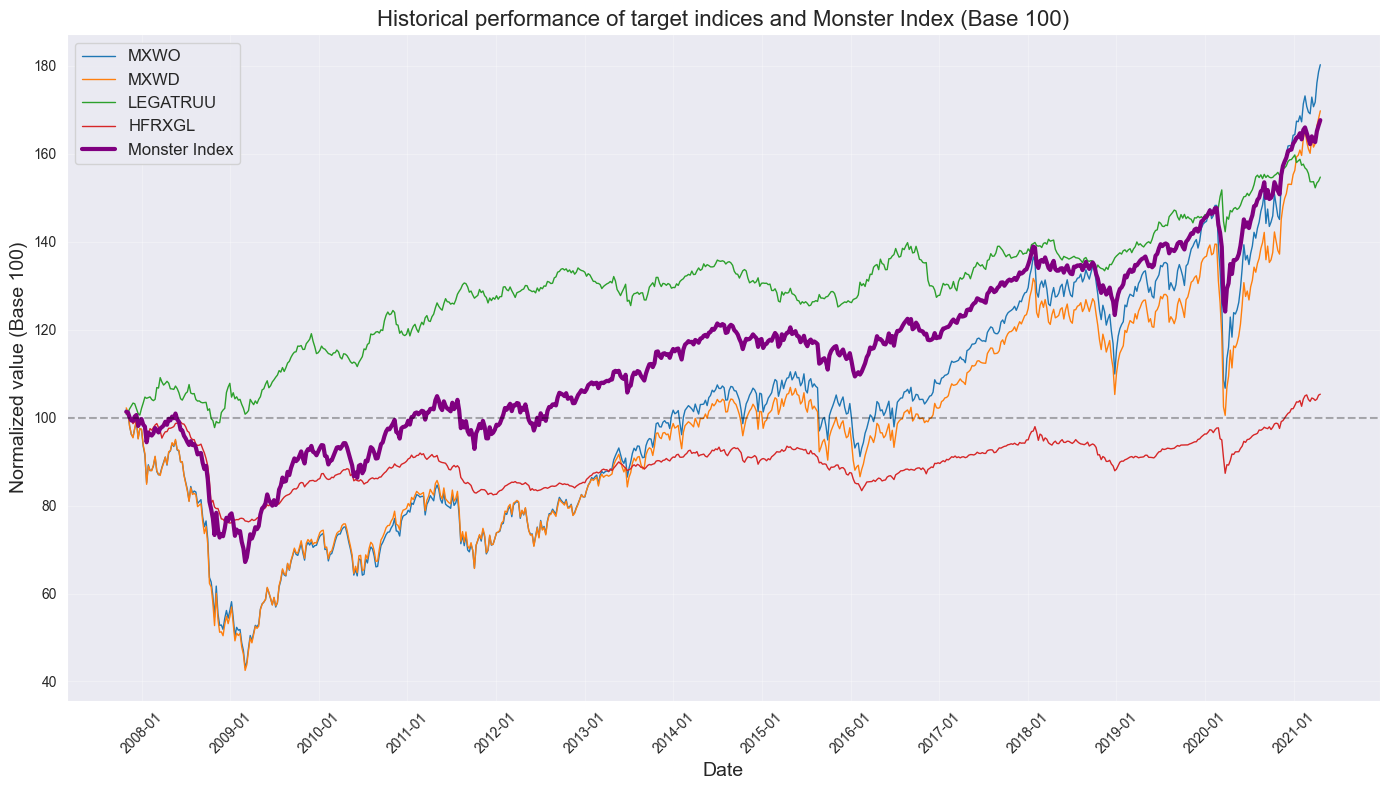

In [4]:
# Cumulative performance from returns, Base 100
index_plot = (1 + index_ret).cumprod() * 100

# Add Monster Index level
index_plot["Monster Index"] = monster_index_level

plt.figure(figsize=(14, 8))

for col in index_plot.columns:
    if col == "Monster Index":
        plt.plot(
            index_plot.index,
            index_plot[col],
            linewidth=3,
            color="purple",
            label=col
        )
    else:
        plt.plot(
            index_plot.index,
            index_plot[col],
            linewidth=1,
            label=col
        )

plt.title("Historical performance of target indices and Monster Index (Base 100)", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Normalized value (Base 100)", fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc="best", fontsize=12)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)

plt.axhline(y=100, color="black", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

We computed the **statistics** of the target Monster Index.

In [5]:
# Target index statistics

print("\nTarget index statistics:")

annual_factor = 52  # weekly data

# Use target returns, not the base-100 index level
mean_return = target.mean() * annual_factor
volatility = target.std() * np.sqrt(annual_factor)
sharpe_ratio = mean_return / volatility

# Cumulative performance and drawdown
cumulative_returns = (1 + target).cumprod()
drawdowns = 1 - cumulative_returns / cumulative_returns.cummax()
max_drawdown = drawdowns.max()

# Distribution statistics
skewness = target.skew()
kurtosis = target.kurtosis()

# Display statistics
stats_df = pd.DataFrame({
    "Statistic": [
        "Annualized return",
        "Annualized volatility",
        "Sharpe ratio",
        "Max Drawdown",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        f"{mean_return*100:.2f}%",
        f"{volatility*100:.2f}%",
        f"{sharpe_ratio:.2f}",
        f"{max_drawdown*100:.2f}%",
        f"{skewness:.2f}",
        f"{kurtosis:.2f}"
    ]
})

display(stats_df)


# Monthly return statistics

if len(target) >= 12:
    
    # Convert weekly returns into monthly compounded returns
    monthly_returns = target.resample("ME").apply(
        lambda x: (1 + x).prod() - 1
    )

    monthly_mean = monthly_returns.mean() * 12
    monthly_vol = monthly_returns.std() * np.sqrt(12)
    monthly_sharpe = monthly_mean / monthly_vol if monthly_vol > 0 else np.nan

    print("\nMonthly return statistics:")

    monthly_stats = pd.DataFrame({
        "Statistic": [
            "Annualized return (monthly)",
            "Annualized volatility (monthly)",
            "Sharpe ratio (monthly)"
        ],
        "Value": [
            f"{monthly_mean*100:.2f}%",
            f"{monthly_vol*100:.2f}%",
            f"{monthly_sharpe:.2f}"
        ]
    })

    display(monthly_stats)


Target index statistics:


,Statistic,Value
0,Annualized return,4.25%
1,Annualized volatility,9.27%
2,Sharpe ratio,0.46
3,Max Drawdown,33.71%
4,Skewness,-0.72
5,Kurtosis,5.80



Monthly return statistics:


,Statistic,Value
0,Annualized return (monthly),4.29%
1,Annualized volatility (monthly),9.76%
2,Sharpe ratio (monthly),0.44


### Futures Visualization and Analysis
We want to see each futures time series, but firstly we need to transforms futures returns (`futures_ret`) into a cumulative performance series, simulating an initial investment of 100 using the cumulative product of *((1 + r_t))* after we can finally use matplotlib to plot their normalized (base 100) evolution over time for easy comparison.


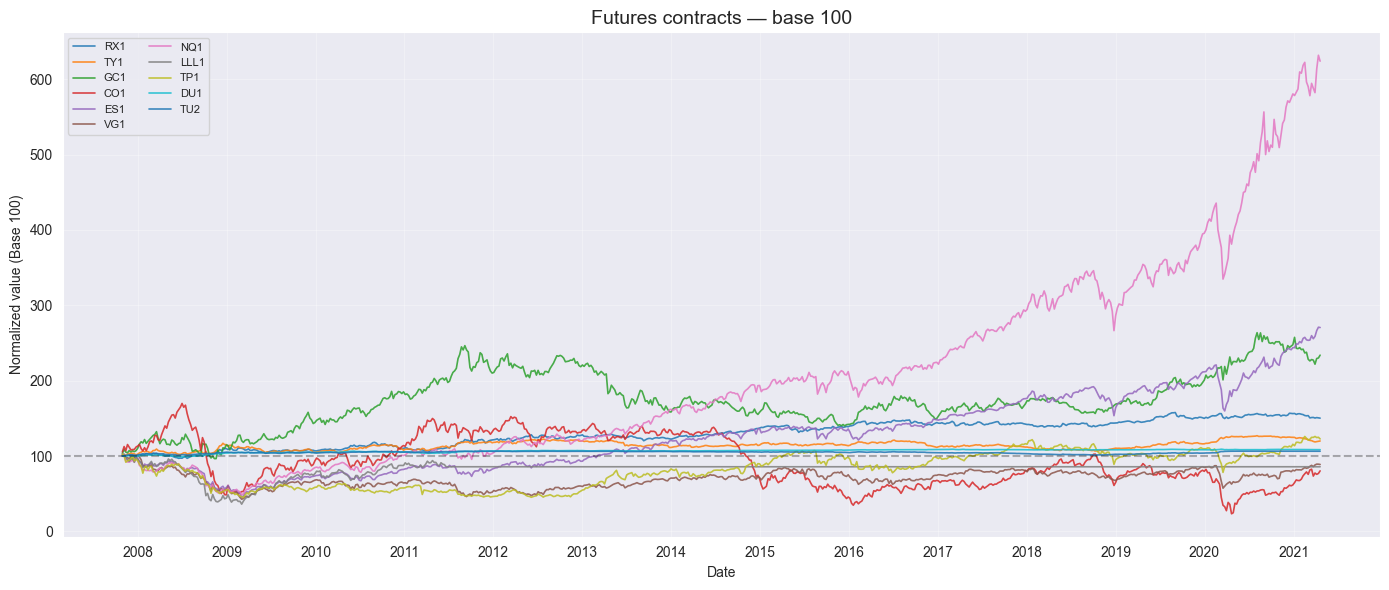

In [6]:
futures_plot = (1 + futures_ret).cumprod() * 100

plt.figure(figsize=(14, 6))

for col in futures_plot.columns:
    plt.plot(
        futures_plot.index,
        futures_plot[col],
        linewidth=1.2,
        alpha=0.85,
        label=col
    )

plt.title("Futures contracts — base 100", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Normalized value (Base 100)")
plt.legend(fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.axhline(y=100, color="black", linestyle="--", alpha=0.3)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
plt.show()

**Dead Future**

From the plot, LLL1 (MSCI Emerging Markets) becomes flat after a certain date, which is
unrealistic for an actively traded futures contract. This is likely due to data issues
(stale prices or missing data). We remove it from the analysis to avoid corrupting our
replication model.


In [7]:
# ── Remove dead futures (constant columns) ────────────────────────────────────

futures_const = []
for col in X.columns:
    differences = X[col].diff()
    if (differences == 0).sum() > 100:
        futures_const.append(col)

print("Removed futures (constant):", futures_const)

futures_ret = futures_ret.drop(columns=futures_const)
X           = X.drop(columns=futures_const)


Removed futures (constant): ['LLL1']


As we did before, we compute the **statistics** of the futures.

In [8]:
print("\nFutures return statistics:")

annual_factor = 52  # weekly data

futures_stats = pd.DataFrame(index=futures_ret.columns)

# Weekly statistics
futures_stats["Annualized return"] = futures_ret.mean() * annual_factor
futures_stats["Annualized volatility"] = futures_ret.std() * np.sqrt(annual_factor)
futures_stats["Sharpe ratio"] = (
    futures_stats["Annualized return"] / futures_stats["Annualized volatility"]
)

# Max drawdown
cumulative_returns = (1 + futures_ret).cumprod()
drawdowns = 1 - cumulative_returns / cumulative_returns.cummax()
futures_stats["Max Drawdown"] = drawdowns.max()

# Distribution
futures_stats["Skewness"] = futures_ret.skew()
futures_stats["Kurtosis"] = futures_ret.kurtosis()

# Format display
futures_stats_display = futures_stats.copy()
for col in ["Annualized return", "Annualized volatility", "Max Drawdown"]:
    futures_stats_display[col] = futures_stats_display[col].apply(lambda x: f"{x*100:.2f}%")

futures_stats_display["Sharpe ratio"] = futures_stats_display["Sharpe ratio"].apply(lambda x: f"{x:.2f}")
futures_stats_display["Skewness"] = futures_stats_display["Skewness"].apply(lambda x: f"{x:.2f}")
futures_stats_display["Kurtosis"] = futures_stats_display["Kurtosis"].apply(lambda x: f"{x:.2f}")

display(futures_stats_display)


# ============================================================
# Monthly statistics (per futures)
# ============================================================

if len(futures_ret) >= 12:

    # Convert weekly → monthly compounded returns
    monthly_returns = futures_ret.resample("ME").apply(
        lambda x: (1 + x).prod() - 1
    )

    monthly_mean = monthly_returns.mean() * 12
    monthly_vol = monthly_returns.std() * np.sqrt(12)
    monthly_sharpe = monthly_mean / monthly_vol

    monthly_stats = pd.DataFrame({
        "Annualized return (monthly)": monthly_mean,
        "Annualized volatility (monthly)": monthly_vol,
        "Sharpe ratio (monthly)": monthly_sharpe
    })

    # Format display
    monthly_stats_display = monthly_stats.copy()
    for col in ["Annualized return (monthly)", "Annualized volatility (monthly)"]:
        monthly_stats_display[col] = monthly_stats_display[col].apply(lambda x: f"{x*100:.2f}%")

    monthly_stats_display["Sharpe ratio (monthly)"] = monthly_stats_display["Sharpe ratio (monthly)"].apply(
        lambda x: f"{x:.2f}"
    )

    print("\nMonthly return statistics (futures):")
    display(monthly_stats_display)


Futures return statistics:


,Annualized return,Annualized volatility,Sharpe ratio,Max Drawdown,Skewness,Kurtosis
RX1,3.20%,6.14%,0.52,10.39%,-0.52,1.61
TY1,1.50%,5.63%,0.27,12.90%,-0.41,3.09
GC1,7.85%,17.72%,0.44,43.18%,0.05,3.47
CO1,6.51%,40.68%,0.16,86.26%,1.07,16.38
ES1,8.83%,17.01%,0.52,55.11%,-1.04,5.17
VG1,1.49%,21.70%,0.07,58.15%,-0.09,3.60
NQ1,15.46%,19.43%,0.80,52.00%,-0.94,3.92
TP1,4.10%,22.57%,0.18,56.29%,-0.68,5.15
DU1,0.60%,1.13%,0.54,2.77%,-0.24,5.20
TU2,0.46%,1.27%,0.36,4.72%,-0.09,4.62



Monthly return statistics (futures):


,Annualized return (monthly),Annualized volatility (monthly),Sharpe ratio (monthly)
RX1,3.16%,5.71%,0.55
TY1,1.50%,5.74%,0.26
GC1,7.68%,16.89%,0.45
CO1,7.66%,42.09%,0.18
ES1,8.77%,16.60%,0.53
VG1,1.27%,20.29%,0.06
NQ1,15.42%,19.15%,0.81
TP1,3.77%,20.91%,0.18
DU1,0.60%,1.11%,0.54
TU2,0.46%,1.26%,0.37


## Exploratory Data Analysis (EDA)

Before constructing the replication framework, it is important to understand the statistical properties of the underlying financial series.

**Financial motivation**  
Financial returns are characterised by stylised facts such as **fat tails, volatility clustering, weak autocorrelation, and regime instability**. Ignoring these properties may lead to unstable replication models and underestimated risk.

**Methodology**  
Throughout this section we investigate return distributions, dependence structures, and stationarity conditions. In finance, log-returns are commonly used:

$r_t = \log(1 + R_t)$

because they are additive through time and facilitate statistical modelling.

**Expected interpretation**  
The objective is to identify potential sources of model instability and justify the introduction of regime-aware and adaptive approaches.


### QQ plot 
Normality check

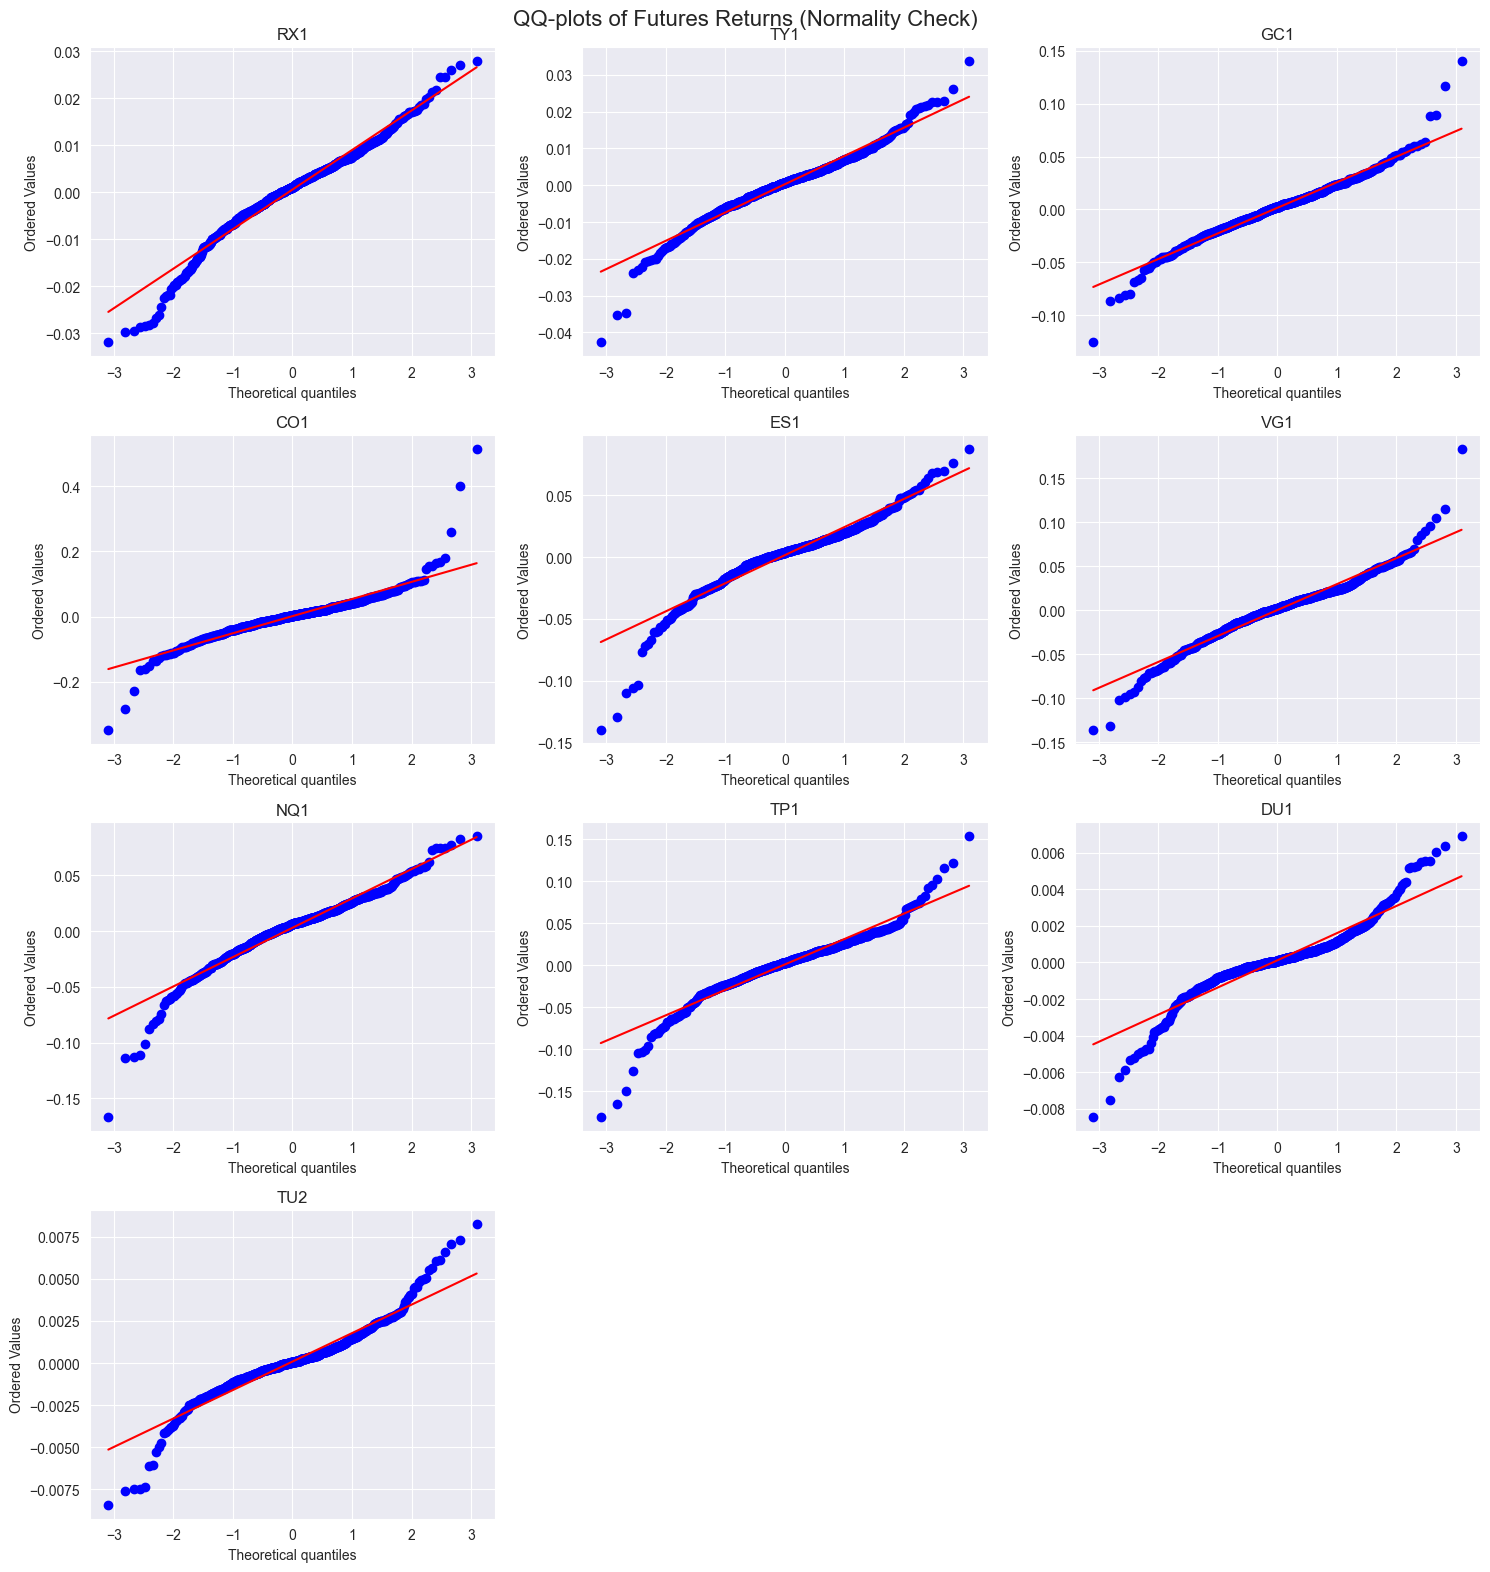

In [9]:
cols = futures_ret.columns
n = len(cols)

# Automatic grid layout
n_cols = 3
n_rows = math.ceil(n / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    stats.probplot(futures_ret[col], dist="norm", plot=axes[i])
    axes[i].set_title(col)

# Remove unused subplot axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("QQ-plots of Futures Returns (Normality Check)", fontsize=16)
plt.tight_layout()
plt.show()

The plots show a consistent pattern: returns follow the Gaussian line reasonably well in the centre but deviate systematically at both tails, the classic signature of **fat tails** and **excess kurtosis**.

### Autocorrelation

In [10]:
print("\nLjung-Box test for Autocorrelation (H0: No autocorrelation)")
for idx in TARGET_INDICES:
    # Get returns data for this index
    returns_data = returns[idx].dropna()

    # Perform Ljung-Box test for different lags
    lb_test = acorr_ljungbox(returns_data, lags=[5, 10, 15, 20], return_df=True)

    print(f"\n{idx}:")
    print(f"  Lag 5:  Test Statistic = {lb_test.iloc[0, 0]:.4f}, p-value = {lb_test.iloc[0, 1]:.4f}")
    print(f"  Lag 10: Test Statistic = {lb_test.iloc[1, 0]:.4f}, p-value = {lb_test.iloc[1, 1]:.4f}")
    print(f"  Lag 15: Test Statistic = {lb_test.iloc[2, 0]:.4f}, p-value = {lb_test.iloc[2, 1]:.4f}")
    print(f"  Lag 20: Test Statistic = {lb_test.iloc[3, 0]:.4f}, p-value = {lb_test.iloc[3, 1]:.4f}")

# Monster Index autocorrelation
lb_test = acorr_ljungbox(target.dropna(), lags=[5, 10, 15, 20], return_df=True)

print("\nMonster Index:")
print(f"  Lag 5:  Test Statistic = {lb_test.iloc[0, 0]:.4f}, p-value = {lb_test.iloc[0, 1]:.4f}")
print(f"  Lag 10: Test Statistic = {lb_test.iloc[1, 0]:.4f}, p-value = {lb_test.iloc[1, 1]:.4f}")
print(f"  Lag 15: Test Statistic = {lb_test.iloc[2, 0]:.4f}, p-value = {lb_test.iloc[2, 1]:.4f}")
print(f"  Lag 20: Test Statistic = {lb_test.iloc[3, 0]:.4f}, p-value = {lb_test.iloc[3, 1]:.4f}")


Ljung-Box test for Autocorrelation (H0: No autocorrelation)

MXWO:
  Lag 5:  Test Statistic = 3.7194, p-value = 0.5905
  Lag 10: Test Statistic = 16.3144, p-value = 0.0910
  Lag 15: Test Statistic = 27.3792, p-value = 0.0258
  Lag 20: Test Statistic = 31.2372, p-value = 0.0521

MXWD:
  Lag 5:  Test Statistic = 4.0704, p-value = 0.5393
  Lag 10: Test Statistic = 17.4323, p-value = 0.0653
  Lag 15: Test Statistic = 28.4624, p-value = 0.0188
  Lag 20: Test Statistic = 32.0118, p-value = 0.0432

LEGATRUU:
  Lag 5:  Test Statistic = 8.3823, p-value = 0.1364
  Lag 10: Test Statistic = 11.6799, p-value = 0.3071
  Lag 15: Test Statistic = 23.8265, p-value = 0.0681
  Lag 20: Test Statistic = 26.5486, p-value = 0.1484

HFRXGL:
  Lag 5:  Test Statistic = 63.9540, p-value = 0.0000
  Lag 10: Test Statistic = 90.7371, p-value = 0.0000
  Lag 15: Test Statistic = 94.7913, p-value = 0.0000
  Lag 20: Test Statistic = 96.3138, p-value = 0.0000

Monster Index:
  Lag 5:  Test Statistic = 2.7143, p-value =

The **Ljung-Box test** reveals that equity indices (*MXWO, MXWD*) exhibit weak autocorrelation at longer lags, while bond returns (*LEGATRUU*) behave as approximately white noise. In contrast, the hedge fund index (*HFRXGL*) shows strong and persistent autocorrelation across all lags, likely due to return smoothing and illiquidity effects.
The *Monster Index* inherits these dynamics: it does not display significant autocorrelation at short lags, but shows statistically significant dependence at longer horizons. This suggests that the serial correlation in the target portfolio is primarily driven by the hedge fund component.

While the *Ljung-Box test* on raw returns allows us to detect **linear autocorrelation**, financial time series are often characterized by little or no serial dependence in returns but strong dependence in their variance.
For this reason, we extend the analysis to squared returns in order to detect **volatility clustering**, a typical feature of financial markets.

In [11]:
print("\nLjung-Box test on squared returns (H0: No volatility clustering)")

series_dict = {idx: returns[idx].dropna() for idx in TARGET_INDICES}
series_dict["Monster_Index"] = target.dropna()

for name, returns_data in series_dict.items():

    squared_returns = returns_data ** 2

    lb_test = acorr_ljungbox(
        squared_returns,
        lags=[5, 10, 15, 20],
        return_df=True
    )

    print(f"\n{name}:")
    print(f"  Lag 5:  Test Statistic = {lb_test.iloc[0, 0]:.4f}, p-value = {lb_test.iloc[0, 1]:.4f}")
    print(f"  Lag 10: Test Statistic = {lb_test.iloc[1, 0]:.4f}, p-value = {lb_test.iloc[1, 1]:.4f}")
    print(f"  Lag 15: Test Statistic = {lb_test.iloc[2, 0]:.4f}, p-value = {lb_test.iloc[2, 1]:.4f}")
    print(f"  Lag 20: Test Statistic = {lb_test.iloc[3, 0]:.4f}, p-value = {lb_test.iloc[3, 1]:.4f}")


Ljung-Box test on squared returns (H0: No volatility clustering)

MXWO:
  Lag 5:  Test Statistic = 211.1054, p-value = 0.0000
  Lag 10: Test Statistic = 251.0168, p-value = 0.0000
  Lag 15: Test Statistic = 278.8264, p-value = 0.0000
  Lag 20: Test Statistic = 305.3757, p-value = 0.0000

MXWD:
  Lag 5:  Test Statistic = 222.4478, p-value = 0.0000
  Lag 10: Test Statistic = 263.7733, p-value = 0.0000
  Lag 15: Test Statistic = 293.5273, p-value = 0.0000
  Lag 20: Test Statistic = 322.3021, p-value = 0.0000

LEGATRUU:
  Lag 5:  Test Statistic = 41.9028, p-value = 0.0000
  Lag 10: Test Statistic = 49.0560, p-value = 0.0000
  Lag 15: Test Statistic = 59.5191, p-value = 0.0000
  Lag 20: Test Statistic = 63.6496, p-value = 0.0000

HFRXGL:
  Lag 5:  Test Statistic = 170.0339, p-value = 0.0000
  Lag 10: Test Statistic = 171.3709, p-value = 0.0000
  Lag 15: Test Statistic = 171.8963, p-value = 0.0000
  Lag 20: Test Statistic = 174.1465, p-value = 0.0000

Monster_Index:
  Lag 5:  Test Statistic

The *Ljung-Box test* on squared returns strongly rejects the null hypothesis of no autocorrelation for all indices and at all lags.
This provides clear evidence of v*olatility clustering*, a well-known stylized fact of financial time series.
In particular, periods of high volatility tend to be followed by high volatility, and periods of low volatility tend to persist over time.
This behavior is observed not only in equity indices (*MXWO, MXWD*), but also in bonds (*LEGATRUU*), hedge funds (*HFRXGL*), and consequently in the *Monster Index* itself. 

The presence of *volatility clustering* in all components implies that the *Monster Index* inherits this feature as well, confirming that the target portfolio exhibits persistent volatility dynamics.

Although returns themselves are only **weakly autocorrelated**, the conditional variance is clearly time-varying. This empirical evidence naturally motivates the use of **GARCH-type models**, which are specifically designed to capture *volatility clustering* through a dynamic specification of the conditional variance. 

### Stationarity

In [12]:
print("\nADF Test for Stationarity (H0: Non-stationary)")

series_dict = {idx: returns[idx].dropna() for idx in TARGET_INDICES}
series_dict["Monster_Index"] = target.dropna()

for name, series in series_dict.items():

    adf_result = adfuller(series)

    print(f"\n{name}:")
    print(f"  ADF Statistic = {adf_result[0]:.4f}")
    print(f"  p-value       = {adf_result[1]:.4f}")

print("\nPhillips-Perron Test (H0: Non-stationary)")

series_dict = {idx: returns[idx].dropna() for idx in TARGET_INDICES}
series_dict["Monster_Index"] = target.dropna()

for name, series in series_dict.items():

    pp_test = PhillipsPerron(series)

    print(f"\n{name}:")
    print(f"  Test Statistic = {pp_test.stat:.4f}")
    print(f"  p-value        = {pp_test.pvalue:.4f}")


ADF Test for Stationarity (H0: Non-stationary)

MXWO:
  ADF Statistic = -6.2776
  p-value       = 0.0000

MXWD:
  ADF Statistic = -6.2162
  p-value       = 0.0000

LEGATRUU:
  ADF Statistic = -13.1936
  p-value       = 0.0000

HFRXGL:
  ADF Statistic = -11.8098
  p-value       = 0.0000

Monster_Index:
  ADF Statistic = -25.8227
  p-value       = 0.0000

Phillips-Perron Test (H0: Non-stationary)

MXWO:
  Test Statistic = -26.4955
  p-value        = 0.0000

MXWD:
  Test Statistic = -26.4904
  p-value        = 0.0000

LEGATRUU:
  Test Statistic = -26.1396
  p-value        = 0.0000

HFRXGL:
  Test Statistic = -23.4496
  p-value        = 0.0000

Monster_Index:
  Test Statistic = -25.9700
  p-value        = 0.0000


The **Augmented Dickey-Fuller test** strongly rejects the null hypothesis of non-stationarity for all return series, confirming that the data are **stationary in mean**. This is consistent with standard financial theory and justifies the use of *linear regression* models. The **Phillips-Perron tes**t, which is robust to heteroskedasticity, provides consistent results, further reinforcing the evidence of stationarity despite the presence of *volatility clustering*.

## Construction of a Linear Futures Replication Portfolio

The goal of this section is to build a linear replication portfolio for the target asset.

At each date, the target return is approximated as a linear combination of futures returns:

$$
r^{replica}_t = X_t w
$$

where $X_t$ contains the futures returns and $w$ is the vector of portfolio weights.

To compute the weights, the following methods were used:

* [Soft Markov Switching Elastic Net](#Soft-Markov-Switching-Elastic-Net-MS-EN)
* [Kalman Filter](#Kalman-Filter-Dynamic-Replication-Model)

These methods were later combined through [Soft Bayesian Stacking](#Soft-Bayesian-Stacking), with the aim of optimising the evaluation metrics.

 After testing several configurations of the simple Elastic Net and the basic Kalman — varying hyperparameters across different specifications and exploring an alternative pooling approach from O'Doherty et al. — we concluded that the methods selected above were the ones that performed best.  Since regime-based models consistently outperformed single-specification alternatives, we structured our final methodology around regime detection, leading to the Markov Switching EN and the HMM-augmented Kalman as our final choices. All intermediate attempts and discarded models can be found in the "Failed Attempts" notebook.

**N.B.** In all these methods, we imposed one of the UCITS constraints: either a maximum 1M VaR at 99% or a maximum leverage of 200%.

### Data Preparation

The target return series is stored in `y`.
The futures return matrix is aligned with the target dates, so that each row of `X` corresponds to the same date as the corresponding observation in `y`.


In [13]:
# Target returns
y = target.copy()

# Futures returns aligned with target
X = futures_ret.loc[y.index].copy()

X_values = X.values
y_values = y.values
dates_array = X.index.to_numpy()

#### **Shared helper functions**

##### ONLINE BAYESIAN HMM — Dirichlet / Normal-Gamma Filter

Markets alternate between calm and turbulent regimes, so treating all
observations equally may hurt out-of-sample performance (*no leakage*).

To capture this behavior, we use a two-state **Hidden Markov Model (HMM)**
with Bayesian online updates:

* A **Dirichlet posterior** models regime persistence.
* A **Normal-Gamma posterior** models regime-specific mean and variance.

The priors are initialized from **Baum–Welch** estimates on the first
104 weeks (same initialization both for Kalman Filter and for Elastic
Net windows), then updated sequentially without further EM iterations.

The model outputs the causal probability

$$
P(\text{volatile} \mid \text{data up to } t)
$$

computed without lookahead bias.

This framework is integrated to improve the *Elastic Net* and the
*Kalman Filter* models (see the failed-attempt notebook).


In [14]:
# ════════════════════════════════════════════════════════════════════
# BW-HMM HELPERS  
# ════════════════════════════════════════════════════════════════════
def baum_welch(obs, n_states=2, max_iter=200, tol=1e-6, seed=42):
    """
    Fit a 2-state Gaussian HMM via Baum-Welch EM.
    State 0 = quiet (low vol), State 1 = volatile (high vol) by convention.

    Returns
    -------
    dict: A, pi, mu, sigma, gamma
    """
    T = len(obs)
    sq = obs ** 2 # proxy for variance

    # Divide the observation based on low/high volatility

    km  = KMeans(n_clusters=n_states, n_init=10, max_iter=500,
                 random_state=seed).fit(sq.reshape(-1, 1))
    lbl = km.labels_

    # Gaussian parameters for each cluster

    mu    = np.array([obs[lbl == s].mean() if (lbl == s).any() else 0.0
                      for s in range(n_states)])
    sigma = np.array([obs[lbl == s].std()  if (lbl == s).any() else 1e-4
                      for s in range(n_states)])

    # Enforce label convention: state 0 = quiet (lower sigma)

    if sigma[0] > sigma[1]:
        mu, sigma = mu[::-1].copy(), sigma[::-1].copy()

    A  = np.array([[0.95, 0.05], [0.05, 0.95]], dtype=float)
    pi = np.full(n_states, 1.0 / n_states)
    ll_prev = -np.inf

    # EM loop

    for itr in range(max_iter):

        # B[t, s] = p(obs[t] | state s) under the current Gaussian N(mu[s], sigm[s]).

        B = np.column_stack(
            [norm.pdf(obs, mu[s], max(sigma[s], 1e-300))
             for s in range(n_states)]
        )
        B = np.maximum(B, 1e-300)

        # Forward pass
        # alpha[t, s] = P(state s at t | obs[0..t]), computed recursively
        # Scaling by c[t] = sum_s(alpha[t, s]) avoids numerical underflow

        alpha, c = np.zeros((T, n_states)), np.zeros(T)
        alpha[0] = pi * B[0]
        c[0]        = max(alpha[0].sum(), 1e-300)
        alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t-1] @ A) * B[t]
            c[t]        = max(alpha[t].sum(), 1e-300)
            alpha[t] /= c[t]

        # Backward pass
        # beta[t, s] = P(obs[t+1..T] | state s at t), computed right-to-left

        beta = np.ones((T, n_states))
        for t in range(T - 2, -1, -1):
            beta[t] = (A @ (B[t+1] * beta[t+1])) / max(c[t+1], 1e-300)

        # Smoothed state probabilities
        # gamma[t, s] = P(state s at t | all observations)

        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)

        # xi[t, i, j] = P(state i at t, state j at t+1 | all observations)

        xi = np.zeros((T-1, n_states, n_states))
        for t in range(T-1):
            num   = alpha[t][:, None] * A * (B[t+1] * beta[t+1])[None, :]
            xi[t] = num / max(num.sum(), 1e-300)

        ll = np.log(c).sum()

        # M-step: update parameters as responsibility-weighted statistics

        pi = gamma[0]
        for j in range(n_states):
            rs   = max(xi[:, j, :].sum(), 1e-300)
            A[j] = xi[:, j, :].sum(axis=0) / rs
            A[j] /= A[j].sum()
        for s in range(n_states):
            gs       = max(gamma[:, s].sum(), 1e-300)
            mu[s]    = (gamma[:, s] * obs).sum() / gs
            sigma[s] = max(
                np.sqrt((gamma[:, s] * (obs - mu[s])**2).sum() / gs), 1e-6
            )

        # Re-enforce label convention
        if sigma[0] > sigma[1]:
            mu, sigma = mu[::-1].copy(), sigma[::-1].copy()
            gamma     = gamma[:, ::-1].copy()
            A         = A[::-1, ::-1].copy()
            pi        = pi[::-1].copy()

        if abs(ll - ll_prev) < tol:
            break
        ll_prev = ll

    return dict(A=A, pi=pi, mu=mu, sigma=sigma, gamma=gamma)

In [15]:
def online_bayesian_hmm(
    y_all,
    A0,
    mu0,
    sig0,
    rolling_window,
    n_states    = 2,
    kappa_dir   = 10.0,
    kappa_ng    = 5.0,
    a0          = 3.0,
):
    T = len(y_all)

    # ── Initialise Dirichlet prior from Baum-Welch transition matrix ──────────

    alpha_dir = np.maximum(A0, 1e-8) * kappa_dir
    alpha_dir = alpha_dir / alpha_dir.sum(axis=1, keepdims=True) * kappa_dir

    # ── Initialise Normal-Gamma prior from Baum-Welch emission estimates ──────

    ng_m     = mu0.copy()
    ng_kappa = np.full(n_states, kappa_ng)
    ng_a     = np.full(n_states, a0)
    ng_b     = a0 * sig0 ** 2

    # ── Storage ───────────────────────────────────────────────────────────────

    alpha   = np.zeros((T, n_states))
    hmm_var = np.zeros(T)

    # ── Training block: self-contained forward filter from t=0 ───────────────

    alpha_prev = np.full(n_states, 1.0 / n_states)

    for t in range(rolling_window):
        post_var = ng_b / np.maximum(ng_a - 1, 1e-6)
        pred_var = post_var * (1.0 + 1.0 / ng_kappa)
        pred_std = np.maximum(np.sqrt(pred_var), 1e-300)
        B_t = np.maximum(
            np.array([norm.pdf(y_all[t], ng_m[s], pred_std[s]) for s in range(n_states)]),
            1e-300)
        alpha_upd      = alpha_prev * B_t
        alpha_upd     /= max(alpha_upd.sum(), 1e-300)
        alpha[t]       = alpha_upd
        hmm_var[t]     = alpha_upd @ pred_var
        alpha_prev     = alpha_upd

    # ── Online filter ─────────────────────────────────────────────────────────
    for t in range(rolling_window, T):
        y_t = y_all[t]

        # Step 1: predictive quantities (before seeing y_t — leakage guard)
        post_var = ng_b / np.maximum(ng_a - 1, 1e-6)
        pred_var = post_var * (1.0 + 1.0 / ng_kappa)
        pred_std = np.maximum(np.sqrt(pred_var), 1e-300)

        A_post       = alpha_dir / np.maximum(alpha_dir.sum(axis=1, keepdims=True), 1e-300)
        alpha_pred   = alpha_prev @ A_post
        hmm_var[t] = alpha_pred @ pred_var

        # Step 2: forward filter update
        B_t = np.maximum(
            np.array([norm.pdf(y_t, ng_m[s], pred_std[s]) for s in range(n_states)]),
            1e-300)
        alpha_upd      = alpha_pred * B_t
        alpha_upd     /= max(alpha_upd.sum(), 1e-300)
        alpha[t]     = alpha_upd
        gamma_t        = alpha_upd

        # Step 3: Dirichlet update
        xi_t_num   = alpha_prev[:, None] * A_post * B_t[None, :]
        xi_t       = xi_t_num / max(xi_t_num.sum(), 1e-300)
        alpha_dir += xi_t

        # Step 4: Normal-Gamma update
        for s in range(n_states):
            g_s         = gamma_t[s]
            k_old       = ng_kappa[s]
            m_old       = ng_m[s]
            ng_kappa[s] = k_old + g_s
            ng_m[s]     = (k_old * m_old + g_s * y_t) / ng_kappa[s]
            ng_a[s]    += g_s / 2.0
            ng_b[s]    += 0.5 * g_s * (k_old / ng_kappa[s]) * (y_t - m_old) ** 2

        alpha_prev = alpha_upd

    prob_vol = alpha[:, 1]

    return prob_vol, alpha, hmm_var

##### Evaluation Metrics
`perf_metrics` computes the standard replication diagnostics — correlation, TEV, information ratio, MSE, turnover, and transaction costs — and prints a formatted summary for easy comparison across models.

In [16]:
def perf_metrics_clean(r_replica, r_target, b_weights=None, tc_arr=None,
                       label="Model", transaction_cost_rate=0.0004,
                       verbose=True):
    """
    Unified performance metrics for replication strategies.
    Used consistently across MS-EN, Kalman and Stack to guarantee
    cross-model comparability.

    Convention: pandas Series, ddof=1 for standard deviations,
    annualisation factor = 52 (weekly data).
    """
    ANN = 52

    # ── Convert and align via index intersection ──────────────────────
    r_rep = pd.Series(r_replica).copy().dropna()
    r_tgt = pd.Series(r_target).copy().dropna()
    common = r_rep.index.intersection(r_tgt.index)
    r_rep  = r_rep.loc[common]
    r_tgt  = r_tgt.loc[common]

    n_obs = len(r_rep)
    if n_obs < 5:
        if verbose:
            print(f"\n--- {label} ---  Insufficient observations (n={n_obs})")
        return {'label': label, 'n_obs': n_obs}

    # ── Tracking error ────────────────────────────────────────────────
    te = r_rep - r_tgt

    # ── Annualised return / vol ───────────────────────────────────────
    ann_ret_rep = r_rep.mean() * ANN
    ann_ret_tgt = r_tgt.mean() * ANN
    ann_vol_rep = r_rep.std(ddof=1) * np.sqrt(ANN)
    ann_vol_tgt = r_tgt.std(ddof=1) * np.sqrt(ANN)

    # ── Tracking metrics ──────────────────────────────────────────────
    tev = te.std(ddof=1) * np.sqrt(ANN)
    ir  = (te.mean() * ANN) / tev if tev > 0 else np.nan

    # ── Fit statistics ────────────────────────────────────────────────
    mse  = (te ** 2).mean()
    rmse = np.sqrt(mse)
    corr = r_rep.corr(r_tgt)

    # ── Risk-adjusted return ──────────────────────────────────────────
    sharpe_rep = ann_ret_rep / ann_vol_rep if ann_vol_rep > 0 else np.nan
    sharpe_tgt = ann_ret_tgt / ann_vol_tgt if ann_vol_tgt > 0 else np.nan

    # ── Drawdown ──────────────────────────────────────────────────────
    cum_rep = (1 + r_rep).cumprod()
    cum_tgt = (1 + r_tgt).cumprod()
    max_dd_rep = (1 - cum_rep / cum_rep.cummax()).max()
    max_dd_tgt = (1 - cum_tgt / cum_tgt.cummax()).max()

    # ── Turnover & transaction costs ──────────────────────────────────
    if b_weights is not None and len(b_weights) > 1:
        w_arr = np.asarray(b_weights)
        weight_changes = np.sum(np.abs(np.diff(w_arr, axis=0)), axis=1)
        annual_turnover = weight_changes.mean() / 2.0 * ANN
    else:
        annual_turnover = np.nan

    if tc_arr is not None and len(tc_arr) > 0:
        tc_np      = np.asarray(tc_arr)
        n_years    = len(tc_np) / ANN
        avg_tc_bps = tc_np.mean() * 1e4
        yearly_tc  = tc_np.sum() / n_years * 1e4 if n_years > 0 else np.nan
    else:
        if np.isfinite(annual_turnover):
            yearly_tc  = annual_turnover * transaction_cost_rate * 1e4
            avg_tc_bps = yearly_tc / ANN
        else:
            yearly_tc  = np.nan
            avg_tc_bps = np.nan

    # ── Result dict ───────────────────────────────────────────────────
    result = {
        'label':           label,
        'n_obs':           n_obs,
        'corr':            corr,
        'tev':             tev,
        'ir':              ir,
        'mse':             mse,
        'rmse':            rmse,
        'sharpe_rep':      sharpe_rep,
        'sharpe_tgt':      sharpe_tgt,
        'ann_ret_rep':     ann_ret_rep,
        'ann_ret_tgt':     ann_ret_tgt,
        'ann_vol_rep':     ann_vol_rep,
        'ann_vol_tgt':     ann_vol_tgt,
        'max_dd_rep':      max_dd_rep,
        'max_dd_tgt':      max_dd_tgt,
        'annual_turnover': annual_turnover,
        'avg_tc_bps':      avg_tc_bps,
        'yearly_tc_bps':   yearly_tc,
    }

    if verbose:
        print(f"\n--- {label} ---")
        print(f"  N obs              : {n_obs}")
        print(f"  Correlation        : {corr:.4f}")
        print(f"  TEV (ann.)         : {tev*100:.2f}%")
        print(f"  Information Ratio  : {ir:.4f}")
        print(f"  MSE                : {mse:.2e}")
        print(f"  Sharpe (replica)   : {sharpe_rep:.3f}")
        print(f"  Sharpe (target)    : {sharpe_tgt:.3f}")
        print(f"  Ann. Return (rep)  : {ann_ret_rep*100:.2f}%")
        print(f"  Ann. Vol (rep)     : {ann_vol_rep*100:.2f}%")
        print(f"  Max DD (rep)       : {max_dd_rep*100:.1f}%")
        print(f"  Max DD (tgt)       : {max_dd_tgt*100:.1f}%")
        if np.isfinite(annual_turnover):
            print(f"  Annual Turnover    : {annual_turnover:.2f}x")
        if np.isfinite(avg_tc_bps):
            print(f"  Avg TC per step    : {avg_tc_bps:.2f} bps")
            print(f"  Yearly TC avg      : {yearly_tc:.2f} bps")

    return result

### Why could regime detection improve portfolio replication?

**Financial motivation**  
Financial markets are structurally unstable. Volatility, correlations, and factor sensitivities evolve through time, particularly during periods of stress. A static model implicitly assumes that market relationships remain constant, which is rarely realistic.

Examples include:

- low-volatility expansion periods,
- crisis-driven market dislocations,
- inflationary or recessionary transitions.

**Methodological implication**  
To account for this non-stationary behaviour, a **Markovian regime framework** is introduced. Market conditions are assumed to evolve across latent states, where transitions are governed probabilistically.

**Expected benefit**  
Conditioning replication on market regimes may improve tracking stability, reduce estimation noise, and enhance robustness during periods of structural change.


For semplicity, the two regimes we considered are: 

| State | Label | Interpretation |
|-------|-------|----------------|
| 0 | Quiet / Low Vol | Low volatility, trending markets |
| 1 | Volatile / High Vol | High volatility, drawdown periods |

### SOFT MARKOV SWITCHING ELASTIC NET (MS-EN)

#### Table of Contents

1. [Overview](#Overview)
2. [Parameters & Hyperparameters](#Parameters-&-Hyperparameters)
3. [Adaptive Weighting](#Adaptive-Weighting)
4. [Substantial VaR](#Substantial-VaR)
5. [VIF-based Feature Selection](#VIF-based-Feature-Selection)
6. [ElasticNet Fit](#ElasticNet-Fit)
7. [Time-series cross-validation](#Time-series-cross-validation)
8. [Soft Markov Switching Elastic Net Loop](#Soft-Markov-Switching-Elastic-Net-Loop)
9. [Performance metrics & plots](#Performance-metrics-&-plots)

##### 1. Overview
--------
We implement a regime-aware fund replication strategy that combines:
  - **ElasticNet regression** for portfolio weight estimation
  - A **Baum-Welch Hidden Markov Model** to detect low-vol/high-vol market regimes
  - Smooth blending of two regime-conditional EN models

The core idea: rather than fitting a single static model, we train separate
ElasticNet models emphasising low-vol vs. high-vol observations, then blend their
weights proportionally to the current filtered regime probability. This allows
the replica to adapt its factor exposures dynamically as market conditions shift.

At each rolling step:

1. **baum_welch** is fit on the current training window to estimate transition matrix A, emission means μ and standard deviations σ.
2. Continuous filtered probabilities P(high-vol|t) for every observation in the window are computed using **online_bayesian_hmm**.
3. **Regime-conditional sample weights** (`regime_sample_weights`): two weight vectors are built by combining the continuous regime probabilities with the Dirichlet adaptive decay — one emphasising low-vol periods, one emphasising high-vol periods.
4. **Two EN models** are fit on the same data but with different sample weights:
   - `EN_low_vol`: weighted by P(low-vol|t) × Dirichlet decay — full GRID_LOW_VOL
   - `EN_high_vol`: weighted by P(high-vol|t) × Dirichlet decay — restricted GRID_HIGH_VOL
5. **Smooth blending**: $w_{MS} = p_{\text{low-vol}} \cdot w_{\text{low-vol}} + (1-p_{\text{low-vol}}) \cdot w_{\text{high-vol}}$, where $p_{\text{low-vol}}$ is the mean filtered probability over the last 4 weeks.
6. **Risk controls** (every week): turnover gate, leverage cap, VaR constraint.
--------

##### 2. Parameters & Hyperparameters
| Parameter | Value     | Meaning                                                              |
|-----------|-----------|----------------------------------------------------------------------|
| `MS_ROLL_WIN` | 104 weeks | ~2 years training window                                             |
| `MS_REBAL_FREQ` | 4 weeks   | monthly rebalancing                                                  |
| `MS_MIN_OBS` | 20        | minimum obs per regime for valid fit                                 |
| `MS_MAX_LEV` | 2.0×      | gross leverage cap                                                   |
| `MS_TC` | 4 bps     | round-trip transaction cost                                          |
| `USE_BW_REGIME` | True      | use Baum-Welch + forward filter (vs simple Bayesian filter fallback) |

In [17]:
# ── Soft Markov Switching EN Parameters ───────────────────────────────────────────

MS_ROLL_WIN   = 104     # rolling training window (weeks, ~2 years)
MS_REBAL_FREQ = 4      # rebalancing frequency (weeks, ~monthly)
MS_MIN_OBS    = 20     # minimum obs per regime; otherwise fallback to plain EN
MS_MAX_LEV    = 2.0    # gross leverage cap  [same as EN base]
MS_TC         = 0.0004 # round-trip cost per unit of one-way turnover (4 bps)
MS_TO_THRESH  = 0.03   # turnover gate threshold
VOTE_WINDOW     = 4      # majority vote over last N weeks

# ── BW HMM switch ────────────────────────────────────────────────────────────
# True  → use Baum-Welch EM + causal forward filter
# False → fall back to detect_vol_regime (simple Hamilton-style Bayesian filter)
USE_BW_REGIME = True
BW_MIN_TRAIN  = 52     # minimum training obs before attempting BW fit


The model tests different combinations of:

- `alpha`, which controls the overall strength of the Elastic Net penalty;
- `l1_ratio`, which controls the balance between Lasso and Ridge regularization: l1_ratio=0 -> **Ridge regression**; l1_ratio=1-> **Lasso regression**.

The search grid is conditioned on the detected market regime. In **low-volatility regimes**, a broad grid is explored across the full Lasso-Ridge spectrum, allowing maximum flexibility. In **high-volatility regimes**, the grid is restricted to higher alphas and l1_ratios (0.6–1.0), favouring sparser, more conservative solutions when signal quality is lower and noise is elevated.

Hyperparameters are re-selected at each `rebalancing event`,  governing the trade-off between **turnover** — shorter intervals allow faster adaptation but increase transaction costs — and **stability** — longer intervals reduce unnecessary rebalancing but may lag regime changes


In [18]:
alphas = [0.0001, 0.001, 0.01, 0.1, 0.5]
l1_ratios = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# ── Regime-conditional hyperparameter grids ───────────────────────────────────
# Low Vol regime: full grid, more flexibility
GRID_LOW_VOL = {
    'alphas'    : [0.0001, 0.001, 0.01, 0.1, 0.5],
    'l1_ratios' : [0.0, 0.2, 0.4, 0.6, 0.8],   # excludes pure LASSO -> more stable
}

# High Vol regime: stronger regularisation, sparse and controlled selection
GRID_HIGH_VOL = {
    'alphas'    : [0.001, 0.01, 0.1, 0.5],
    'l1_ratios' : [0.6, 0.8, 1.0],
}

# ── Rebalancing frequency ─────────────────────────────────────────────────────
REBAL_FREQ = 4   #weeks

##### 3. Adaptive Weighting
  A standard OLS fit treats a return from 4 years ago identically to last
   week's. In a time-varying market, stale observations can dilute the signal
   from recent data and produce portfolio weights that are slow to adapt.

 Solution: exponential down-weighting — observations decay in influence as
   they age, so the model concentrates on the most recent, relevant history.

       weight of observation at lag k  ∝  decay^k
       decay = 0.5^(1 / half_life)
  So rather than implementing a 
   fixed half_life (simple, but ignores how turbulent
   or stable the current market environment actually is), 
 we opted for an
   adaptive half_life ( inferred directly from the recent
   activity level of the return series itself ): 

       High activity (turbulent)  →  short half_life  →  trust only recent data
       Low  activity (calm)       →  long  half_life  →  draw on more history

In [19]:
# ── Adaptive parameters ──────────────────────────────────────────────────────
USE_ADAPTIVE_REGIME  = True
ADAPTIVE_HALF_LIVES  = [4, 26, 52]   # fast / medium / slow decay
ADAPTIVE_ALPHA       = 1.0
HALF_LIFE_MIN        = 4
HALF_LIFE_MAX        = 78

In [20]:
# ── Adaptive half-life ────────────────────────────────────────────────────────
def compute_adaptive_regime_weights(y_train):
    """
    Infer a data-adaptive EWM half-life from the recent activity of y_train.

    Compares mean absolute returns across three nested sub-windows:
      - 1/6 × T  (short)  : captures the most recent volatility spikes
      - 1/2 × T  (medium) : medium-term activity level
      - 1/1 × T  (full)   : long-run baseline

    The three activity levels are softmax-normalised (raised to ADAPTIVE_ALPHA
    then divided by their sum) to form a probability vector, which is then
    dot-producted with the candidate half-lives [4, 26, 52] weeks:

      High recent activity → short window dominates → half_life ≈ 4w
      Low,  stable activity → weights spread evenly → half_life ≈ 52w

    The result is clipped to [HALF_LIFE_MIN, HALF_LIFE_MAX].

    Parameters
    ----------
    y_train : array-like, shape (T,)
        In-sample target returns for the current training window.

    Returns
    -------
    half_life : int
        Chosen half-life in weeks, clipped to [HALF_LIFE_MIN, HALF_LIFE_MAX].
    """
    T             = len(y_train)
    fractions     = [1/6, 1/2, 1.0]
    windows       = [max(4, int(T * f)) for f in fractions]
    activity      = np.array([np.mean(np.abs(y_train[-w:])) for w in windows])
    concentration = activity ** ADAPTIVE_ALPHA
    activity_probs  = concentration / (concentration.sum() + 1e-8)
    half_life     = int(np.clip(
        np.dot(activity_probs, ADAPTIVE_HALF_LIVES),
        HALF_LIFE_MIN, HALF_LIFE_MAX
    ))
    return half_life


# ── Regime-conditional sample weights for MS-EN ───────────────────────────────
def regime_sample_weights(high_vol_probs_col, y_train):
    """
    Compute sample weights for one EN model in the MS-EN loop.

    Combines:
      - high_vol_probs_col : continuous P(high_vol|t) or P(low_vol|t) from the Bayesian filter for each t in the training window
      - adaptive Dirichlet exponential decay based on y_train activity

    The final weight for observation t is proportional to:
        P(regime_s | t) x exp_decay(t)

    This is the soft (continuous) version of the binary regime mask in
    compute_sample_weights, preserving the Hamilton-style probability structure.
    Reuses compute_dirichlet_regime_weights for the decay half-life, ensuring
    full consistency with the EN base weighting logic.

    Parameters
    ----------
    high_vol_probs_col : ndarray (T,)
        For the low_vol EN model: pass (1 - high_vol_probs), i.e. P(low_vol|t).
        For the high_vol EN model: pass high_vol_probs,       i.e. P(high_vol|t).
    y_train : ndarray (T,)
        Target returns in the training window (used for half-life estimation).
    """
    T = len(y_train)

    # Adaptive half-life: reuses the same Dirichlet logic as EN base
    half_life = compute_adaptive_regime_weights(y_train)
    decay        = 0.5 ** (1.0 / half_life)
    time_weights = np.array([decay ** (T - 1 - t) for t in range(T)])

    # Soft regime mask: multiply time decay by continuous regime probability
    combined = time_weights * high_vol_probs_col
    total    = combined.sum()

    if total < 1e-10:
        return time_weights / time_weights.sum()   # fallback: pure time decay

    return combined / total


As a safety net for cases where the HMM filter fails to classify the regime — due to a training window that is too short, EM divergence, or unstable fitting — I fall back to a single ElasticNet with fixed hyperparameters and standard sample weights, ensuring the system always produces a forecast even during the most uncertain market conditions

In [21]:
# ── Sample weights EN base ─────
def compute_sample_weights(y_train):
    T = len(y_train)
    half_life    = compute_adaptive_regime_weights(y_train)
    decay        = 0.5 ** (1.0 / half_life)
    time_weights = np.array([decay ** (T - 1 - i) for i in range(T)])
    combined     = time_weights
    return combined / combined.sum()

##### 4. Substantial VaR

This is used to check if Max 1M VaR(99%) contraint is met in the methods where this constrain is applied. 

The VaR module is structured as a cascade of three methods, ordered by statistical sophistication, with automatic fallback when the preferred method fails.
1. **Filtered Bootstrap** (var_filtered_bootstrap) — primary method. Fits a *GARCH(1,1)* to extract standardised residuals, which are resampled and fed back through the *GARCH* recursion to simulate 4-week cumulative return paths. Fully nonparametric in the shock distribution — no assumption on tail shape. Two fixes are applied for correctness: a zero-mean specification to stabilise estimation on short windows, and residual re-scaling to unit variance to ensure the *GARCH* simulation remains properly calibrated.
2. **GARCH-t** (var_garch_t) — first fallback. When the filtered bootstrap fails to converge, a *GARCH(1,1)* with t-Student innovations is used instead. Retains dynamic volatility structure but replaces the empirical shock distribution with a parametric heavy-tailed alternative, trading flexibility for robustness on small samples.
3. **Static Student-t** (var_student_t) — extreme fallback. No GARCH, no dynamics. A *Student-t* is fitted directly to returns and the quantile is scaled to the 4-week horizon analytically. Used only when sample size is too small for any *GARCH* estimation to be meaningful.

In [22]:
var_confidence    = 0.01   # 1% confidence level
var_horizon       = 4      # 4-week horizon, consistent with REBAL_FREQ
max_var_threshold = 0.20   # maximum allowed VaR (20%)

In [23]:
def var_student_t(returns, confidence=0.01, horizon=4):
    """
    Static Student-t VaR.
    Extreme fallback: no GARCH. Used only with very small samples.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]

    df, loc, scale = stats.t.fit(returns)
    q = stats.t.ppf(confidence, df, loc=loc, scale=scale)
    return -q * np.sqrt(horizon)


def var_garch_t(returns, confidence=0.01, horizon=4, n_sim=5000):
    """
    GARCH(1,1) + t-Student VaR.
    Captures current conditional volatility and heavy tails.
    Used as fallback when Filtered Bootstrap does not converge.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100

    # mean='Zero' for consistency
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1, dist='t').fit(
        disp='off', show_warning=False
    )

    omega       = res.params['omega']
    garch_alpha = res.params['alpha[1]']
    beta        = res.params['beta[1]']
    nu          = res.params['nu']
    sigma0      = res.conditional_volatility[-1]

    z_matrix = stats.t.rvs(df=nu, size=(n_sim, horizon))

    sigma    = np.full(n_sim, sigma0)
    cum_path = np.zeros(n_sim)

    for h in range(horizon):
        eps       = sigma * z_matrix[:, h]
        cum_path += eps / 100
        sigma     = np.sqrt(np.maximum(
            omega + garch_alpha * eps**2 + beta * sigma**2, 1e-8
        ))

    return -np.percentile(cum_path, confidence * 100)


def var_filtered_bootstrap(returns, confidence=0.01, horizon=4, n_sim=5000,
                           random_state=42):
    """
    GARCH(1,1) Filtered Bootstrap VaR  [primary method].

    Captures conditional volatility without assuming a parametric
    distribution for the shocks.
    """
    returns = np.asarray(returns, dtype=float)
    returns = returns[np.isfinite(returns)]
    r_pct   = returns * 100

    # mean='Zero' — no intercept, saves 1 df, stable on short windows
    res = arch_model(r_pct, mean='Zero', vol='Garch', p=1, q=1,
                     dist='normal').fit(disp='off', show_warning=False)

    std_resid = res.std_resid
    std_resid = std_resid[np.isfinite(std_resid)]

    if std_resid.size == 0:
        raise ValueError("GARCH produced no valid residuals.")

    # re-centre AND re-scale to ensure E[z]=0, Var[z]=1
    std_resid  = std_resid - std_resid.mean()          # centre
    resid_std  = std_resid.std()
    if resid_std > 1e-10:                               # guard against degenerate case
        std_resid = std_resid / resid_std               # scale to unit variance

    omega       = res.params['omega']
    garch_alpha = res.params['alpha[1]']
    beta        = res.params['beta[1]']
    sigma0      = res.conditional_volatility[-1]

    rng      = np.random.default_rng(random_state)    
    idx      = rng.integers(0, len(std_resid), size=(n_sim, horizon))
    z_matrix = std_resid[idx]

    sigma    = np.full(n_sim, sigma0)
    cum_path = np.zeros(n_sim)

    for h in range(horizon):
        eps       = sigma * z_matrix[:, h]
        cum_path += eps / 100
        sigma     = np.sqrt(np.maximum(
            omega + garch_alpha * eps**2 + beta * sigma**2, 1e-8
        ))

    return -np.percentile(cum_path, confidence * 100)


##### 5. VIF-based Feature Selection

Before fitting the Elastic Net in each rolling window, we apply **Variance Inflation
Factor (VIF)** filtering to remove features that are too collinear with each other.
We use a threshold of **10**, the conventional cutoff for severe multicollinearity.
A minimum of **2 features** is always retained.

Note that Elastic Net (with `l1_ratio < 1`) already mitigates multicollinearity
through Ridge (L2) shrinkage. Therefore, VIF filtering is not strictly necessary
for predictive performance, but it can still provide:

- Reduced feature space → faster grid search
- Improved numerical stability
- More interpretable and stable portfolio exposures
- Lower turnover from weight switching among highly correlated predictors
- Potentially lower transaction costs

VIF selection is applied on the training window only (no lookahead).


In [24]:
VIF_THRESHOLD    = 10.0   # conventional cutoff for severe multicollinearity
VIF_MIN_FEATURES = 2      # minimum features to retain


def compute_vif(X_window):
    """
    VIF_j = 1 / (1 - R^2_j), where R^2_j is obtained by regressing
    column j on all other columns via OLS.
    """
    n, p = X_window.shape
    vif  = np.full(p, np.nan)

    for j in range(p):
        X_j        = X_window[:, j]
        X_rest     = np.delete(X_window, j, axis=1)
        X_rest_int = np.column_stack([np.ones(n), X_rest])

        try:
            coef, *_ = np.linalg.lstsq(X_rest_int, X_j, rcond=None)
            y_hat    = X_rest_int @ coef
            ss_res   = np.sum((X_j - y_hat) ** 2)
            ss_tot   = np.sum((X_j - X_j.mean()) ** 2)

            if ss_tot < 1e-12:
                vif[j] = np.nan
            else:
                r2     = np.clip(1.0 - ss_res / ss_tot, 0.0, 1.0 - 1e-9)
                vif[j] = 1.0 / (1.0 - r2)
        except Exception:
            vif[j] = np.nan

    return vif


def select_features_by_vif(X_window, threshold=VIF_THRESHOLD,
                             min_features=VIF_MIN_FEATURES):
    """
    Iterative VIF-based feature selection on the training window.
    At each iteration removes the feature with the highest VIF above threshold.
    Stops when all VIFs are below threshold or min_features is reached.
    """
    n, p = X_window.shape
    if n < p + 2:
        return np.arange(p)

    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(X_window)
    X_scaled = np.nan_to_num(X_scaled, nan=0.0, posinf=0.0, neginf=0.0)

    remaining = list(range(p))

    while len(remaining) > min_features:
        X_sub      = X_scaled[:, remaining]
        vif        = compute_vif(X_sub)
        vif_filled = np.where(np.isnan(vif), np.inf, vif)
        max_vif    = vif_filled.max()

        if max_vif <= threshold:
            break

        worst_local = int(np.argmax(vif_filled))
        remaining.pop(worst_local)

    return np.array(remaining, dtype=int)


##### 6. ElasticNet Fit
This section implements the core regression model. ElasticNet combines Lasso and Ridge penalties, simultaneously performing feature selection and coefficient shrinkage. To ensure fair penalisation across features, the inputs are standardised before fitting and the resulting coefficients are back-transformed to the original scale before use.

In [25]:
def fit_elastic_net_scaled(X_train, y_train, alpha, l1_ratio, sample_weight=None):
    """
    Fit Elastic Net after standardising X only.

    Back-transform: w_original = w_scaled / std_X
    """
    scaler_X = StandardScaler()
    X_train_scaled = scaler_X.fit_transform(X_train)

    model = ElasticNet(
        alpha=alpha,
        l1_ratio=l1_ratio,
        fit_intercept=False,
        max_iter=10000,
        tol=1e-4, 
        random_state=42
    )

    model.fit(X_train_scaled, y_train, sample_weight=sample_weight)

    original_weights = model.coef_ / scaler_X.scale_

    return original_weights, model

##### 7. Time-series cross-validation

This function evaluates a given combination of `alpha` and `l1_ratio` using `TimeSeriesSplit`.

Unlike standard cross-validation, `TimeSeriesSplit` preserves the temporal order of the data.
The model is always trained on past observations and validated on future observations.
This avoids look-ahead bias: the model is always trained on past observations and validated on future observation.



Configurations are selected by maximising
the **Information Ratio**:

$$IR = \frac{\mu_{\text{replica}} - \mu_{\text{target}}}{TE}$$

where the annualised tracking error is:

$$TE = \operatorname{std}(r_{\text{replica}} - r_{\text{target}}) \times \sqrt{52}$$

This criterion rewards configurations that generate higher excess return relative to
the target while penalising large tracking deviations.


In [26]:
def evaluate_config_with_tss(X_train_full, y_train_full, alpha, l1_ratio,
                              n_splits=3, sample_weight_fn=None):
    """
    Parameters
    ----------
    sample_weight_fn : callable | None
        None (default) → compute_sample_weights(y_train_cv)  — used by EN base.
        callable       → called with y_train_cv of each fold and must return
                         a weight array of the same length.
                         Example (MS bull regime):
                           lambda y, _bm=bull_mask: compute_sample_weights(y * (_bm + 0.1))
    """
    tscv = TimeSeriesSplit(n_splits=n_splits)

    replica_returns_cv = []
    target_returns_cv  = []

    for train_idx, val_idx in tscv.split(X_train_full):

        X_train_cv = X_train_full[train_idx]
        y_train_cv = y_train_full[train_idx]
        X_val_cv   = X_train_full[val_idx]
        y_val_cv   = y_train_full[val_idx]

      
        if sample_weight_fn is not None:
            sample_weight = sample_weight_fn(y_train_cv)
        else:
            # Default: Adaptive + Bayesian regime weighting (EN base behaviour)
            sample_weight = compute_sample_weights(y_train_cv)

        weights, _ = fit_elastic_net_scaled(
            X_train_cv, y_train_cv,
            alpha, l1_ratio,
            sample_weight=sample_weight
        )

        y_val_pred = X_val_cv @ weights
        replica_returns_cv.extend(y_val_pred)
        target_returns_cv.extend(y_val_cv)

    replica_returns_cv = np.asarray(replica_returns_cv)
    target_returns_cv  = np.asarray(target_returns_cv)

    tracking_error = replica_returns_cv - target_returns_cv
    te_vol = np.std(tracking_error) * np.sqrt(52)

    if te_vol == 0:
        return -np.inf

    replica_mean      = np.mean(replica_returns_cv) * 52
    target_mean       = np.mean(target_returns_cv)  * 52
    information_ratio = (replica_mean - target_mean) / te_vol

    return information_ratio

##### 8. Soft Markov Switching Elastic Net Loop
 This is the core of the model: at each rebalancing step it detects
 the current regime, fits two EN models (Low Vol/High Vol), blends their
 weights proportionally to P(Low Vol|t), and applies risk controls.

In [27]:
# ── Storage ──────────────────────────────────────────────────────────────────
y_pred_MS   = []
y_test_MS   = []
weights_MS  = []
ge_MS       = []
var_MS      = []
scaling_MS  = []
turnover_MS = []
p_low_vol_hist = []
dates_MS    = []
bw_params_hist = []   

X_ms     = X_values.copy()
y_ms     = y_values.copy()
dates_ms = dates_array.copy()
N_MS     = len(y_ms)
n_feat   = X_ms.shape[1]

_ms_cached_w      = np.zeros(n_feat)
_ms_cached_p_low_vol = 0.5

regime_src_hist = []   # 'bw' or 'fallback' at each rebalance

print(f"Data:              {N_MS} weekly observations")
print(f"Training window:   {MS_ROLL_WIN} weeks (~2 years)")
print(f"Rebalancing:       every {MS_REBAL_FREQ} weeks")
print(f"First OOS step:    week {MS_ROLL_WIN}")
print("Starting loop ...")

Data:              704 weekly observations
Training window:   104 weeks (~2 years)
Rebalancing:       every 4 weeks
First OOS step:    week 104
Starting loop ...


In [28]:
# ════════════════════════════════════════════════════════════════════
# Rolling loop — Markov Switching EN (Dirichlet-NG regime filter)
# ════════════════════════════════════════════════════════════════════
# w_MS = p_low_vol * w_low_vol + (1 - p_low_vol) * w_high_vol

for i in range(MS_ROLL_WIN, N_MS):

    step         = i - MS_ROLL_WIN
    should_refit = (step % MS_REBAL_FREQ == 0)

    if should_refit:

        X_raw = X_ms[i - MS_ROLL_WIN : i]
        y_raw = y_ms[i - MS_ROLL_WIN : i]
        #Nan elimination
        valid = np.isfinite(X_raw).all(axis=1) & np.isfinite(y_raw)
        X_tr  = X_raw[valid]
        y_tr  = y_raw[valid]
        T_tr  = len(y_tr)

        # ── VIF feature selection ─────────────────────────────────────────────
        if T_tr >= VIF_MIN_FEATURES + 2:
            sel_idx = select_features_by_vif(
                X_tr, threshold=VIF_THRESHOLD, min_features=VIF_MIN_FEATURES
            )
        else:
            sel_idx = np.arange(n_feat)
        X_sel = X_tr[:, sel_idx]

        # ── Regime probabilities (BW init → Dirichlet-NG forward) ─────────────
        filter_ok  = False
        regime_src = 'fallback'

        #online Dirichet regime update
        if T_tr >= BW_MIN_TRAIN:
            try:
                # Step 1: BW on FULL training window (104w) — coerente con MS_ROLL_WIN
                bw_init  = baum_welch(y_tr[:BW_MIN_TRAIN])
                A0_loc   = bw_init['A']
                mu0_loc  = bw_init['mu']
                sig0_loc = bw_init['sigma']

                # Step 2: swap states- state1 has to have high-vol
                if sig0_loc[0] > sig0_loc[1]:
                    A0_loc   = A0_loc[[1,0],:][:,[1,0]]
                    mu0_loc  = mu0_loc[[1,0]]
                    sig0_loc = sig0_loc[[1,0]]

                # Step 3: Dirichlet-NG forward
                prob_vol_online, _, _ = online_bayesian_hmm(
                    y_all          = y_tr,
                    A0             = A0_loc,
                    mu0            = mu0_loc,
                    sig0           = sig0_loc,
                    rolling_window = BW_MIN_TRAIN,
                )

                high_vol_probs_cont = prob_vol_online
                low_vol_probs_cont  = 1.0 - prob_vol_online

                obs_low_vol  = (low_vol_probs_cont  > 0.5).sum()
                obs_high_vol = (high_vol_probs_cont > 0.5).sum()
                filter_ok    = (obs_low_vol >= MS_MIN_OBS) and (obs_high_vol >= MS_MIN_OBS)

                bw_params_hist.append(dict(
                    A=A0_loc, pi=bw_init['pi'], mu=mu0_loc, sigma=sig0_loc
                ))

            except Exception:
                pass

        if filter_ok:

            p_low_vol   = float(low_vol_probs_cont[-VOTE_WINDOW:].mean())
            sw_low_vol  = regime_sample_weights(low_vol_probs_cont,  y_tr)
            sw_high_vol = regime_sample_weights(high_vol_probs_cont, y_tr)

            try:
                best_score_low_vol, best_score_high_vol = -np.inf, -np.inf
                best_alpha_low_vol  = GRID_LOW_VOL['alphas'][0]
                best_l1_low_vol     = GRID_LOW_VOL['l1_ratios'][0]
                best_alpha_high_vol = GRID_HIGH_VOL['alphas'][0]
                best_l1_high_vol    = GRID_HIGH_VOL['l1_ratios'][0]

                # low_vol
                for alpha, l1_ratio in product(
                    GRID_LOW_VOL['alphas'], GRID_LOW_VOL['l1_ratios']
                ):
                    score_b = evaluate_config_with_tss(
                        X_sel, y_tr, alpha, l1_ratio, n_splits=3,
                        sample_weight_fn=(
                            lambda y, _bp=low_vol_probs_cont:
                                regime_sample_weights(_bp[:len(y)], y)
                        )
                    )
                    if score_b > best_score_low_vol:
                        best_score_low_vol = score_b
                        best_alpha_low_vol = alpha
                        best_l1_low_vol    = l1_ratio

                # high_vol
                for alpha, l1_ratio in product(
                    GRID_HIGH_VOL['alphas'], GRID_HIGH_VOL['l1_ratios']
                ):
                    score_r = evaluate_config_with_tss(
                        X_sel, y_tr, alpha, l1_ratio, n_splits=3,
                        sample_weight_fn=(
                            lambda y, _bp=high_vol_probs_cont:
                                regime_sample_weights(_bp[:len(y)], y)
                        )
                    )
                    if score_r > best_score_high_vol:
                        best_score_high_vol = score_r
                        best_alpha_high_vol = alpha
                        best_l1_high_vol    = l1_ratio

                w_low_vol_sel, _ = fit_elastic_net_scaled(
                    X_sel, y_tr, best_alpha_low_vol, best_l1_low_vol,
                    sample_weight=sw_low_vol
                )
                w_high_vol_sel, _ = fit_elastic_net_scaled(
                    X_sel, y_tr, best_alpha_high_vol, best_l1_high_vol,
                    sample_weight=sw_high_vol
                )

                w_low_vol_full  = np.zeros(n_feat)
                w_high_vol_full = np.zeros(n_feat)
                w_low_vol_full[sel_idx]  = w_low_vol_sel
                w_high_vol_full[sel_idx] = w_high_vol_sel

                weights    = p_low_vol * w_low_vol_full + (1.0 - p_low_vol) * w_high_vol_full
                regime_src = 'bw'

            except Exception:
                filter_ok = False

        #fallback if can't compute HMM with basic EN
        if not filter_ok:
            p_low_vol = 0.5
            sw_plain  = compute_sample_weights(y_tr)
            try:
                w_plain, _ = fit_elastic_net_scaled(
                    X_sel, y_tr,
                    alpha    = GRID_LOW_VOL['alphas'][1],
                    l1_ratio = GRID_LOW_VOL['l1_ratios'][2],
                    sample_weight = sw_plain
                )
                weights = np.zeros(n_feat)
                weights[sel_idx] = w_plain
            except Exception:
                weights = _ms_cached_w.copy()

        regime_src_hist.append(regime_src)   # UN SOLO append, alla fine

        _ms_cached_w         = weights.copy()
        _ms_cached_p_low_vol = p_low_vol

    else:
        weights   = _ms_cached_w.copy()
        p_low_vol = _ms_cached_p_low_vol

    # ── Risk controls (every week) ────────────────────────────────────────────
    w_prev      = weights_MS[-1].copy() if weights_MS else np.zeros(n_feat)
    proposed_to = np.sum(np.abs(weights - w_prev))
    if weights_MS and proposed_to < MS_TO_THRESH:
        weights = w_prev.copy()
        to_step = 0.0
    else:
        to_step = proposed_to

    weights[np.abs(weights) < 0.01] = 0.0

    scaling_factor = 1.0
    ge             = np.sum(np.abs(weights))
    if len(y_pred_MS) >= 30:
        lookback_var = min(52, len(y_pred_MS))
        hist_oos     = np.array(y_pred_MS[-lookback_var:], dtype=float)
        hist_oos     = hist_oos[np.isfinite(hist_oos)]
        if hist_oos.size >= 30:
            try:
                constraint_var = var_filtered_bootstrap(
                    hist_oos, confidence=var_confidence, horizon=var_horizon)
            except Exception:
                try:
                    constraint_var = var_garch_t(
                        hist_oos, confidence=var_confidence, horizon=var_horizon)
                except Exception:
                    constraint_var = var_student_t(
                        hist_oos, confidence=var_confidence, horizon=var_horizon)
        else:
            constraint_var = np.nan
    else:
        constraint_var = np.nan

    if np.isfinite(constraint_var) and constraint_var > max_var_threshold:
        scaling_factor = max_var_threshold / constraint_var
        weights       *= scaling_factor
        ge             = np.sum(np.abs(weights))

    cost        = (to_step / 2) * MS_TC
    f_t         = np.nan_to_num(X_ms[i], nan=0.0)
    replica_ret = float(f_t @ weights) - cost
    true_ret    = float(y_ms[i])

    y_pred_MS.append(replica_ret)
    y_test_MS.append(true_ret)
    weights_MS.append(weights.copy())
    ge_MS.append(ge)
    scaling_MS.append(scaling_factor)
    turnover_MS.append(to_step / 2)
    p_low_vol_hist.append(p_low_vol)
    dates_MS.append(dates_ms[i])

n_bw = regime_src_hist.count('bw')
print(f"\nDone. OOS steps: {len(y_pred_MS)}")

C:\Users\Salvo\OneDrive - Politecnico di Milano\Financial enginnering\Assignment_RM4\lab4RM\lab4RM\.venv\Lib\site-packages\scipy\stats\_continuous_distns.py:361: RuntimeWarning: overflow encountered in square
  return np.exp(-x**2/2.0) / _norm_pdf_C
C:\Users\Salvo\OneDrive - Politecnico di Milano\Financial enginnering\Assignment_RM4\lab4RM\lab4RM\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.475e-04, tolerance: 2.198e-07
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
C:\Users\Salvo\OneDrive - Politecnico di Milano\Financial enginnering\Assignment_RM4\lab4RM\lab4RM\.venv\Lib\site-packages\sklearn\linear_model\


Done. OOS steps: 600


In [29]:
# ── Convert to pandas ─────────────────────────────────────────────────────────
y_pred_MS   = pd.Series(y_pred_MS,   index=dates_MS, name='MS Clone')
y_test_MS   = pd.Series(y_test_MS,   index=dates_MS, name='Target')
ge_MS       = pd.Series(ge_MS,       index=dates_MS)
scaling_MS  = pd.Series(scaling_MS,  index=dates_MS)
turnover_MS = pd.Series(turnover_MS, index=dates_MS)
p_low_vol_MS   = pd.Series(p_low_vol_hist, index=dates_MS, name='P(Low Vol)')
weights_MS_df = pd.DataFrame(
    np.array(weights_MS), index=dates_MS, columns=futures_ret.columns
)

print(f"OOS period: {y_pred_MS.index[0].date()} -> {y_pred_MS.index[-1].date()}")
print(f"OOS observations: {len(y_pred_MS)}")

OOS period: 2009-10-27 -> 2021-04-20
OOS observations: 600


##### 9. Performance metrics & plots

In [30]:
# ════════════════════════════════════════════════════════════════════
# Performance metrics — Soft Markov Switching EN
# ════════════════════════════════════════════════════════════════════
ANNUAL = 52

# Build weights matrix and transaction cost array
weights_MS_arr = np.array(weights_MS)
tc_arr_MS      = (turnover_MS.values) * MS_TC

# Use unified metric function
metrics_MS_dict = perf_metrics_clean(
    r_replica             = y_pred_MS,
    r_target              = y_test_MS,
    b_weights             = weights_MS_arr,
    tc_arr                = tc_arr_MS,
    label                 = "Markov Switching EN (Dirichlet-NG)",
    transaction_cost_rate = MS_TC,
)

# Extract standalone variables (used by dashboard and other cells)
ir_MS         = metrics_MS_dict['ir']
te_vol_MS     = metrics_MS_dict['tev']
corr_MS       = metrics_MS_dict['corr']
sharpe_rep_MS = metrics_MS_dict['sharpe_rep']
sharpe_tgt_MS = metrics_MS_dict['sharpe_tgt']
mdd_rep_MS    = metrics_MS_dict['max_dd_rep']
mdd_tgt_MS    = metrics_MS_dict['max_dd_tgt']
ret_rep_MS    = metrics_MS_dict['ann_ret_rep']
ret_tgt_MS    = metrics_MS_dict['ann_ret_tgt']
vol_rep_MS    = metrics_MS_dict['ann_vol_rep']
vol_tgt_MS    = metrics_MS_dict['ann_vol_tgt']
rmse_MS       = metrics_MS_dict['rmse']
ann_to_MS     = metrics_MS_dict['annual_turnover']

# Build display table (same look as before)
metrics_MS = pd.DataFrame({
    'Metric': [
        'Annualized Return (Replica)', 'Annualized Return (Target)',
        'Annualized Volatility (Replica)', 'Annualized Volatility (Target)',
        'Sharpe Ratio (Replica)', 'Sharpe Ratio (Target)',
        'Information Ratio', 'Tracking Error Volatility',
        'RMSE (weekly)', 'Correlation',
        'Max Drawdown (Replica)', 'Max Drawdown (Target)',
        'Annual Turnover (one-way)', 'Avg Gross Exposure',
    ],
    'Value': [
        f'{ret_rep_MS*100:.2f}%',  f'{ret_tgt_MS*100:.2f}%',
        f'{vol_rep_MS*100:.2f}%',  f'{vol_tgt_MS*100:.2f}%',
        f'{sharpe_rep_MS:.3f}',    f'{sharpe_tgt_MS:.3f}',
        f'{ir_MS:.3f}',            f'{te_vol_MS*100:.2f}%',
        f'{rmse_MS*100:.4f}%',     f'{corr_MS:.3f}',
        f'{mdd_rep_MS*100:.1f}%',  f'{mdd_tgt_MS*100:.1f}%',
        f'{ann_to_MS:.2f}x',       f'{ge_MS.mean():.3f}',
    ]
})

print("\nMarkov Switching EN — Performance Summary")
print("=" * 50)
display(metrics_MS)


--- Markov Switching EN (Dirichlet-NG) ---
  N obs              : 600
  Correlation        : 0.8718
  TEV (ann.)         : 3.94%
  Information Ratio  : -0.0350
  MSE                : 2.98e-05
  Sharpe (replica)   : 0.782
  Sharpe (target)    : 0.684
  Ann. Return (rep)  : 5.36%
  Ann. Vol (rep)     : 6.85%
  Max DD (rep)       : 10.8%
  Max DD (tgt)       : 15.9%
  Annual Turnover    : 5.00x
  Avg TC per step    : 0.39 bps
  Yearly TC avg      : 20.34 bps

Markov Switching EN — Performance Summary


,Metric,Value
0,Annualized Return (Replica),5.36%
1,Annualized Return (Target),5.50%
2,Annualized Volatility (Replica),6.85%
3,Annualized Volatility (Target),8.04%
4,Sharpe Ratio (Replica),0.782
5,Sharpe Ratio (Target),0.684
6,Information Ratio,-0.035
7,Tracking Error Volatility,3.94%
8,RMSE (weekly),0.5460%
9,Correlation,0.872


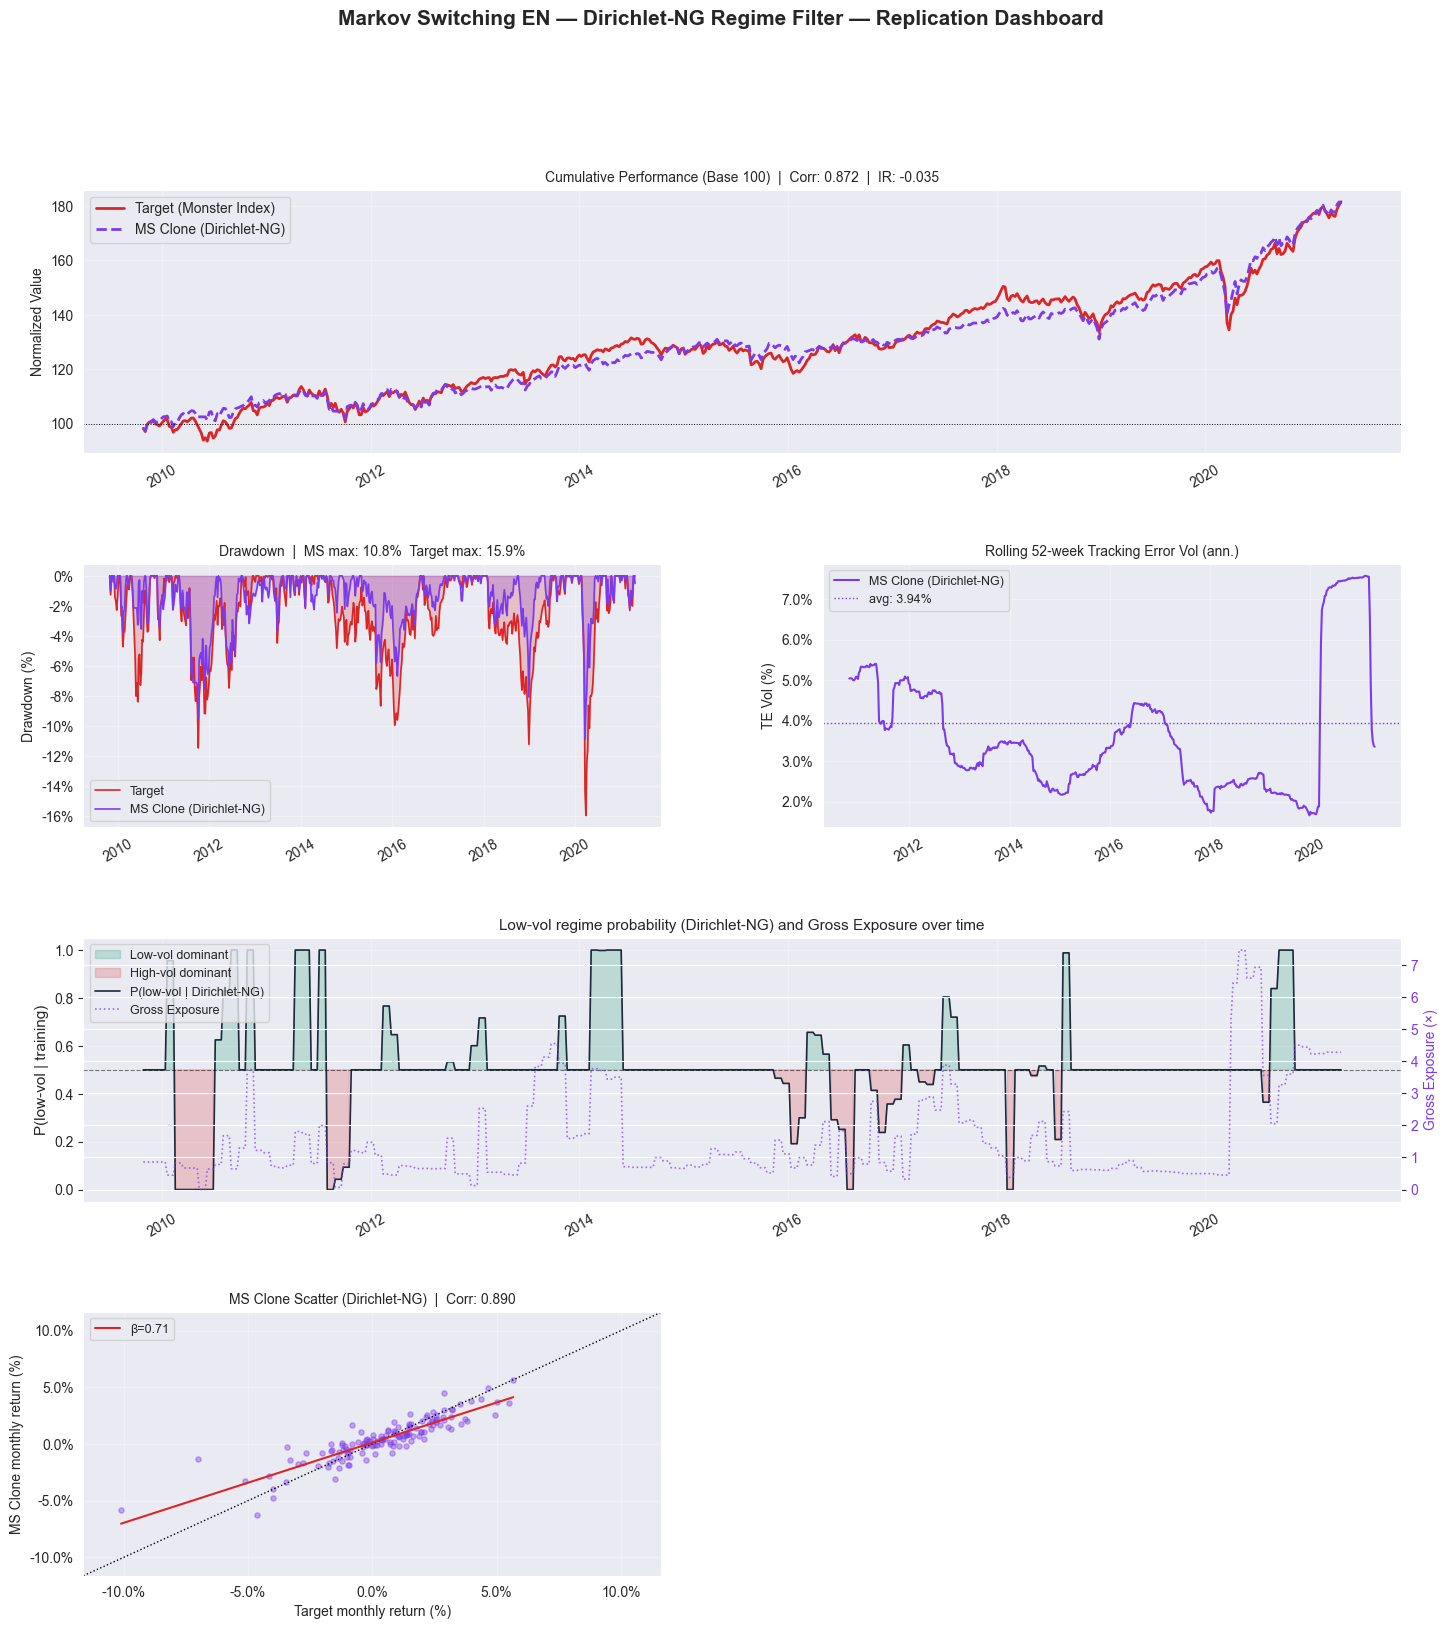

MS Dirichlet-NG dashboard saved.


In [31]:
# ════════════════════════════════════════════════════════════════════════════════
# DASHBOARD — MARKOV SWITCHING EN + DIRICHLET-NG (5 panels)
# ════════════════════════════════════════════════════════════════════════════════

C_MS       = '#7C3AED'   # purple — MS Clone
C_TGT_     = '#DC2626'   # red    — Target fund
C_LOW_VOL  = '#059669'   # green  — low-vol dominant periods
C_HIGH_VOL = '#DC2626'   # red    — high-vol dominant periods

date_fmt = mdates.DateFormatter('%Y')
date_loc = mdates.YearLocator(2)

fig = plt.figure(figsize=(17, 18))
fig.suptitle(
    'Markov Switching EN — Dirichlet-NG Regime Filter — Replication Dashboard',
    fontsize=15, fontweight='bold'
)
gs_ms = gridspec.GridSpec(4, 2, figure=fig, hspace=0.42, wspace=0.28)

ax1 = fig.add_subplot(gs_ms[0, :])
ax2 = fig.add_subplot(gs_ms[1, 0])
ax3 = fig.add_subplot(gs_ms[1, 1])
ax4 = fig.add_subplot(gs_ms[2, :])
ax5 = fig.add_subplot(gs_ms[3, 0])

# ── Pre-compute series ────────────────────────────────────────────────────────
cum_ms   = (1 + y_pred_MS).cumprod() * 100
cum_tgt_ = (1 + y_test_MS).cumprod() * 100

dd_ms   = 1 - (1 + y_pred_MS).cumprod() / (1 + y_pred_MS).cumprod().cummax()
dd_tgt_ = 1 - (1 + y_test_MS).cumprod() / (1 + y_test_MS).cumprod().cummax()

roll_te_ms = (y_pred_MS - y_test_MS).rolling(52).std() * np.sqrt(52) * 100
corr_ms    = y_pred_MS.corr(y_test_MS)

# ── Panel 1: Cumulative Performance ──────────────────────────────────────────
ax1.plot(cum_tgt_, color=C_TGT_, lw=2.0, label='Target (Monster Index)')
ax1.plot(cum_ms,   color=C_MS,   lw=2.0, ls='--', label='MS Clone (Dirichlet-NG)')
ax1.axhline(100, color='black', lw=0.7, ls=':')
ax1.set_title(
    f'Cumulative Performance (Base 100)  |  '
    f'Corr: {corr_ms:.3f}  |  IR: {ir_MS:.3f}',
    fontsize=10
)
ax1.set_ylabel('Normalized Value')
ax1.legend(fontsize=10)
ax1.xaxis.set_major_formatter(date_fmt)
ax1.xaxis.set_major_locator(date_loc)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=30)

# ── Panel 2: Drawdown ─────────────────────────────────────────────────────────
for dd, c, lbl in [(dd_tgt_, C_TGT_, 'Target'),
                   (dd_ms,   C_MS,   'MS Clone (Dirichlet-NG)')]:
    ax2.fill_between(dd.index, -dd.values * 100, 0, color=c, alpha=0.22)
    ax2.plot(dd.index, -dd.values * 100, color=c, lw=1.2, label=lbl)
ax2.set_title(
    f'Drawdown  |  MS max: {mdd_rep_MS*100:.1f}%  '
    f'Target max: {mdd_tgt_MS*100:.1f}%', fontsize=10
)
ax2.set_ylabel('Drawdown (%)')
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(date_fmt)
ax2.xaxis.set_major_locator(date_loc)
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=30)

# ── Panel 3: Rolling Tracking Error ──────────────────────────────────────────
ax3.plot(roll_te_ms, color=C_MS, lw=1.5, label='MS Clone (Dirichlet-NG)')
ax3.axhline(te_vol_MS * 100, color=C_MS, lw=1.0, ls=':',
            label=f'avg: {te_vol_MS*100:.2f}%')
ax3.set_title('Rolling 52-week Tracking Error Vol (ann.)', fontsize=10)
ax3.set_ylabel('TE Vol (%)')
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax3.legend(fontsize=9)
ax3.xaxis.set_major_formatter(date_fmt)
ax3.xaxis.set_major_locator(date_loc)
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='x', rotation=30)

# ── Panel 4: P(Low Vol) + Gross Exposure ─────────────────────────────────────
# Dirichlet-NG produce probabilità più smooth del BW forward filter —
# l'aggiornamento sequenziale riduce i salti bruschi tra rebalancing.
ax4_twin = ax4.twinx()

ax4.fill_between(p_low_vol_MS.index, p_low_vol_MS.values, 0.5,
                 where=(p_low_vol_MS.values >= 0.5),
                 color=C_LOW_VOL, alpha=0.20, label='Low-vol dominant')
ax4.fill_between(p_low_vol_MS.index, p_low_vol_MS.values, 0.5,
                 where=(p_low_vol_MS.values < 0.5),
                 color=C_HIGH_VOL, alpha=0.20, label='High-vol dominant')
ax4.plot(p_low_vol_MS.index, p_low_vol_MS.values,
         color='#1e293b', lw=1.2, label='P(low-vol | Dirichlet-NG)')
ax4.axhline(0.5, color='black', lw=0.8, ls='--', alpha=0.5)
ax4.set_ylim(-0.05, 1.05)
ax4.set_ylabel('P(low-vol | training)', fontsize=11)

ax4_twin.plot(ge_MS.index, ge_MS.values,
              color=C_MS, lw=1.2, ls=':', alpha=0.7, label='Gross Exposure')
ax4_twin.set_ylabel('Gross Exposure (×)', color=C_MS, fontsize=10)
ax4_twin.tick_params(axis='y', labelcolor=C_MS)

lines1, labels1 = ax4.get_legend_handles_labels()
lines2, labels2 = ax4_twin.get_legend_handles_labels()
ax4.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='upper left')
ax4.set_title(
    'Low-vol regime probability (Dirichlet-NG) and Gross Exposure over time',
    fontsize=11
)
ax4.xaxis.set_major_formatter(date_fmt)
ax4.xaxis.set_major_locator(date_loc)
ax4.grid(True, alpha=0.3)
ax4.tick_params(axis='x', rotation=30)

# ── Panel 5: Monthly Return Scatter ──────────────────────────────────────────
ms_m_  = y_pred_MS.resample('ME').apply(lambda x: (1 + x).prod() - 1)
tgt_m_ = y_test_MS.resample('ME').apply(lambda x: (1 + x).prod() - 1)

common_m_ = ms_m_.index.intersection(tgt_m_.index)
ms_m_     = ms_m_.loc[common_m_]
tgt_m_    = tgt_m_.loc[common_m_]

lim = max(abs(tgt_m_.values).max(), abs(ms_m_.values).max()) * 1.15 * 100
ax5.scatter(tgt_m_.values * 100, ms_m_.values * 100, alpha=0.4, s=14, color=C_MS)
ax5.plot([-lim, lim], [-lim, lim], 'k:', lw=1.0)

mf, mb = np.polyfit(tgt_m_.values, ms_m_.values, 1)
xf     = np.linspace(tgt_m_.min(), tgt_m_.max(), 100)
ax5.plot(xf * 100, (mf * xf + mb) * 100,
         color=C_TGT_, lw=1.5, label=f'β={mf:.2f}')

ax5.set_xlim(-lim, lim); ax5.set_ylim(-lim, lim)
ax5.set_xlabel('Target monthly return (%)')
ax5.set_ylabel('MS Clone monthly return (%)')
ax5.set_title(
    f'MS Clone Scatter (Dirichlet-NG)  |  Corr: {ms_m_.corr(tgt_m_):.3f}',
    fontsize=10
)
ax5.legend(fontsize=9)
ax5.grid(True, alpha=0.3)
ax5.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax5.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

plt.savefig('ms_dirichlet_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('MS Dirichlet-NG dashboard saved.')

 The **Elastic Net** operates on a 104-week rolling window and is refitted every
 4 weeks. To preserve internal coherence, regime detection is performed
 WITHIN the same rolling window rather than on the full history:

   - At each rebalance, BW initialises priors on the first BW_MIN_TRAIN
     observations of the training window (causal, in-sample only).
   - The online Dirichlet-NG filter then processes the full 104-week
     training window sequentially, producing causal regime probabilities
     P(high-vol | t) for every observation in the window.
   - These probabilities are used ONLY to build regime-conditional sample
     weights for the EN fit — they never leak outside the rolling window.

A globally-calibrated HMM (initialised once on 2007–2009 and updated
 cumulatively across the full sample) that we have use in the Kalman mathod (next model) would produce more stable regime
 probabilities, but applying those probabilities ONLY to a 104-week
 subset would introduce a domain mismatch. 

 **TRADE-OFF**
 Bounded-memory regime detection is more reactive to structural shifts
 in regime parameters (e.g. the "high-vol" of 2020 is parametrically
 different from that of 2008) but less reliable at identifying rare
 extreme events that lie outside the rolling window. This trade-off is
 explicitly leveraged in the Soft Bayesian Stacking step ,
 where the MS-EN is paired with the Kalman Filter, which uses cumulative
 memory and therefore exhibits the opposite trade-off profile. The two
 models are designed to fail on DIFFERENT events, which is the condition
 under which ensemble methods deliver meaningful diversification gains.

#### Extended Evaluation — MS-EN

1. [Regime Analysis](#regime-analysis-ms)
2. [Stability Analysis](#stability-ms)
3. [Cost Analysis](#cost-ms)
4. [Return Distribution & Tail Risk](#tail-ms)
5. [Regime-Conditional Performance](#regime-cond-ms)
6. [Extended Metrics Summary](#summary-ms)


##### 1. Regime Analysis

How often is the model in low-vol vs high-vol? How long do regimes last?

MS-EN (Dirichlet-NG) — Regime Statistics


,Metric,Value
0,Low-vol weeks,116
1,High-vol weeks,484
2,% Low-vol,19.3%
3,% High-vol,80.7%
4,Avg low-vol spell (weeks),7.2
5,Avg high-vol spell (weeks),28.5
6,Max low-vol spell (weeks),16
7,Max high-vol spell (weeks),100
8,Regime transitions,32
9,Transitions per year,2.8


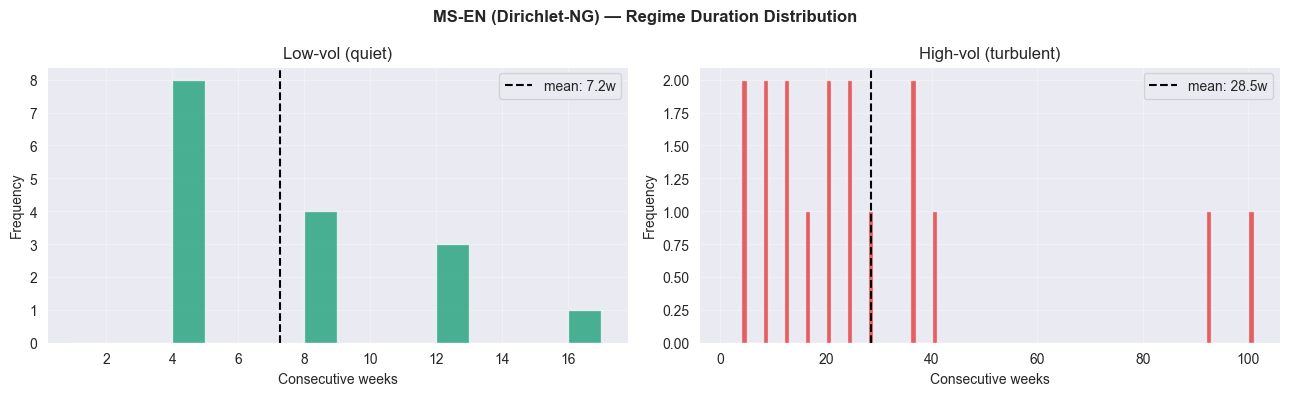

In [32]:
# ════════════════════════════════════════════════════════════════════
# MS-EN — Regime Analysis (Dirichlet-NG filter)
# ════════════════════════════════════════════════════════════════════
VOL_THRESH = 0.5
low_vol_weeks  = (p_low_vol_MS > VOL_THRESH).astype(int)
high_vol_weeks = 1 - low_vol_weeks

def regime_runs(series, val):
    runs, cur = [], 0
    for v in series:
        if v == val: cur += 1
        else:
            if cur > 0: runs.append(cur)
            cur = 0
    if cur > 0: runs.append(cur)
    return runs

low_vol_runs  = regime_runs(low_vol_weeks.values,  1)
high_vol_runs = regime_runs(high_vol_weeks.values, 1)
n_low_vol     = low_vol_weeks.sum()
n_high_vol    = high_vol_weeks.sum()
n_total       = len(p_low_vol_MS)
transitions   = (low_vol_weeks.diff().abs() == 1).sum()

regime_stats = pd.DataFrame({
    'Metric': [
        'Low-vol weeks', 'High-vol weeks',
        '% Low-vol', '% High-vol',
        'Avg low-vol spell (weeks)', 'Avg high-vol spell (weeks)',
        'Max low-vol spell (weeks)', 'Max high-vol spell (weeks)',
        'Regime transitions', 'Transitions per year',
    ],
    'Value': [
        n_low_vol, n_high_vol,
        f'{n_low_vol/n_total*100:.1f}%',  f'{n_high_vol/n_total*100:.1f}%',
        f'{np.mean(low_vol_runs):.1f}'  if low_vol_runs  else 'n/a',
        f'{np.mean(high_vol_runs):.1f}' if high_vol_runs else 'n/a',
        max(low_vol_runs)  if low_vol_runs  else 'n/a',
        max(high_vol_runs) if high_vol_runs else 'n/a',
        transitions, f'{transitions/(n_total/52):.1f}',
    ]
})
print("MS-EN (Dirichlet-NG) — Regime Statistics"); print("="*40)
display(regime_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('MS-EN (Dirichlet-NG) — Regime Duration Distribution',
             fontsize=12, fontweight='bold')
for ax, runs, label, color in [
    (axes[0], low_vol_runs,  'Low-vol (quiet)',      '#059669'),
    (axes[1], high_vol_runs, 'High-vol (turbulent)', '#DC2626'),
]:
    if runs:
        ax.hist(runs, bins=range(1, max(runs)+2), color=color, alpha=0.7, edgecolor='white')
        ax.axvline(np.mean(runs), color='black', lw=1.5, ls='--',
                   label=f'mean: {np.mean(runs):.1f}w')
        ax.set_xlabel('Consecutive weeks'); ax.set_ylabel('Frequency')
        ax.set_title(label); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

##### 2. Stability Analysis

Rolling metrics to check whether replication quality is consistent over time.

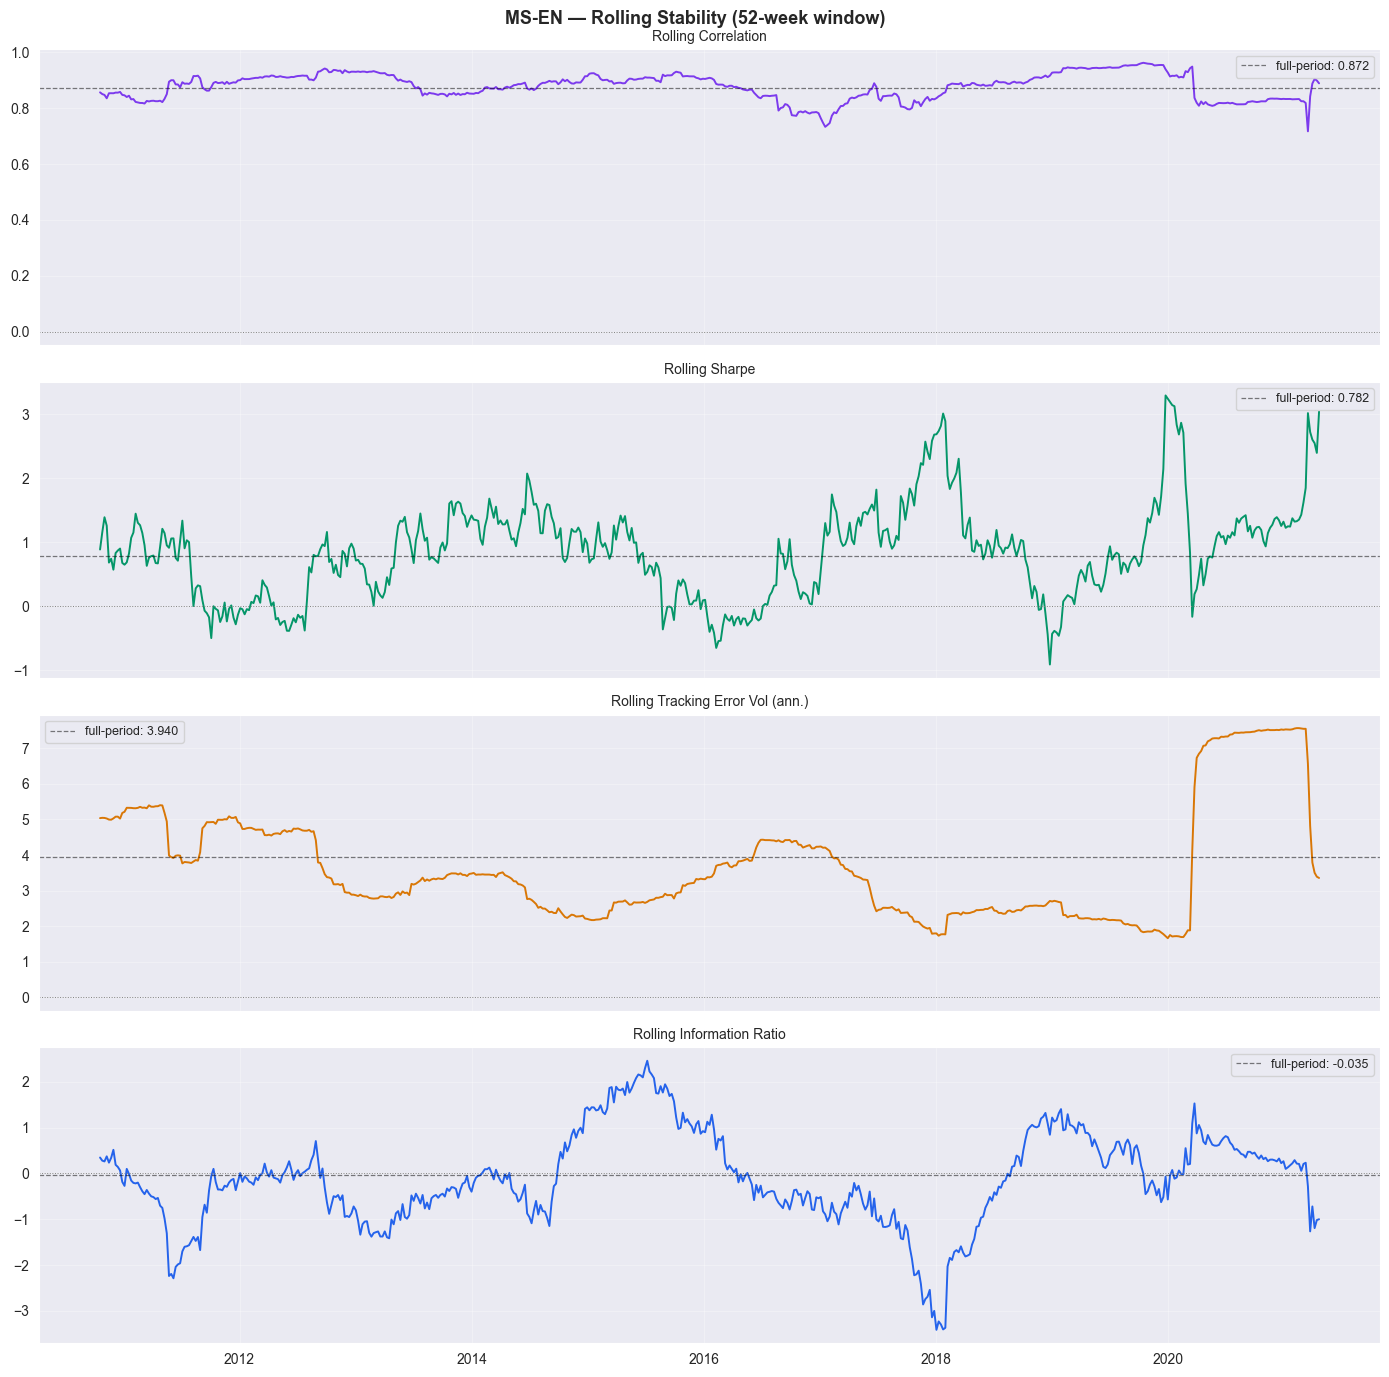

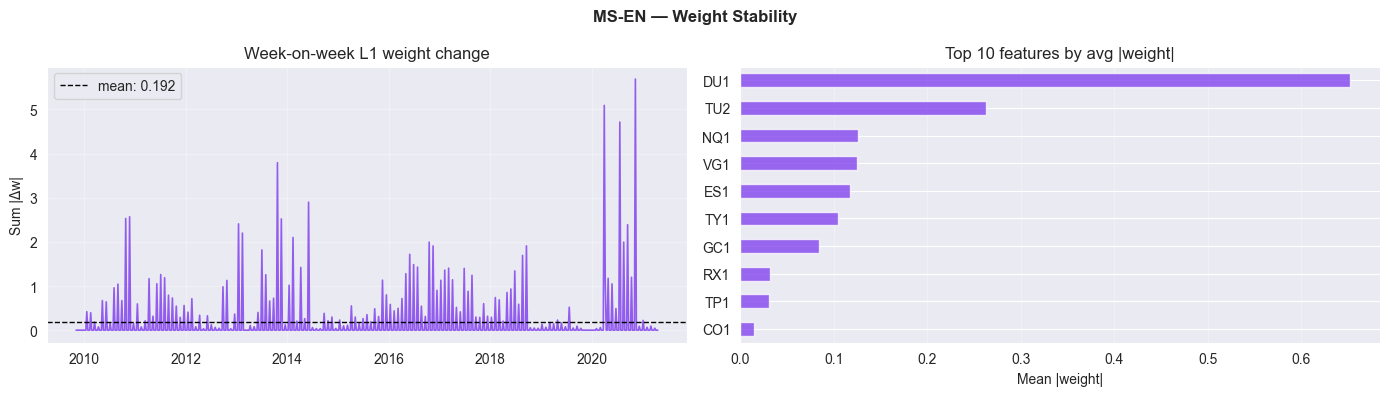

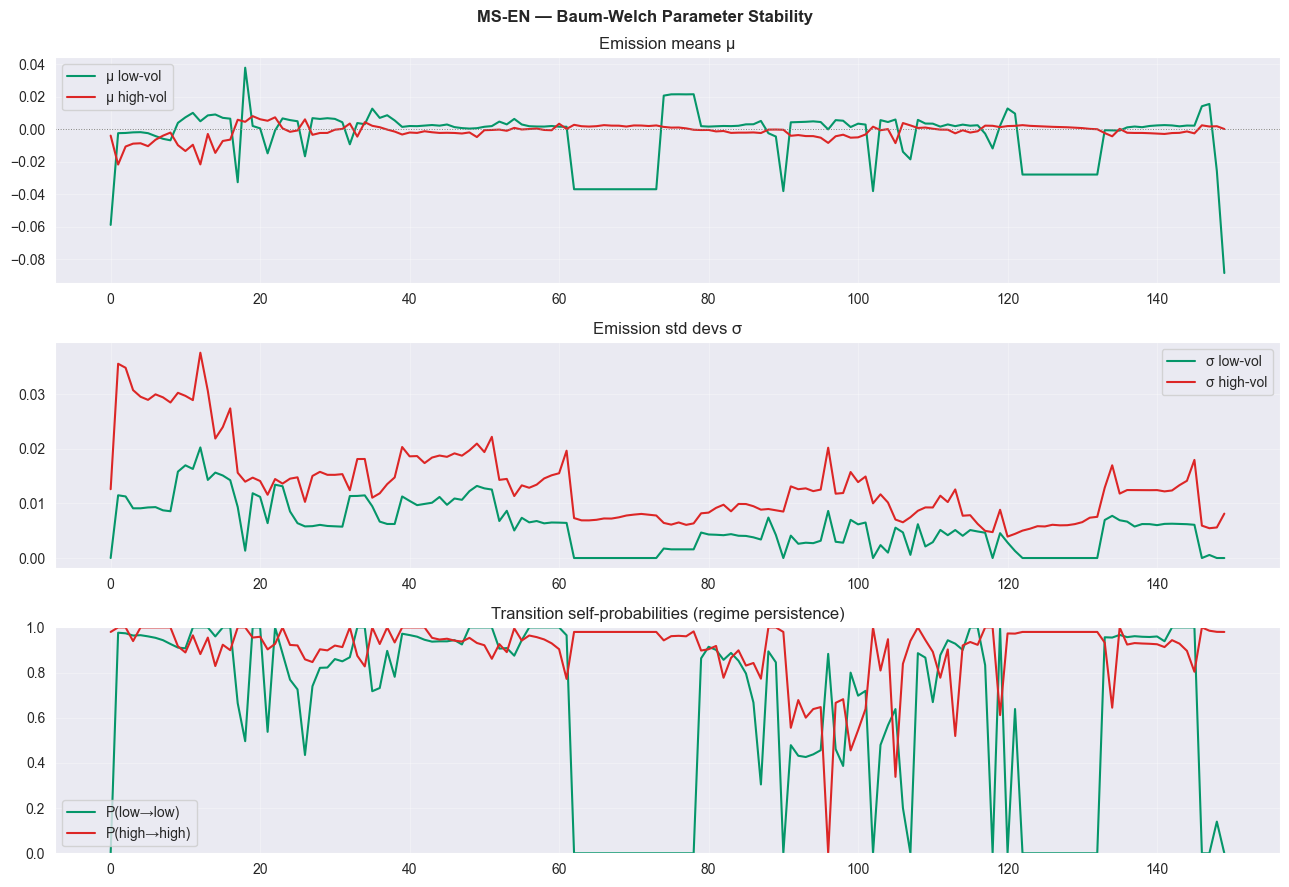

In [33]:
# ════════════════════════════════════════════════════════════════════
# MS-EN — Stability
# ════════════════════════════════════════════════════════════════════
ROLL_WIN = 52
te_MS_w      = y_pred_MS - y_test_MS
roll_corr    = y_pred_MS.rolling(ROLL_WIN).corr(y_test_MS)
roll_sharpe  = (y_pred_MS.rolling(ROLL_WIN).mean() /
                y_pred_MS.rolling(ROLL_WIN).std()) * np.sqrt(52)
roll_te_vol  = te_MS_w.rolling(ROLL_WIN).std() * np.sqrt(52) * 100
roll_ir      = ((y_pred_MS.rolling(ROLL_WIN).mean() - y_test_MS.rolling(ROLL_WIN).mean()) /
                te_MS_w.rolling(ROLL_WIN).std()) * np.sqrt(52)

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle('MS-EN — Rolling Stability (52-week window)', fontsize=13, fontweight='bold')
for ax, series, title, color, hline in [
    (axes[0], roll_corr,   'Rolling Correlation',               '#7C3AED', corr_MS),
    (axes[1], roll_sharpe, 'Rolling Sharpe',                    '#059669', sharpe_rep_MS),
    (axes[2], roll_te_vol, 'Rolling Tracking Error Vol (ann.)', '#D97706', te_vol_MS*100),
    (axes[3], roll_ir,     'Rolling Information Ratio',         '#2563EB', ir_MS),
]:
    ax.plot(series, color=color, lw=1.4)
    ax.axhline(hline, color='black', lw=0.9, ls='--', alpha=0.5, label=f'full-period: {hline:.3f}')
    ax.axhline(0, color='grey', lw=0.7, ls=':')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Weight stability
weights_arr      = np.array(weights_MS)
weight_changes   = np.sum(np.abs(np.diff(weights_arr, axis=0)), axis=1)
weight_changes_s = pd.Series(weight_changes, index=y_pred_MS.index[1:])
mean_abs_w       = pd.Series(np.abs(weights_arr).mean(axis=0),
                              index=weights_MS_df.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('MS-EN — Weight Stability', fontsize=12, fontweight='bold')
axes[0].plot(weight_changes_s, color='#7C3AED', lw=1.2, alpha=0.8)
axes[0].axhline(weight_changes_s.mean(), color='black', lw=1.0, ls='--',
                label=f'mean: {weight_changes_s.mean():.3f}')
axes[0].set_title('Week-on-week L1 weight change'); axes[0].set_ylabel('Sum |Δw|')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
top_n = min(15, len(mean_abs_w))
mean_abs_w.head(top_n).plot(kind='barh', ax=axes[1], color='#7C3AED', alpha=0.75)
axes[1].set_title(f'Top {top_n} features by avg |weight|')
axes[1].set_xlabel('Mean |weight|'); axes[1].invert_yaxis(); axes[1].grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

# BW parameter stability
if bw_params_hist:
    mu_lv  = [p['mu'][0]    for p in bw_params_hist]
    mu_hv  = [p['mu'][1]    for p in bw_params_hist]
    sig_lv = [p['sigma'][0] for p in bw_params_hist]
    sig_hv = [p['sigma'][1] for p in bw_params_hist]
    p11    = [p['A'][0,0]   for p in bw_params_hist]
    p22    = [p['A'][1,1]   for p in bw_params_hist]
    fig, axes = plt.subplots(3, 1, figsize=(13, 9))
    fig.suptitle('MS-EN — Baum-Welch Parameter Stability', fontsize=12, fontweight='bold')
    axes[0].plot(mu_lv,  label='μ low-vol',  color='#059669')
    axes[0].plot(mu_hv,  label='μ high-vol', color='#DC2626')
    axes[0].axhline(0, color='grey', lw=0.7, ls=':')
    axes[0].set_title('Emission means μ'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(sig_lv, label='σ low-vol',  color='#059669')
    axes[1].plot(sig_hv, label='σ high-vol', color='#DC2626')
    axes[1].set_title('Emission std devs σ'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    axes[2].plot(p11, label='P(low→low)',   color='#059669')
    axes[2].plot(p22, label='P(high→high)', color='#DC2626')
    axes[2].set_ylim(0, 1)
    axes[2].set_title('Transition self-probabilities (regime persistence)')
    axes[2].legend(); axes[2].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("bw_params_hist is empty.")


##### 3. Cost Analysis

Transaction cost drag and turnover breakdown by regime.

MS-EN — Cost Analysis


,Metric,Value
0,Avg weekly one-way turnover,0.0978
1,Avg annualized turnover,5.00x
2,Avg weekly cost (bps),0.39 bps
3,Annual cost drag (bps),20.3 bps
4,Gross ann. return (pre-cost),5.56%
5,Net ann. return (post-cost),5.36%
6,Cost drag,0.20%
7,Avg turnover in low-vol regime,0.1488
8,Avg turnover in high-vol regime,0.0856


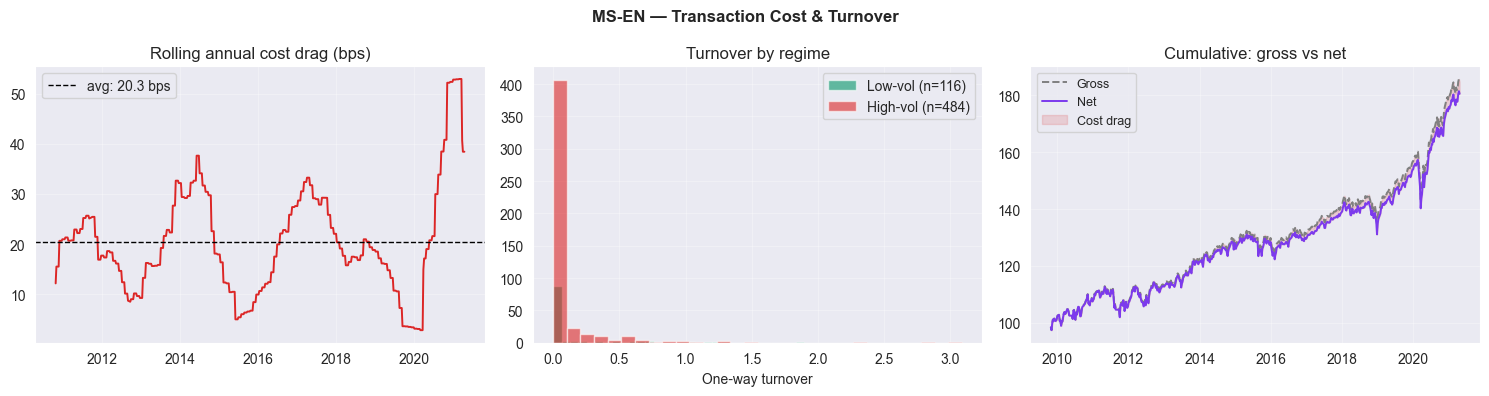

In [34]:
# ════════════════════════════════════════════════════════════════════
# MS-EN — Cost Analysis
# ════════════════════════════════════════════════════════════════════
ANNUAL        = 52
cost_series   = turnover_MS * MS_TC
ann_cost_drag = cost_series.mean() * ANNUAL
y_pred_gross  = y_pred_MS + cost_series
ret_gross     = y_pred_gross.mean() * ANNUAL
ret_net       = y_pred_MS.mean()    * ANNUAL
to_low        = turnover_MS[p_low_vol_MS >  VOL_THRESH]
to_high       = turnover_MS[p_low_vol_MS <= VOL_THRESH]

cost_stats = pd.DataFrame({
    'Metric': [
        'Avg weekly one-way turnover', 'Avg annualized turnover',
        'Avg weekly cost (bps)', 'Annual cost drag (bps)',
        'Gross ann. return (pre-cost)', 'Net ann. return (post-cost)', 'Cost drag',
        'Avg turnover in low-vol regime', 'Avg turnover in high-vol regime',
    ],
    'Value': [
        f'{turnover_MS.mean():.4f}', f'{ann_to_MS:.2f}x',
        f'{cost_series.mean()*10000:.2f} bps', f'{ann_cost_drag*10000:.1f} bps',
        f'{ret_gross*100:.2f}%', f'{ret_net*100:.2f}%',
        f'{(ret_gross-ret_net)*100:.2f}%',
        f'{to_low.mean():.4f}'  if len(to_low)  > 0 else 'n/a',
        f'{to_high.mean():.4f}' if len(to_high) > 0 else 'n/a',
    ]
})
print("MS-EN — Cost Analysis"); print("="*45); display(cost_stats)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('MS-EN — Transaction Cost & Turnover', fontsize=12, fontweight='bold')
axes[0].plot(cost_series.rolling(52).mean()*ANNUAL*10000, color='#DC2626', lw=1.4)
axes[0].axhline(ann_cost_drag*10000, color='black', lw=1.0, ls='--',
                label=f'avg: {ann_cost_drag*10000:.1f} bps')
axes[0].set_title('Rolling annual cost drag (bps)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].hist(to_low.values,  bins=30, alpha=0.6, color='#059669', label=f'Low-vol (n={len(to_low)})')
axes[1].hist(to_high.values, bins=30, alpha=0.6, color='#DC2626', label=f'High-vol (n={len(to_high)})')
axes[1].set_title('Turnover by regime'); axes[1].set_xlabel('One-way turnover')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
cum_gr = (1+y_pred_gross).cumprod()*100; cum_nt = (1+y_pred_MS).cumprod()*100
axes[2].plot(cum_gr, color='grey', lw=1.4, ls='--', label='Gross')
axes[2].plot(cum_nt, color='#7C3AED', lw=1.4, label='Net')
axes[2].fill_between(cum_gr.index, cum_gr, cum_nt, alpha=0.15, color='#DC2626', label='Cost drag')
axes[2].set_title('Cumulative: gross vs net'); axes[2].legend(fontsize=9); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 4. Return Distribution & Tail Risk

MS-EN — Tail Risk & Distribution


,Metric,Value
0,Skewness (replica),-0.520
1,Skewness (target),-1.045
2,Excess kurtosis (replica),3.216
3,Excess kurtosis (target),7.548
4,Sortino (replica),0.992
5,Sortino (target),0.837
6,Calmar (replica),0.495
7,Calmar (target),0.345
8,VaR 95% (replica),-1.512%
9,VaR 99% (replica),-2.673%


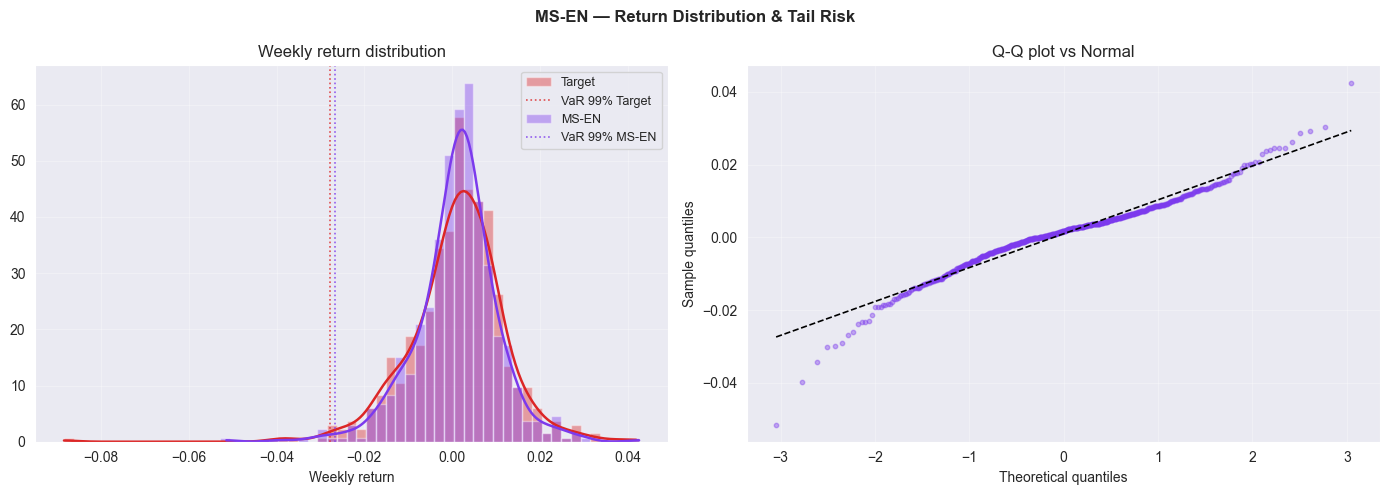

In [35]:
# ════════════════════════════════════════════════════════════════════
# MS-EN — Tail Risk
# ════════════════════════════════════════════════════════════════════
from scipy import stats as sp_stats

skew_rep  = float(sp_stats.skew(y_pred_MS.dropna()))
kurt_rep  = float(sp_stats.kurtosis(y_pred_MS.dropna()))
skew_tgt  = float(sp_stats.skew(y_test_MS.dropna()))
kurt_tgt  = float(sp_stats.kurtosis(y_test_MS.dropna()))
ds_rep    = y_pred_MS[y_pred_MS < 0]
ds_tgt    = y_test_MS[y_test_MS < 0]
sortino_rep = (y_pred_MS.mean()*ANNUAL)/(ds_rep.std()*np.sqrt(ANNUAL)) if len(ds_rep)>1 else np.nan
sortino_tgt = (y_test_MS.mean()*ANNUAL)/(ds_tgt.std()*np.sqrt(ANNUAL)) if len(ds_tgt)>1 else np.nan
calmar_rep  = ret_rep_MS/mdd_rep_MS if mdd_rep_MS > 0 else np.nan
calmar_tgt  = ret_tgt_MS/mdd_tgt_MS if mdd_tgt_MS > 0 else np.nan
var95_rep   = np.percentile(y_pred_MS, 5);  var99_rep  = np.percentile(y_pred_MS, 1)
cvar95_rep  = y_pred_MS[y_pred_MS<=var95_rep].mean()
cvar99_rep  = y_pred_MS[y_pred_MS<=var99_rep].mean()
var95_tgt   = np.percentile(y_test_MS, 5);  var99_tgt  = np.percentile(y_test_MS, 1)
cvar95_tgt  = y_test_MS[y_test_MS<=var95_tgt].mean()
cvar99_tgt  = y_test_MS[y_test_MS<=var99_tgt].mean()
hit_rate    = (np.sign(y_pred_MS) == np.sign(y_test_MS)).mean()
smape_ms    = (2*np.abs(y_pred_MS-y_test_MS)/(np.abs(y_pred_MS)+np.abs(y_test_MS)+1e-10)).mean()

tail_stats = pd.DataFrame({
    'Metric': [
        'Skewness (replica)','Skewness (target)',
        'Excess kurtosis (replica)','Excess kurtosis (target)',
        'Sortino (replica)','Sortino (target)',
        'Calmar (replica)','Calmar (target)',
        'VaR 95% (replica)','VaR 99% (replica)','CVaR 95% (replica)','CVaR 99% (replica)',
        'VaR 95% (target)', 'VaR 99% (target)', 'CVaR 95% (target)', 'CVaR 99% (target)',
        'Hit rate','SMAPE',
    ],
    'Value': [
        f'{skew_rep:.3f}',f'{skew_tgt:.3f}',f'{kurt_rep:.3f}',f'{kurt_tgt:.3f}',
        f'{sortino_rep:.3f}',f'{sortino_tgt:.3f}',f'{calmar_rep:.3f}',f'{calmar_tgt:.3f}',
        f'{var95_rep*100:.3f}%',f'{var99_rep*100:.3f}%',
        f'{cvar95_rep*100:.3f}%',f'{cvar99_rep*100:.3f}%',
        f'{var95_tgt*100:.3f}%',f'{var99_tgt*100:.3f}%',
        f'{cvar95_tgt*100:.3f}%',f'{cvar99_tgt*100:.3f}%',
        f'{hit_rate*100:.1f}%',f'{smape_ms:.4f}',
    ]
})
print("MS-EN — Tail Risk & Distribution"); print("="*45); display(tail_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('MS-EN — Return Distribution & Tail Risk', fontsize=12, fontweight='bold')
bins = np.linspace(min(y_pred_MS.min(),y_test_MS.min()), max(y_pred_MS.max(),y_test_MS.max()), 60)
for series, color, label in [(y_test_MS,'#DC2626','Target'),(y_pred_MS,'#7C3AED','MS-EN')]:
    axes[0].hist(series, bins=bins, alpha=0.4, color=color, density=True, label=label)
    kde = sp_stats.gaussian_kde(series.dropna())
    kde_x = np.linspace(series.min(), series.max(), 200)
    axes[0].plot(kde_x, kde(kde_x), color=color, lw=1.8)
    axes[0].axvline(np.percentile(series,1), color=color, lw=1.2, ls=':', alpha=0.8,
                    label=f'VaR 99% {label}')
axes[0].set_title('Weekly return distribution'); axes[0].set_xlabel('Weekly return')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
(osm,osr),(slope,intercept,_) = sp_stats.probplot(y_pred_MS.dropna(), dist='norm')
axes[1].scatter(osm, osr, alpha=0.4, s=10, color='#7C3AED', label='MS-EN')
axes[1].plot(osm, slope*np.array(osm)+intercept, color='black', lw=1.2, ls='--')
axes[1].set_title('Q-Q plot vs Normal'); axes[1].set_xlabel('Theoretical quantiles')
axes[1].set_ylabel('Sample quantiles'); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 5. Regime-Conditional Performance

MS-EN (Dirichlet-NG) — Regime-Conditional Performance


,N weeks,Ann.Return,Ann.Vol,Sharpe,Corr,TEV,IR,Hit Rate
Regime,,,,,,,,
Low-vol (quiet),116,5.12%,6.55%,0.783,0.915,2.87%,-1.816,89.7%
High-vol (turbulent),484,5.42%,6.93%,0.781,0.865,4.14%,0.261,85.7%
All,600,5.36%,6.85%,0.782,0.872,3.94%,-0.035,86.5%


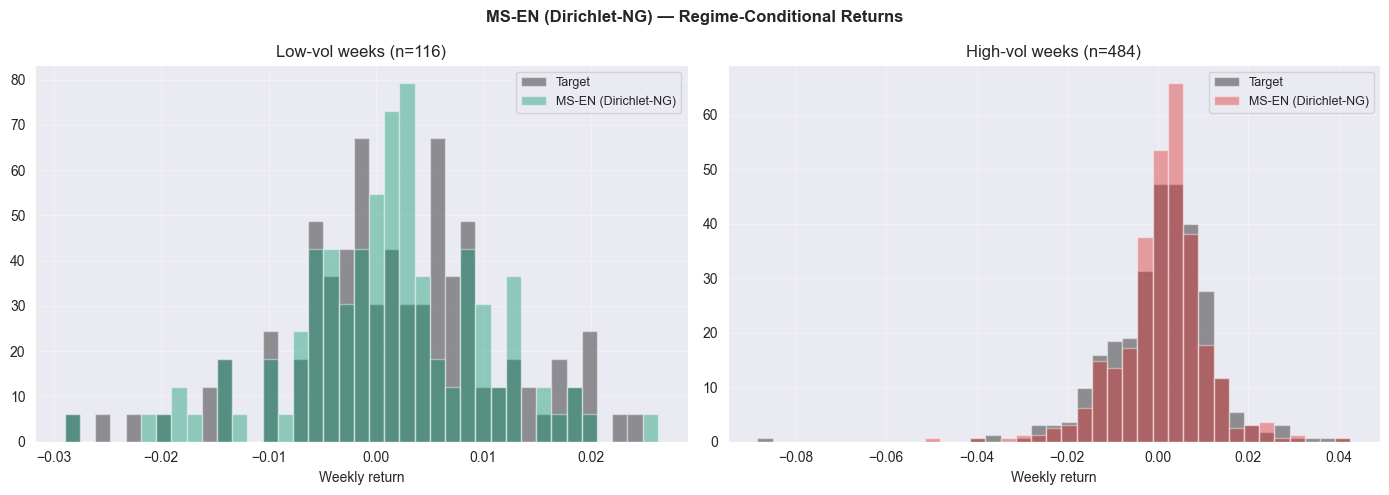

In [36]:
# ════════════════════════════════════════════════════════════════════
# MS-EN — Regime-Conditional Performance (Dirichlet-NG filter)
# ════════════════════════════════════════════════════════════════════
mask_low  = p_low_vol_MS >  VOL_THRESH
mask_high = ~mask_low

def regime_perf(pred, tgt, mask, label):
    p, t = pred[mask], tgt[mask]
    if len(p) < 5:
        return {'Regime': label, 'N weeks': len(p),
                **{k:'n/a' for k in ['Ann.Return','Ann.Vol','Sharpe','Corr','TEV','IR','Hit Rate']}}
    te = p-t; ret_r=p.mean()*ANNUAL; vol_r=p.std()*np.sqrt(ANNUAL)
    tev=te.std()*np.sqrt(ANNUAL); ir=(ret_r-t.mean()*ANNUAL)/tev if tev>0 else np.nan
    corr=np.corrcoef(p,t)[0,1]; hr=(np.sign(p)==np.sign(t)).mean()
    sharpe=ret_r/vol_r if vol_r>0 else np.nan
    return {'Regime':label,'N weeks':len(p),
            'Ann.Return':f'{ret_r*100:.2f}%','Ann.Vol':f'{vol_r*100:.2f}%',
            'Sharpe':f'{sharpe:.3f}','Corr':f'{corr:.3f}',
            'TEV':f'{tev*100:.2f}%','IR':f'{ir:.3f}','Hit Rate':f'{hr*100:.1f}%'}

all_mask = pd.Series([True]*len(y_pred_MS), index=y_pred_MS.index)
rc_df = pd.DataFrame([
    regime_perf(y_pred_MS, y_test_MS, mask_low,  'Low-vol (quiet)'),
    regime_perf(y_pred_MS, y_test_MS, mask_high, 'High-vol (turbulent)'),
    regime_perf(y_pred_MS, y_test_MS, all_mask,  'All'),
]).set_index('Regime')
print("MS-EN (Dirichlet-NG) — Regime-Conditional Performance")
print("="*55)
display(rc_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('MS-EN (Dirichlet-NG) — Regime-Conditional Returns',
             fontsize=12, fontweight='bold')
for ax, mask, label, color in [
    (axes[0], mask_low,  'Low-vol weeks',  '#059669'),
    (axes[1], mask_high, 'High-vol weeks', '#DC2626'),
]:
    p_r, t_r = y_pred_MS[mask], y_test_MS[mask]
    bins_ = np.linspace(min(p_r.min(),t_r.min()), max(p_r.max(),t_r.max()), 40)
    ax.hist(t_r, bins=bins_, alpha=0.4, color='black', density=True, label='Target')
    ax.hist(p_r, bins=bins_, alpha=0.4, color=color,  density=True, label='MS-EN (Dirichlet-NG)')
    ax.set_title(f'{label} (n={mask.sum()})'); ax.set_xlabel('Weekly return')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Kalman Filter (Dynamic Replication Model)

#### Table of Contents

1. [Overview](#Overview-1)
2. [Helper Functions](#Helper-Functions)
3. [Initialisation: Baum-Welch on the First Training Window](#Initialisation:-Baum-Welch-on-the-First-Training-Window)
4. [Online Bayesian Regime Update](#Online-Bayesian-Regime-Update)
5. [Running the Kalman Filter](#Running-the-Kalman-Filter)
6. [Performance Metrics and Transaction Cost Breakdown](#Performance-Metrics-and-Transaction-Cost-Breakdown)
7. [Plots](#Plots)

##### 1. Overview

 **Financial intuition**

Unlike Elastic Net, which periodically re-estimates a fixed weight vector, the **Kalman Filter** treats portfolio exposures as **latent time-varying states**.

**Financial motivation**  
Relationships between the Monster Index and its hedging instruments evolve continuously through time. A static allocation may therefore become suboptimal as market conditions change.

The Kalman framework naturally supports:

- dynamic rebalancing,
- adaptive exposures,
- sequential learning,
- smoother transitions between market states.

 **Methodological intuition**

Portfolio weights evolve dynamically and are updated as new information arrives. In this project, the process noise is conditioned on **Markovian regimes**, allowing the model to react differently during calm and turbulent periods.

**Expected interpretation**  
An effective Kalman specification should maintain strong tracking performance while adapting exposures smoothly and limiting excessive turnover.


In [37]:
# ── Bridge: adapt main notebook variables for the Kalman Filter ───────────────
#
# The Kalman section expects NumPy arrays (X_all, y_all, Date, T, m,
# rolling_window, obs_train, X_train), while the main notebook uses pandas
# DataFrames (X, y, futures_ret, target).  This cell performs the type
# conversion and alignment without reloading the dataset.
#
# rolling_window = 104 weeks (2 years) is chosen to match the shortest
# Elastic Net window, ensuring the two models start their OOS evaluation
# at the same date and can be compared on the same sample.

rolling_window = 104          # training window: 104 weeks (2 years)

X_all  = X.values.astype(float)          # (T, m) futures return array
y_all  = y.values.astype(float)          # (T,)   Monster Index returns
Date   = X.index.to_numpy()              # (T,)   aligned dates

T, m = X_all.shape

# obs_train and X_train: the first rolling_window observations used exclusively
# for the initial Baum-Welch fit.  They are NOT included in the OOS evaluation.

obs_train = y_all[:rolling_window]
X_train   = X_all[:rolling_window]

futures_names = list(X.columns)

print(f"Bridge OK — T={T}, m={m}, training window={rolling_window} weeks")
print(f"Futures: {futures_names}")


Bridge OK — T=704, m=10, training window=104 weeks
Futures: ['RX1', 'TY1', 'GC1', 'CO1', 'ES1', 'VG1', 'NQ1', 'TP1', 'DU1', 'TU2']


##### 2. Helper Functions

`run_kalman` executes the rolling estimation loop: at each step it pulls the current training window, feeds the HMM variance as process noise $Q_t$, runs the Kalman recursion to update the weight estimate, applies leverage and turnover controls, and records the net OOS replicated return.




In [38]:
def run_kalman(X_all, y_all, hmm_var, rolling_window,
               max_leverage=2.0, turnover_thr=0.05,
               transaction_cost_rate=0.0004):
    """
    Rolling Kalman Filter for dynamic portfolio replication.

    In quiet regimes, hmm_var is lower:
      -> process noise Q_t is smaller;
      -> weights are kept more stable.

    In volatile regimes, hmm_var is higher:
      -> process noise Q_t is larger;
      -> the Kalman gain increases;
      -> weights react faster to new market information.

    Returns
    -------
    r_net  : out-of-sample replicated returns after transaction costs.
    b      : dynamic portfolio weights.
    ge     : gross exposure, computed as sum(abs(weights)).
    tc_arr : transaction cost paid at each step.
    """

    # Number of observations and number of futures.
    T, m = X_all.shape

    # Initial portfolio: no futures exposure before the first update.
    b_prev = np.zeros(m)

    # Containers for out-of-sample returns, weights, exposure and costs.
    b_list, r_list, ge_list, tc_list = [], [], [], []

    # Rolling estimation loop.
    # At each step, the model uses only the current historical window and
    # then predicts the next observation. This preserves the out-of-sample logic.
    for i in range(T - rolling_window - 1):

        # Historical futures returns in the current training window.
        H = X_all[i : i + rolling_window]

        # Historical target returns in the same window.
        y_meas = y_all[i : i + rolling_window]

        # HMM-based process noise values for the same dates.
        q_win = hmm_var[i : i + rolling_window]

        # Measurement noise: empirical variance of the target in the window.
        # This is causal because it uses only observations inside the past window.
        R_s = np.var(y_meas)

        # Kalman initial state inside the rolling window.
        # x_pred represents the estimated portfolio weights.
        # P represents the uncertainty around these weights.
        x_pred = np.zeros(m)
        P = np.eye(m)

        # Run the Kalman recursion through the current window.
        for t in range(rolling_window):

            # Observation vector: futures returns at date t.
            h = H[t]

            # Innovation variance: uncertainty of the prediction error.
            S_t = h @ P @ h + R_s

            # Kalman gain: determines how strongly weights are updated.
            # Higher P or lower R_s means a stronger update.
            K = (P @ h) / max(S_t, 1e-300)

            # Prediction error between observed target return and replicated return.
            innovation = y_meas[t] - h @ x_pred

            # State update: adjust the portfolio weights using the innovation.
            x_pred = x_pred + innovation * K

            # Covariance update.
            # The HMM-based q_win[t] is added to allow weights to move over time.
            # In volatile regimes, q_win[t] is larger and the model becomes more reactive.
            P = (np.eye(m) - np.outer(K, h)) @ P + np.eye(m) * q_win[t]

        # Final estimated weights from the current rolling window.
        b_new = x_pred.copy()

        # Gross leverage cap.
        # If the sum of absolute weights is too high, rescale all weights
        # proportionally while preserving their relative composition.
        gross_leverage = np.abs(b_new).sum()
        if gross_leverage > max_leverage:
            b_new *= max_leverage / gross_leverage

        # Turnover generated by moving from previous weights to new weights.
        proposed_turnover = np.abs(b_new - b_prev).sum()

        # Turnover gate.
        # If the change in weights is too small, the model keeps the previous
        # allocation and avoids paying transaction costs for a marginal rebalance.
        if b_list and proposed_turnover < turnover_thr:
            b_new = b_prev.copy()
            turnover = 0.0
        else:
            turnover = proposed_turnover

        # One-step-ahead replicated return before transaction costs.
        y_pred_gross = X_all[i + rolling_window] @ b_new

        # Linear transaction cost approximation.
        # Costs depend on turnover only, not on the realised target return,
        # so this step does not introduce look-ahead bias.
        tc_cost = transaction_cost_rate * turnover/2

        # Net replicated return after rebalancing costs.
        y_pred_net = y_pred_gross - tc_cost

        # Store current results and update previous weights.
        b_prev = b_new.copy()
        ge_list.append(np.abs(b_new).sum())
        b_list.append(b_new.copy())
        tc_list.append(tc_cost)
        r_list.append(y_pred_net)

    return (np.array(r_list),
            np.array(b_list),
            np.array(ge_list),
            np.array(tc_list))

##### 3. Initialisation: Baum-Welch on the First Training Window

The Online Bayesian filter needs a warm start before sequential updating begins. We fit a two-state Gaussian HMM via Baum-Welch EM on the first 104 weeks of Monster Index returns — the same training block used by the Elastic Net — and extract the initial transition matrix $A_0$, regime means $\mu_0$, and regime volatilities $\sigma_0$.

These values initialise the Dirichlet and Normal-Gamma priors in the Online Bayesian filter, and $\sigma_0$ seeds the process noise series $Q_t$ that will be fed into the Kalman recursion. From this point onward, all updates are strictly causal.


In [39]:
# ── Initialisation: Baum-Welch on the first training window ────────────────────
# The Kalman Filter needs a regime-dependent process noise Q_t.
# To initialise the regime model, we fit a two-state Gaussian HMM on the first
# 104 weeks of Monster Index returns.

print("Fitting Baum-Welch on training window...")

# Baum-Welch estimates the transition matrix, regime probabilities,
# regime means and regime volatilities.

hmm0 = baum_welch(obs_train)

# Store the initial HMM parameters.
# These values are later used as priors for the Online Bayesian filter.

A0   = hmm0["A"].copy()
pi0  = hmm0["pi"].copy()
mu0  = hmm0["mu"].copy()
sig0 = hmm0["sigma"].copy()

print(f"  Estimated transition matrix A:\n{np.round(A0, 4)}")
print(f"  Emission means  mu  : {np.round(mu0, 6)}")
print(f"  Emission std sigma  : {np.round(sig0, 6)}")


Fitting Baum-Welch on training window...
  Estimated transition matrix A:
[[0.9822 0.0178]
 [0.0397 0.9603]]
  Emission means  mu  : [ 0.001686 -0.005718]
  Emission std sigma  : [0.01311 0.02966]


##### 4. Online Bayesian Regime Update

Starting from the Baum-Welch estimates, the Online Bayesian filter updates regime probabilities one observation at a time, using conjugate Dirichlet and Normal-Gamma posteriors. The output is a time-varying process noise series `hmm_var` — the probability-weighted posterior variance across regimes — which is the direct input to the Kalman Filter. A high value means the model believes the market is in a volatile state and allows weights to move more freely at that date.

In [40]:
# ── Online Bayesian HMM: sequential regime probabilities ──────────────────────
#
# The Online Bayesian HMM produces three outputs used by the Kalman Filter:
#
#   prob_vol   : filtered P(volatile regime | data up to t) for each date t.
#                Used by the Elastic Net's regime-aware sample weighting.
#
#   alpha      : full (T, 2) matrix of filtered regime probabilities.
#                Column 0 = P(quiet | past), column 1 = P(volatile | past).
#
#   hmm_var    : time-varying process noise Q_t for the Kalman Filter.
#                Computed as the probability-weighted posterior variance across
#                regimes: Q_t = sum_s P(state s | t) * Var(state s | t).

prob_vol, alpha, hmm_var = online_bayesian_hmm(
    y_all          = y_all,
    A0             = A0,
    mu0            = mu0,
    sig0           = sig0,
    rolling_window = rolling_window,
)

##### 5. Running the Kalman Filter

The filter runs in rolling fashion: for each date after the initial training window, it estimates the current exposure vector from past data, applies risk controls, and records the one-step-ahead replicated return net of costs. Every replicated return is strictly out-of-sample — no information from period $t$ enters the return for period $t$.

In [41]:
# ── Run Kalman Filter with HMM-based process noise ─────────────────────────────
#
# The Kalman Filter is run once over the full sample in rolling fashion.
# At every step:
#   1. A training window of past futures and target returns is extracted.
#   2. The HMM variance series for the same window sets the process noise Q_t.
#   3. The Kalman recursion runs through the window to estimate the current
#      exposure vector b_t and its covariance P_t.
#   4. Leverage and turnover controls are applied, and the one-step-ahead
#      replicated return is recorded net of transaction costs.
#
# Transaction cost assumption:
# 0.0004 = 4 bps per unit of two-way turnover

print("Running Kalman Filters...")

transaction_cost_rate = 0.0004
print(f"Transaction cost rate: {transaction_cost_rate*1e4:.1f} bps per unit turnover")

# Run the dynamic replication model.
# hmm_var is the regime-adaptive process noise: higher in volatile regimes,
# lower in quiet ones, so the filter naturally reacts faster when it should.
r, b, ge, tc = run_kalman(
    X_all, y_all, hmm_var, rolling_window,
    transaction_cost_rate=transaction_cost_rate
)

# Align target returns and dates with the OOS replicated returns.
# The first rolling_window observations were used for estimation only;
# the OOS evaluation starts at the (rolling_window + 1)-th observation.
n_oos      = len(r)
target_oos = y_all[rolling_window : rolling_window + n_oos]
date_oos   = Date[rolling_window : rolling_window + n_oos]

print(f"Aligned OOS observations: {n_oos}")


Running Kalman Filters...
Transaction cost rate: 4.0 bps per unit turnover
Aligned OOS observations: 599


##### 6. Performance Metrics and Transaction Cost Breakdown

In [42]:
# ════════════════════════════════════════════════════════════════════
# Performance metrics — Kalman Filter
# ════════════════════════════════════════════════════════════════════
ANNUAL       = 52
VOL_THRESH   = 0.5
kalman_dates = pd.to_datetime(date_oos).normalize()

y_pred_K     = pd.Series(r,          index=kalman_dates, name='Kalman')
y_test_K     = pd.Series(target_oos, index=kalman_dates, name='Target')
tc_K         = pd.Series(tc,         index=kalman_dates)
ge_K         = pd.Series(ge,         index=kalman_dates)
prob_vol_K   = pd.Series(
    prob_vol[rolling_window : rolling_window + len(r)],
    index=kalman_dates, name='P(volatile)'
)
# Build weights matrix for turnover computation
# (Kalman saves weights in `b_hist` or similar; adapt the variable name
#  to match your actual notebook variable)
try:
    weights_K_arr = np.array(b)   # adapt if your Kalman uses different name
except NameError:
    weights_K_arr = None

# Use unified metric function
metrics_K_dict = perf_metrics_clean(
    r_replica = y_pred_K,
    r_target  = y_test_K,
    b_weights = weights_K_arr,
    tc_arr    = tc_K.values if 'tc_K' in dir() else None,
    label     = "Kalman Filter (regime-aware)",
)

# Extract standalone variables (used by dashboard and other cells)
ir_K         = metrics_K_dict['ir']
te_vol_K     = metrics_K_dict['tev']
corr_K       = metrics_K_dict['corr']
sharpe_rep_K = metrics_K_dict['sharpe_rep']
mdd_rep_K    = metrics_K_dict['max_dd_rep']
mdd_tgt_K    = metrics_K_dict['max_dd_tgt']
ret_rep_K    = metrics_K_dict['ann_ret_rep']
ret_tgt_K    = metrics_K_dict['ann_ret_tgt']
vol_rep_K    = metrics_K_dict['ann_vol_rep']
vol_tgt_K    = metrics_K_dict['ann_vol_tgt']
rmse_K       = metrics_K_dict['rmse']

metrics_K = pd.DataFrame({
    'Metric': [
        'Annualized Return (Replica)', 'Annualized Return (Target)',
        'Annualized Volatility (Replica)', 'Annualized Volatility (Target)',
        'Sharpe Ratio (Replica)',
        'Information Ratio', 'Tracking Error Volatility',
        'RMSE (weekly)', 'Correlation',
        'Max Drawdown (Replica)', 'Max Drawdown (Target)',
        'Avg Gross Exposure',
    ],
    'Value': [
        f'{ret_rep_K*100:.2f}%',  f'{ret_tgt_K*100:.2f}%',
        f'{vol_rep_K*100:.2f}%',  f'{vol_tgt_K*100:.2f}%',
        f'{sharpe_rep_K:.3f}',
        f'{ir_K:.3f}',            f'{te_vol_K*100:.2f}%',
        f'{rmse_K*100:.4f}%',     f'{corr_K:.3f}',
        f'{mdd_rep_K*100:.1f}%',  f'{mdd_tgt_K*100:.1f}%',
              f'{ge_K.mean():.3f}',
    ]
})

print("\nMarkov Switching EN — Performance Summary")
print("=" * 50)
display(metrics_K)

print("Kalman variables aligned.")



--- Kalman Filter (regime-aware) ---
  N obs              : 599
  Correlation        : 0.9161
  TEV (ann.)         : 3.23%
  Information Ratio  : 0.0981
  MSE                : 2.00e-05
  Sharpe (replica)   : 0.767
  Sharpe (target)    : 0.677
  Ann. Return (rep)  : 5.76%
  Ann. Vol (rep)     : 7.52%
  Max DD (rep)       : 11.8%
  Max DD (tgt)       : 15.9%
  Annual Turnover    : 1.69x
  Avg TC per step    : 0.13 bps
  Yearly TC avg      : 6.92 bps

Markov Switching EN — Performance Summary


,Metric,Value
0,Annualized Return (Replica),5.76%
1,Annualized Return (Target),5.44%
2,Annualized Volatility (Replica),7.52%
3,Annualized Volatility (Target),8.04%
4,Sharpe Ratio (Replica),0.767
5,Information Ratio,0.098
6,Tracking Error Volatility,3.23%
7,RMSE (weekly),0.4472%
8,Correlation,0.916
9,Max Drawdown (Replica),11.8%


Kalman variables aligned.


##### 7. Plots

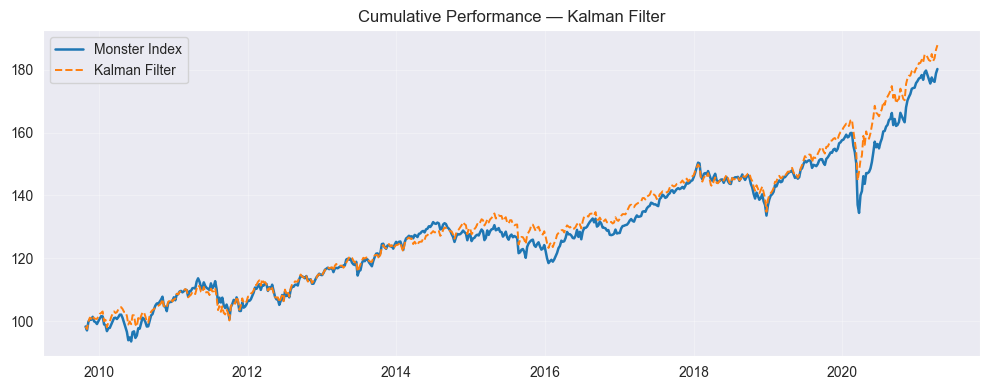

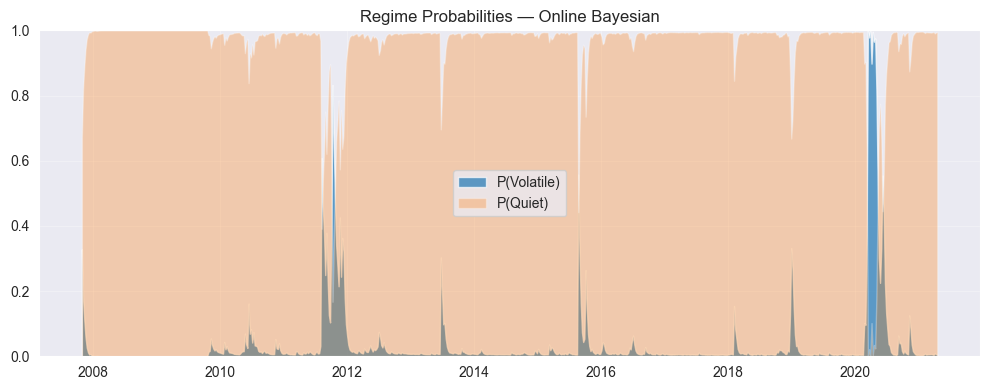

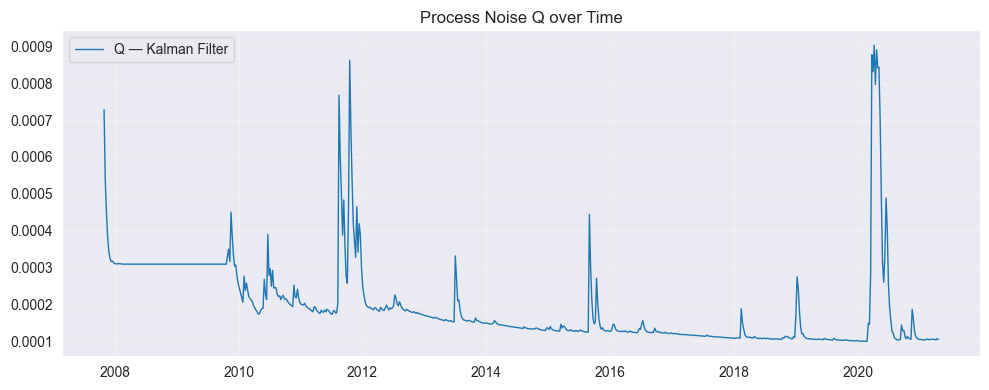

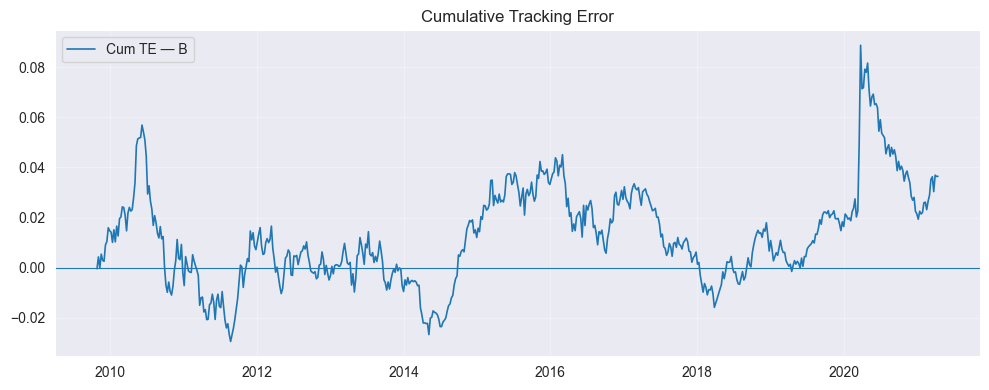

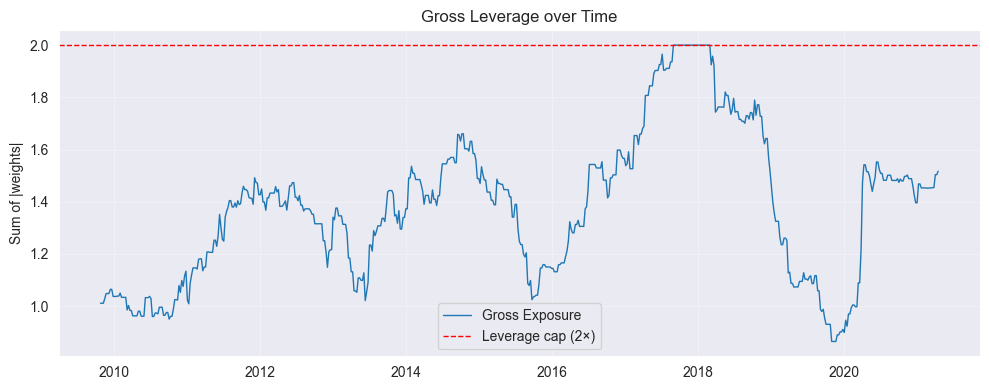

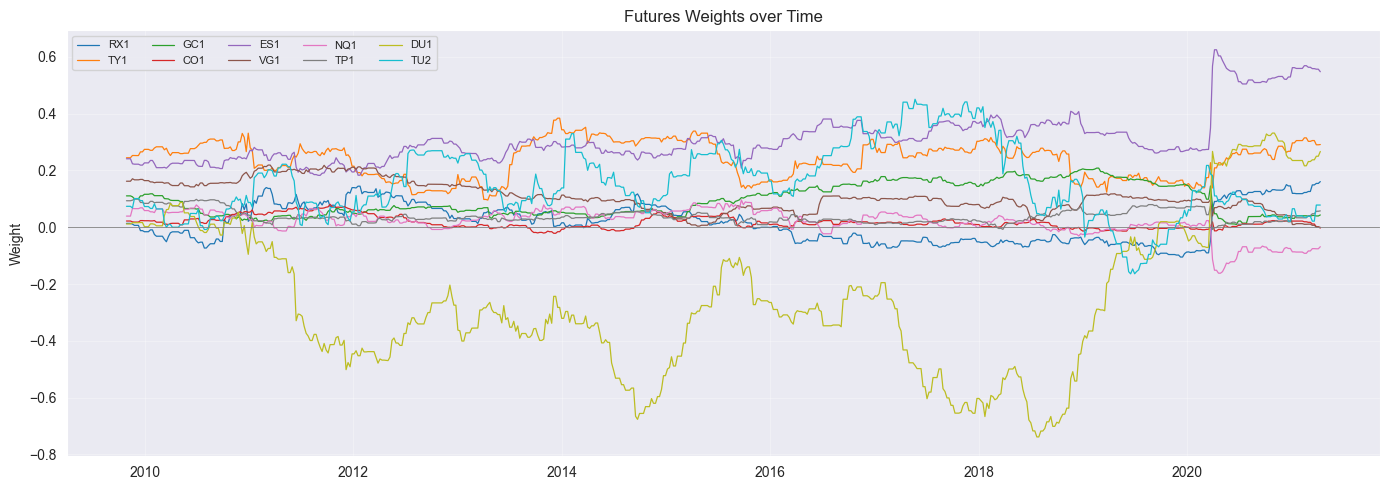

In [43]:
def show(fig):
    fig.tight_layout()
    plt.show()
 
# Cumulative performance
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_oos, (1 + target_oos).cumprod() * 100, lw=1.8, label="Monster Index")
ax.plot(date_oos, (1 + r).cumprod() * 100,        lw=1.4, linestyle="--", label="Kalman Filter")
ax.set_title("Cumulative Performance — Kalman Filter")
ax.legend(); ax.grid(True, alpha=0.3)
show(fig)

# Regime probabilities
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(Date, prob_vol,       alpha=0.7, label="P(Volatile)")
ax.fill_between(Date, 1 - prob_vol,  alpha=0.3, label="P(Quiet)")
ax.set_ylim(0, 1)
ax.set_title("Regime Probabilities — Online Bayesian")
ax.legend(); ax.grid(True, alpha=0.3)
show(fig)

# Process noise
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(Date, hmm_var, lw=1.0, label="Q — Kalman Filter")
ax.set_title("Process Noise Q over Time")
ax.legend(); ax.grid(True, alpha=0.3)
show(fig)

# Cumulative tracking error
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_oos, np.cumsum(r - target_oos), lw=1.2, label="Cum TE — B")
ax.axhline(0, lw=0.8)
ax.set_title("Cumulative Tracking Error")
ax.legend(); ax.grid(True, alpha=0.3)
show(fig)

# Gross leverage over time
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_oos, ge, lw=1.0, label="Gross Exposure")
ax.axhline(2.0, lw=1.0, linestyle="--", color="red", label="Leverage cap (2×)")
ax.set_title("Gross Leverage over Time")
ax.set_ylabel("Sum of |weights|")
ax.legend(); ax.grid(True, alpha=0.3)
show(fig)

# Futures weights over time
fig, ax = plt.subplots(figsize=(14, 5))
for j, name in enumerate(futures_names):
    ax.plot(date_oos, b[:, j], lw=0.9, label=name)
ax.axhline(0, lw=0.6, color="grey")
ax.set_title("Futures Weights over Time")
ax.set_ylabel("Weight")
ax.legend(ncol=5, fontsize=8); ax.grid(True, alpha=0.3)
show(fig)

#### Extended Evaluation — Kalman Filter


1. [Regime Analysis](#regime-analysis-k)
2. [Stability Analysis](#stability-k)
3. [Cost Analysis](#cost-k)
4. [Return Distribution & Tail Risk](#tail-k)
5. [Regime-Conditional Performance](#regime-cond-k)
6. [Extended Metrics Summary](#summary-k)


In [44]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Align into pandas Series and compute core metrics
# ════════════════════════════════════════════════════════════════════
ANNUAL       = 52
VOL_THRESH   = 0.5
kalman_dates = pd.to_datetime(date_oos).normalize()
y_pred_K     = pd.Series(r,          index=kalman_dates, name='Kalman')
y_test_K     = pd.Series(target_oos, index=kalman_dates, name='Target')
tc_K         = pd.Series(tc,         index=kalman_dates)
ge_K         = pd.Series(ge,         index=kalman_dates)
prob_vol_K   = pd.Series(
    prob_vol[rolling_window : rolling_window + len(r)],
    index=kalman_dates, name='P(volatile)')

te_K         = y_pred_K - y_test_K
te_vol_K     = te_K.std()  * np.sqrt(ANNUAL)
ret_rep_K    = y_pred_K.mean() * ANNUAL
ret_tgt_K    = y_test_K.mean() * ANNUAL
vol_rep_K    = y_pred_K.std()  * np.sqrt(ANNUAL)
vol_tgt_K    = y_test_K.std()  * np.sqrt(ANNUAL)
ir_K         = (ret_rep_K - ret_tgt_K) / te_vol_K
sharpe_rep_K = ret_rep_K / vol_rep_K
corr_K       = y_pred_K.corr(y_test_K)
cum_rep_K    = (1 + y_pred_K).cumprod()
mdd_rep_K    = (1 - cum_rep_K / cum_rep_K.cummax()).max()
cum_tgt_K    = (1 + y_test_K).cumprod()
mdd_tgt_K    = (1 - cum_tgt_K / cum_tgt_K.cummax()).max()
rmse_K       = np.sqrt(np.mean(te_K**2))
print("Kalman variables aligned.")


Kalman variables aligned.


##### 1. Regime Analysis

Kalman — Regime Statistics


,Metric,Value
0,Low-vol weeks,585
1,High-vol weeks,14
2,% Low-vol,97.7%
3,% High-vol,2.3%
4,Avg low-vol spell,97.5
5,Avg high-vol spell,2.8
6,Max low-vol spell,237
7,Max high-vol spell,9
8,Regime transitions,10
9,Transitions per year,0.9


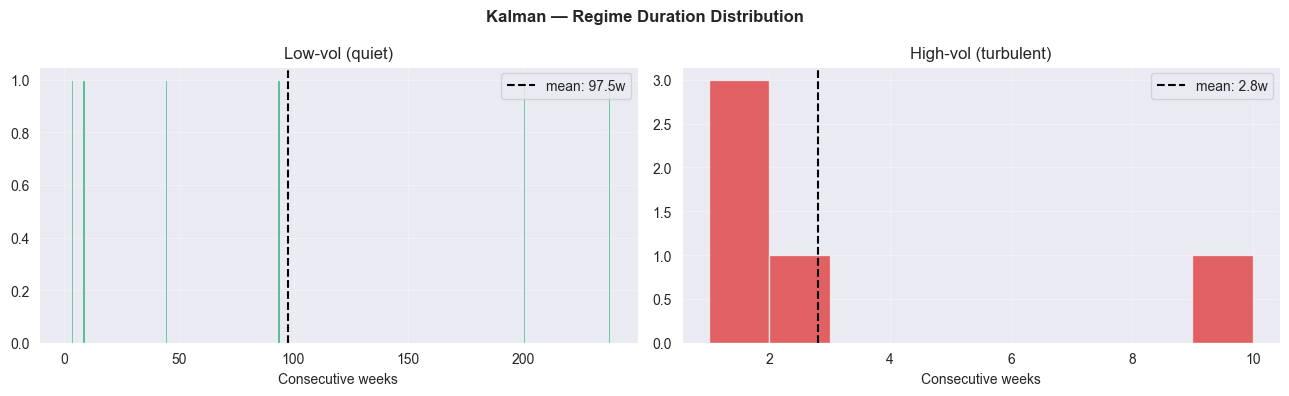

In [45]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Regime Analysis
# ════════════════════════════════════════════════════════════════════
low_wks_K  = (prob_vol_K <= VOL_THRESH).astype(int)
high_wks_K = 1 - low_wks_K
trans_K    = (low_wks_K.diff().abs() == 1).sum()
n_low_K    = low_wks_K.sum(); n_high_K = high_wks_K.sum(); n_total_K = len(prob_vol_K)
low_runs_K  = regime_runs(low_wks_K.values,  1)
high_runs_K = regime_runs(high_wks_K.values, 1)

regime_stats_K = pd.DataFrame({
    'Metric': [
        'Low-vol weeks','High-vol weeks','% Low-vol','% High-vol',
        'Avg low-vol spell','Avg high-vol spell',
        'Max low-vol spell','Max high-vol spell',
        'Regime transitions','Transitions per year',
    ],
    'Value': [
        n_low_K, n_high_K,
        f'{n_low_K/n_total_K*100:.1f}%', f'{n_high_K/n_total_K*100:.1f}%',
        f'{np.mean(low_runs_K):.1f}'  if low_runs_K  else 'n/a',
        f'{np.mean(high_runs_K):.1f}' if high_runs_K else 'n/a',
        max(low_runs_K)  if low_runs_K  else 'n/a',
        max(high_runs_K) if high_runs_K else 'n/a',
        trans_K, f'{trans_K/(n_total_K/52):.1f}',
    ]
})
print("Kalman — Regime Statistics"); print("="*40); display(regime_stats_K)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Kalman — Regime Duration Distribution', fontsize=12, fontweight='bold')
for ax, runs, label, color in [
    (axes[0], low_runs_K,  'Low-vol (quiet)',      '#059669'),
    (axes[1], high_runs_K, 'High-vol (turbulent)', '#DC2626'),
]:
    if runs:
        ax.hist(runs, bins=range(1, max(runs)+2), color=color, alpha=0.7, edgecolor='white')
        ax.axvline(np.mean(runs), color='black', lw=1.5, ls='--', label=f'mean: {np.mean(runs):.1f}w')
        ax.set_xlabel('Consecutive weeks'); ax.set_title(label); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 2. Stability Analysis

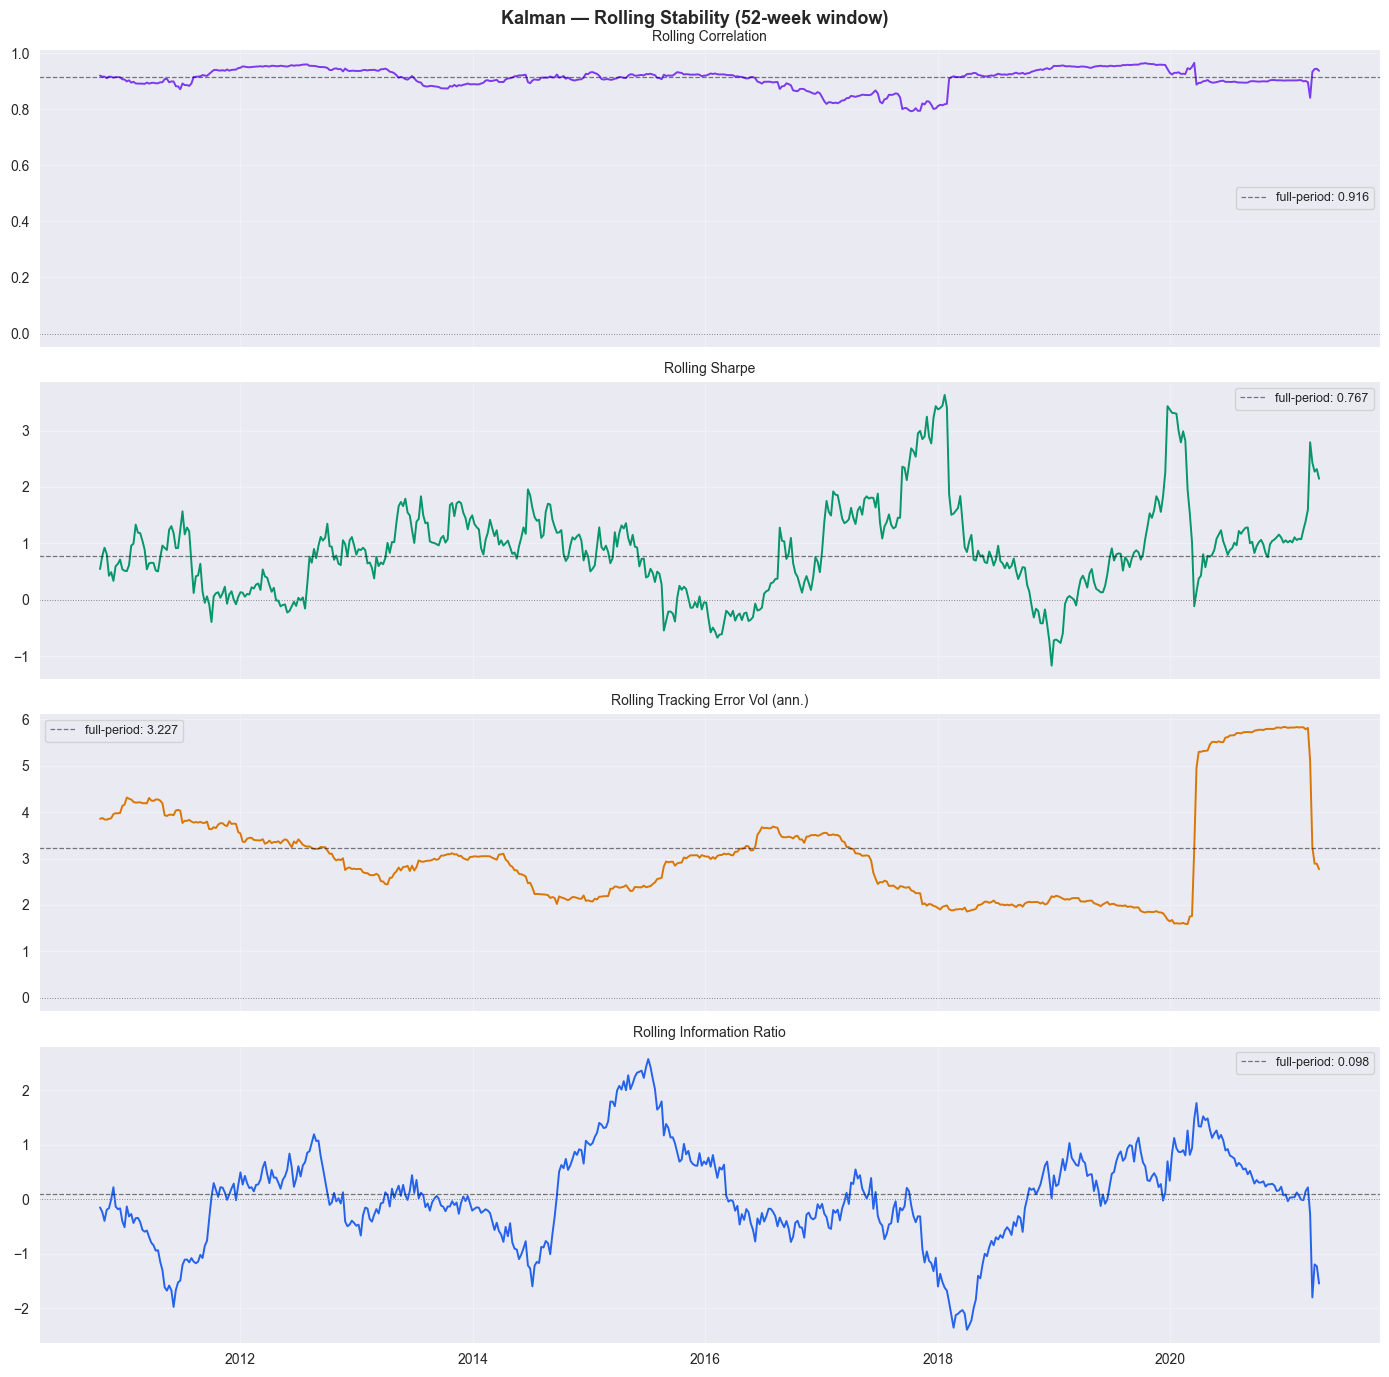

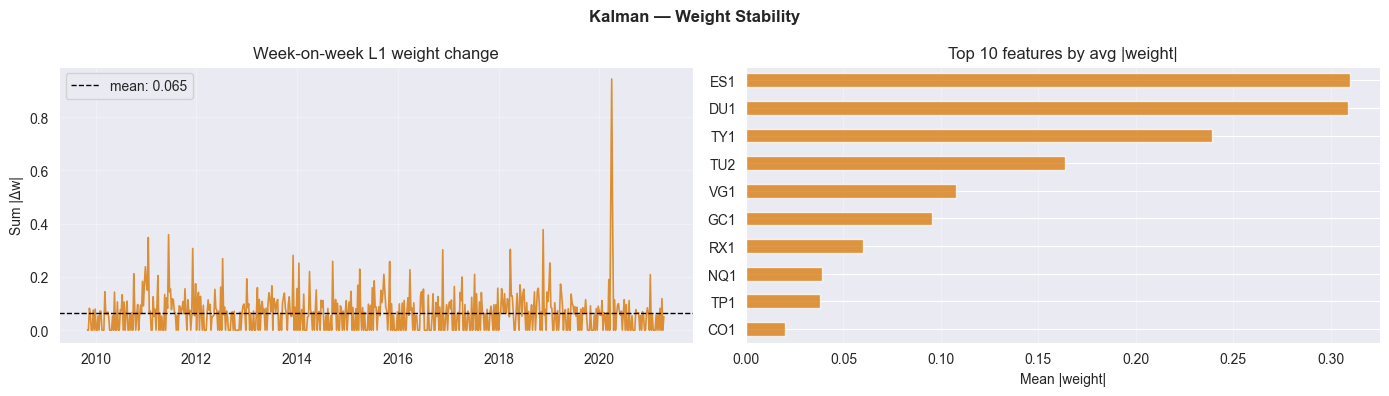

In [46]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Stability
# ════════════════════════════════════════════════════════════════════
ROLL_WIN      = 52
roll_corr_K   = y_pred_K.rolling(ROLL_WIN).corr(y_test_K)
roll_sharpe_K = (y_pred_K.rolling(ROLL_WIN).mean() /
                 y_pred_K.rolling(ROLL_WIN).std()) * np.sqrt(52)
roll_te_K     = te_K.rolling(ROLL_WIN).std() * np.sqrt(52) * 100
roll_ir_K     = ((y_pred_K.rolling(ROLL_WIN).mean() - y_test_K.rolling(ROLL_WIN).mean()) /
                 te_K.rolling(ROLL_WIN).std()) * np.sqrt(52)

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle('Kalman — Rolling Stability (52-week window)', fontsize=13, fontweight='bold')
for ax, series, title, color, hline in [
    (axes[0], roll_corr_K,   'Rolling Correlation',               '#7C3AED', corr_K),
    (axes[1], roll_sharpe_K, 'Rolling Sharpe',                    '#059669', sharpe_rep_K),
    (axes[2], roll_te_K,     'Rolling Tracking Error Vol (ann.)', '#D97706', te_vol_K*100),
    (axes[3], roll_ir_K,     'Rolling Information Ratio',         '#2563EB', ir_K),
]:
    ax.plot(series, color=color, lw=1.4)
    ax.axhline(hline, color='black', lw=0.9, ls='--', alpha=0.5, label=f'full-period: {hline:.3f}')
    ax.axhline(0, color='grey', lw=0.7, ls=':')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

b_arr          = np.array(b)
wt_ch_K        = np.sum(np.abs(np.diff(b_arr, axis=0)), axis=1)
wt_ch_K_s      = pd.Series(wt_ch_K, index=kalman_dates[1:])
mean_abs_wK    = pd.Series(np.abs(b_arr).mean(axis=0), index=futures_names).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Kalman — Weight Stability', fontsize=12, fontweight='bold')
axes[0].plot(wt_ch_K_s, color='#D97706', lw=1.2, alpha=0.8)
axes[0].axhline(wt_ch_K_s.mean(), color='black', lw=1.0, ls='--',
                label=f'mean: {wt_ch_K_s.mean():.3f}')
axes[0].set_title('Week-on-week L1 weight change'); axes[0].set_ylabel('Sum |Δw|')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
top_n = min(15, len(mean_abs_wK))
mean_abs_wK.head(top_n).plot(kind='barh', ax=axes[1], color='#D97706', alpha=0.75)
axes[1].set_title(f'Top {top_n} features by avg |weight|')
axes[1].set_xlabel('Mean |weight|'); axes[1].invert_yaxis(); axes[1].grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()


##### 3. Cost Analysis

Kalman — Cost Analysis


,Metric,Value
0,Avg weekly TC (bps),0.13 bps
1,Annual TC drag (bps),6.9 bps
2,Gross ann. return (pre-cost),5.83%
3,Net ann. return (post-cost),5.76%
4,Cost drag,0.07%
5,Avg TC in low-vol regime,0.13 bps
6,Avg TC in high-vol regime,0.35 bps


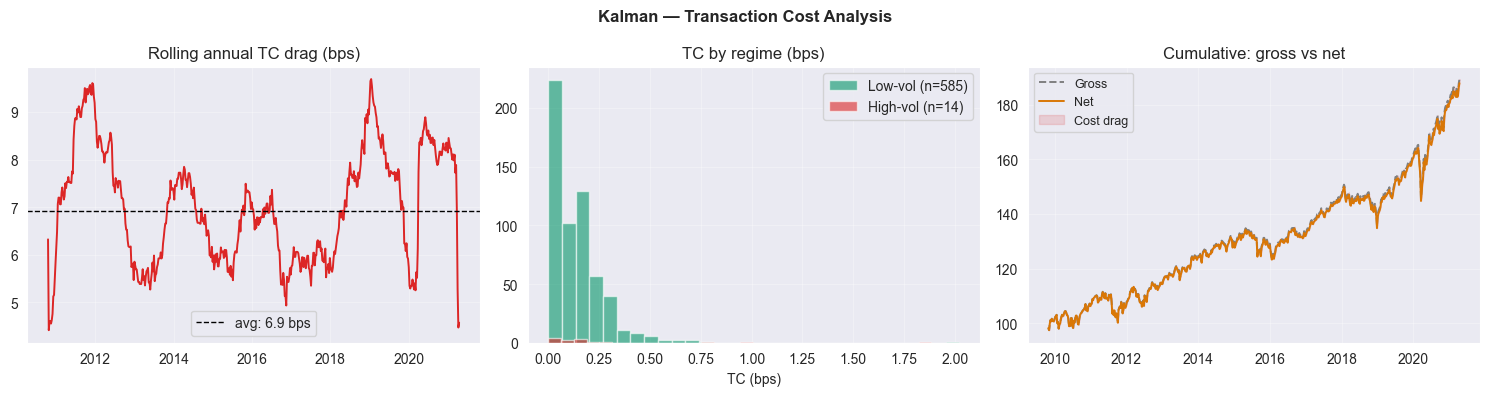

In [47]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Cost Analysis
# ════════════════════════════════════════════════════════════════════
ann_cost_K  = tc_K.mean() * ANNUAL
y_pred_K_gr = y_pred_K + tc_K
ret_gross_K = y_pred_K_gr.mean() * ANNUAL
to_low_K    = tc_K[prob_vol_K <= VOL_THRESH]
to_high_K   = tc_K[prob_vol_K >  VOL_THRESH]

cost_stats_K = pd.DataFrame({
    'Metric': [
        'Avg weekly TC (bps)','Annual TC drag (bps)',
        'Gross ann. return (pre-cost)','Net ann. return (post-cost)','Cost drag',
        'Avg TC in low-vol regime','Avg TC in high-vol regime',
    ],
    'Value': [
        f'{tc_K.mean()*10000:.2f} bps',   f'{ann_cost_K*10000:.1f} bps',
        f'{ret_gross_K*100:.2f}%',         f'{ret_rep_K*100:.2f}%',
        f'{(ret_gross_K-ret_rep_K)*100:.2f}%',
        f'{to_low_K.mean()*10000:.2f} bps'  if len(to_low_K)  > 0 else 'n/a',
        f'{to_high_K.mean()*10000:.2f} bps' if len(to_high_K) > 0 else 'n/a',
    ]
})
print("Kalman — Cost Analysis"); print("="*45); display(cost_stats_K)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Kalman — Transaction Cost Analysis', fontsize=12, fontweight='bold')
axes[0].plot(tc_K.rolling(52).mean()*ANNUAL*10000, color='#DC2626', lw=1.4)
axes[0].axhline(ann_cost_K*10000, color='black', lw=1.0, ls='--',
                label=f'avg: {ann_cost_K*10000:.1f} bps')
axes[0].set_title('Rolling annual TC drag (bps)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].hist(to_low_K.values*10000,  bins=30, alpha=0.6, color='#059669',
             label=f'Low-vol (n={len(to_low_K)})')
axes[1].hist(to_high_K.values*10000, bins=30, alpha=0.6, color='#DC2626',
             label=f'High-vol (n={len(to_high_K)})')
axes[1].set_title('TC by regime (bps)'); axes[1].set_xlabel('TC (bps)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
cum_gr_K = (1+y_pred_K_gr).cumprod()*100; cum_nt_K = (1+y_pred_K).cumprod()*100
axes[2].plot(cum_gr_K, color='grey',    lw=1.4, ls='--', label='Gross')
axes[2].plot(cum_nt_K, color='#D97706', lw=1.4,          label='Net')
axes[2].fill_between(cum_gr_K.index, cum_gr_K, cum_nt_K,
                     alpha=0.15, color='#DC2626', label='Cost drag')
axes[2].set_title('Cumulative: gross vs net'); axes[2].legend(fontsize=9); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 4. Return Distribution & Tail Risk

Kalman — Tail Risk


,Metric,Value
0,Skewness,-0.599
1,Excess kurtosis,4.053
2,Sortino,0.965
3,Calmar,0.488
4,VaR 95%,-1.657%
5,VaR 99%,-2.844%
6,CVaR 95%,-2.490%
7,CVaR 99%,-3.959%
8,Hit rate,87.6%
9,SMAPE,0.6862


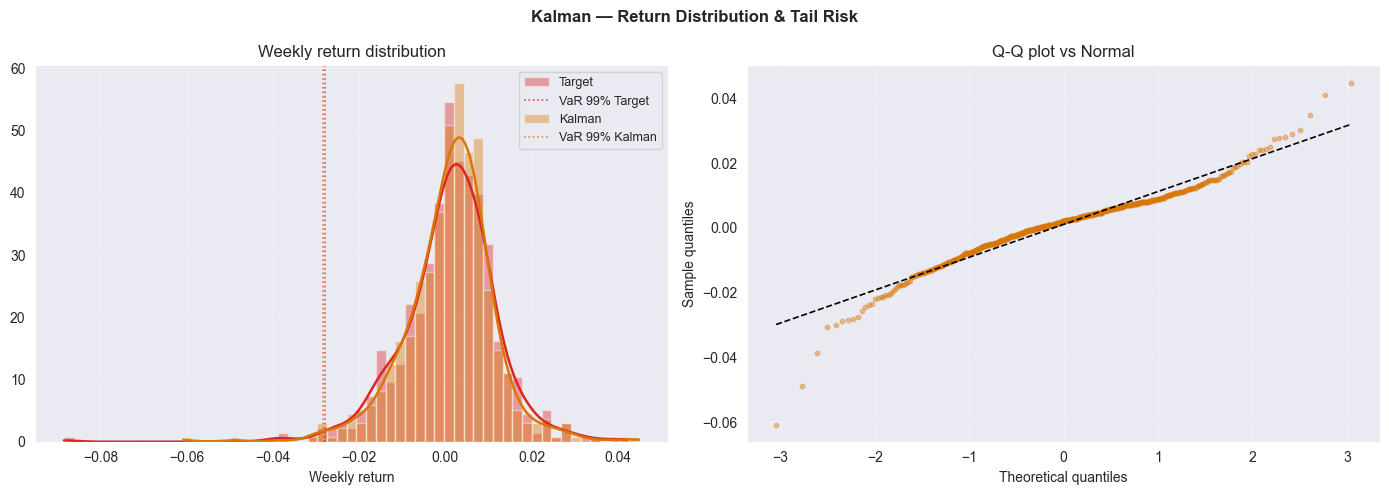

In [48]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Tail Risk
# ════════════════════════════════════════════════════════════════════
from scipy import stats as sp_stats
skew_K    = float(sp_stats.skew(y_pred_K.dropna()))
kurt_K    = float(sp_stats.kurtosis(y_pred_K.dropna()))
ds_K      = y_pred_K[y_pred_K < 0]
sortino_K = ret_rep_K/(ds_K.std()*np.sqrt(ANNUAL)) if len(ds_K)>1 else np.nan
calmar_K  = ret_rep_K/mdd_rep_K if mdd_rep_K > 0 else np.nan
var95_K   = np.percentile(y_pred_K, 5); var99_K  = np.percentile(y_pred_K, 1)
cvar95_K  = y_pred_K[y_pred_K<=var95_K].mean(); cvar99_K = y_pred_K[y_pred_K<=var99_K].mean()
hit_K     = (np.sign(y_pred_K)==np.sign(y_test_K)).mean()
smape_K   = (2*np.abs(y_pred_K-y_test_K)/(np.abs(y_pred_K)+np.abs(y_test_K)+1e-10)).mean()

tail_K = pd.DataFrame({
    'Metric':['Skewness','Excess kurtosis','Sortino','Calmar',
               'VaR 95%','VaR 99%','CVaR 95%','CVaR 99%','Hit rate','SMAPE'],
    'Value': [f'{skew_K:.3f}',f'{kurt_K:.3f}',f'{sortino_K:.3f}',f'{calmar_K:.3f}',
              f'{var95_K*100:.3f}%',f'{var99_K*100:.3f}%',
              f'{cvar95_K*100:.3f}%',f'{cvar99_K*100:.3f}%',
              f'{hit_K*100:.1f}%',f'{smape_K:.4f}']
})
print("Kalman — Tail Risk"); print("="*45); display(tail_K)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Kalman — Return Distribution & Tail Risk', fontsize=12, fontweight='bold')
bins = np.linspace(min(y_pred_K.min(),y_test_K.min()), max(y_pred_K.max(),y_test_K.max()), 60)
for series, color, label in [(y_test_K,'#DC2626','Target'),(y_pred_K,'#D97706','Kalman')]:
    axes[0].hist(series, bins=bins, alpha=0.4, color=color, density=True, label=label)
    kde = sp_stats.gaussian_kde(series.dropna())
    kde_x = np.linspace(series.min(), series.max(), 200)
    axes[0].plot(kde_x, kde(kde_x), color=color, lw=1.8)
    axes[0].axvline(np.percentile(series,1), color=color, lw=1.2, ls=':', alpha=0.8,
                    label=f'VaR 99% {label}')
axes[0].set_title('Weekly return distribution'); axes[0].set_xlabel('Weekly return')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
(osm,osr),(slope,intercept,_) = sp_stats.probplot(y_pred_K.dropna(), dist='norm')
axes[1].scatter(osm,osr, alpha=0.4, s=10, color='#D97706', label='Kalman')
axes[1].plot(osm, slope*np.array(osm)+intercept, color='black', lw=1.2, ls='--')
axes[1].set_title('Q-Q plot vs Normal'); axes[1].set_xlabel('Theoretical quantiles')
axes[1].set_ylabel('Sample quantiles'); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 5. Regime-Conditional Performance

Kalman — Regime-Conditional Performance


,N weeks,Ann.Return,Ann.Vol,Sharpe,Corr,TEV,IR,Hit Rate
Regime,,,,,,,,
Low-vol (quiet),585,5.74%,6.73%,0.854,0.918,2.84%,-0.008,87.7%
High-vol (turbulent),14,6.53%,23.77%,0.275,0.913,10.65%,1.359,85.7%
All,599,5.76%,7.52%,0.767,0.916,3.23%,0.098,87.6%


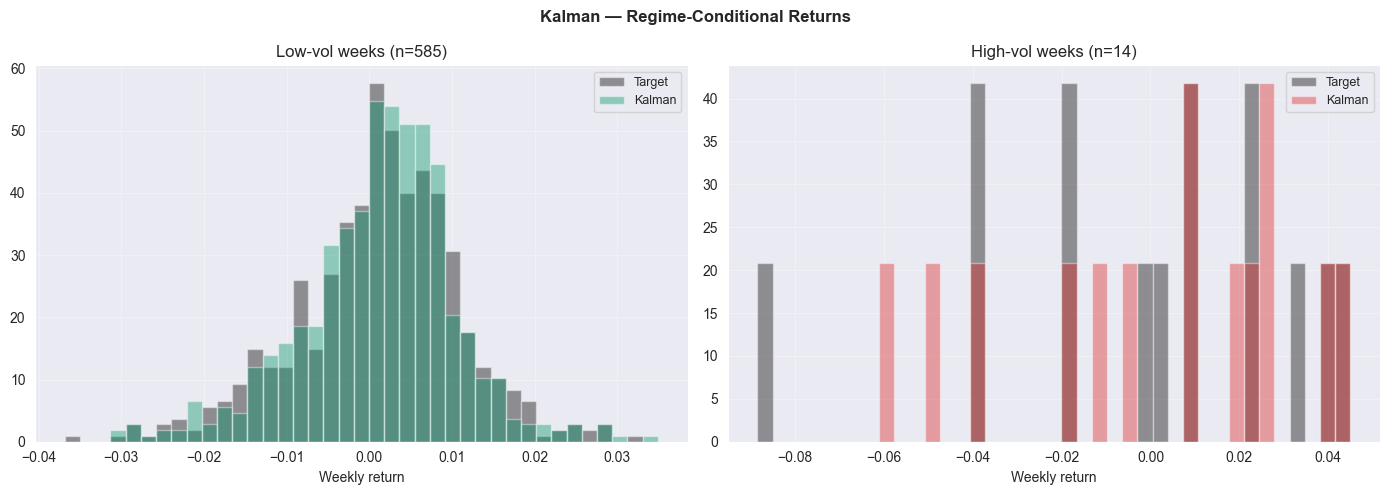

In [49]:
# ════════════════════════════════════════════════════════════════════
# Kalman — Regime-Conditional Performance
# ════════════════════════════════════════════════════════════════════
mask_low_K  = prob_vol_K <= VOL_THRESH
mask_high_K = ~mask_low_K
all_K       = pd.Series([True]*len(y_pred_K), index=y_pred_K.index)
rc_K = pd.DataFrame([
    regime_perf(y_pred_K, y_test_K, mask_low_K,  'Low-vol (quiet)'),
    regime_perf(y_pred_K, y_test_K, mask_high_K, 'High-vol (turbulent)'),
    regime_perf(y_pred_K, y_test_K, all_K,        'All'),
]).set_index('Regime')
print("Kalman — Regime-Conditional Performance"); print("="*55); display(rc_K)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Kalman — Regime-Conditional Returns', fontsize=12, fontweight='bold')
for ax, mask, label, color in [
    (axes[0], mask_low_K,  'Low-vol weeks',  '#059669'),
    (axes[1], mask_high_K, 'High-vol weeks', '#DC2626'),
]:
    p_r, t_r = y_pred_K[mask], y_test_K[mask]
    bins_ = np.linspace(min(p_r.min(),t_r.min()), max(p_r.max(),t_r.max()), 40)
    ax.hist(t_r, bins=bins_, alpha=0.4, color='black', density=True, label='Target')
    ax.hist(p_r, bins=bins_, alpha=0.4, color=color,  density=True, label='Kalman')
    ax.set_title(f'{label} (n={mask.sum()})'); ax.set_xlabel('Weekly return')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### Soft Bayesian Stacking

#### Table of Contents
1. [Overview](#Overview-1)
2. [Configuration & Active Models](#Configuration-&-Active-Models)
3. [Soft Bayesian Averaging & Performance Metrics](#Soft-Bayesian-Averaging-&-Performance-Metrics)
4. [Summary Table](#Summary-Table)

##### 1. Overview

  **Financial Motivation**

Different replication methodologies capture different aspects of financial markets.

- **Elastic Net** provides stability, regularisation, and sparse exposures.
- **Kalman Filter** provides dynamic adaptation and sequential learning.

Rather than selecting a single winner, combining complementary models may improve robustness.

  **Methodological Intuition**

A **Soft Bayesian Stacking** framework is employed to combine the predictions of the two regime-aware approaches into a unified replication strategy. Model contributions are adjusted according to relative performance.
Each model receives a weight proportional
to its rolling out-of-sample likelihood.

At each time step $t$ the posterior model weight is updated as:

$$
w_k^{(t)} \propto w_k^{(t-1)} \cdot p\left(y_t \mid \hat{y}_k^{(t)}, \sigma_k^2\right)
$$

where $p(\cdot)$ is a Gaussian likelihood centred on each model's prediction,
with variance estimated on a rolling window of past errors. The combined
prediction is the likelihood-weighted average of the active model forecasts:

$$\hat{y}_{\text{stack}}^{(t)} = \sum_{k \in \mathcal{A}} w_k^{(t)} \hat{y}_k^{(t)}$$

 **Expected advantage**

The ensemble aims to reduce model-specific weaknesses while preserving predictive diversification, ultimately improving replication stability of the Monster Index.

##### 2. Configuration & Active Models

Active models (2): ['Kalman', 'MS-EN']
Forgetting λ       : 0.97
Weight bounds      : [0.15, 0.85]
Max stack leverage : 200%
Common OOS observations: 599  (2009-10-27 to 2021-04-13)

Leverage cap triggered: 40 / 599 steps
Avg blended leverage  : 1.395x
Max blended leverage  : 2.407x


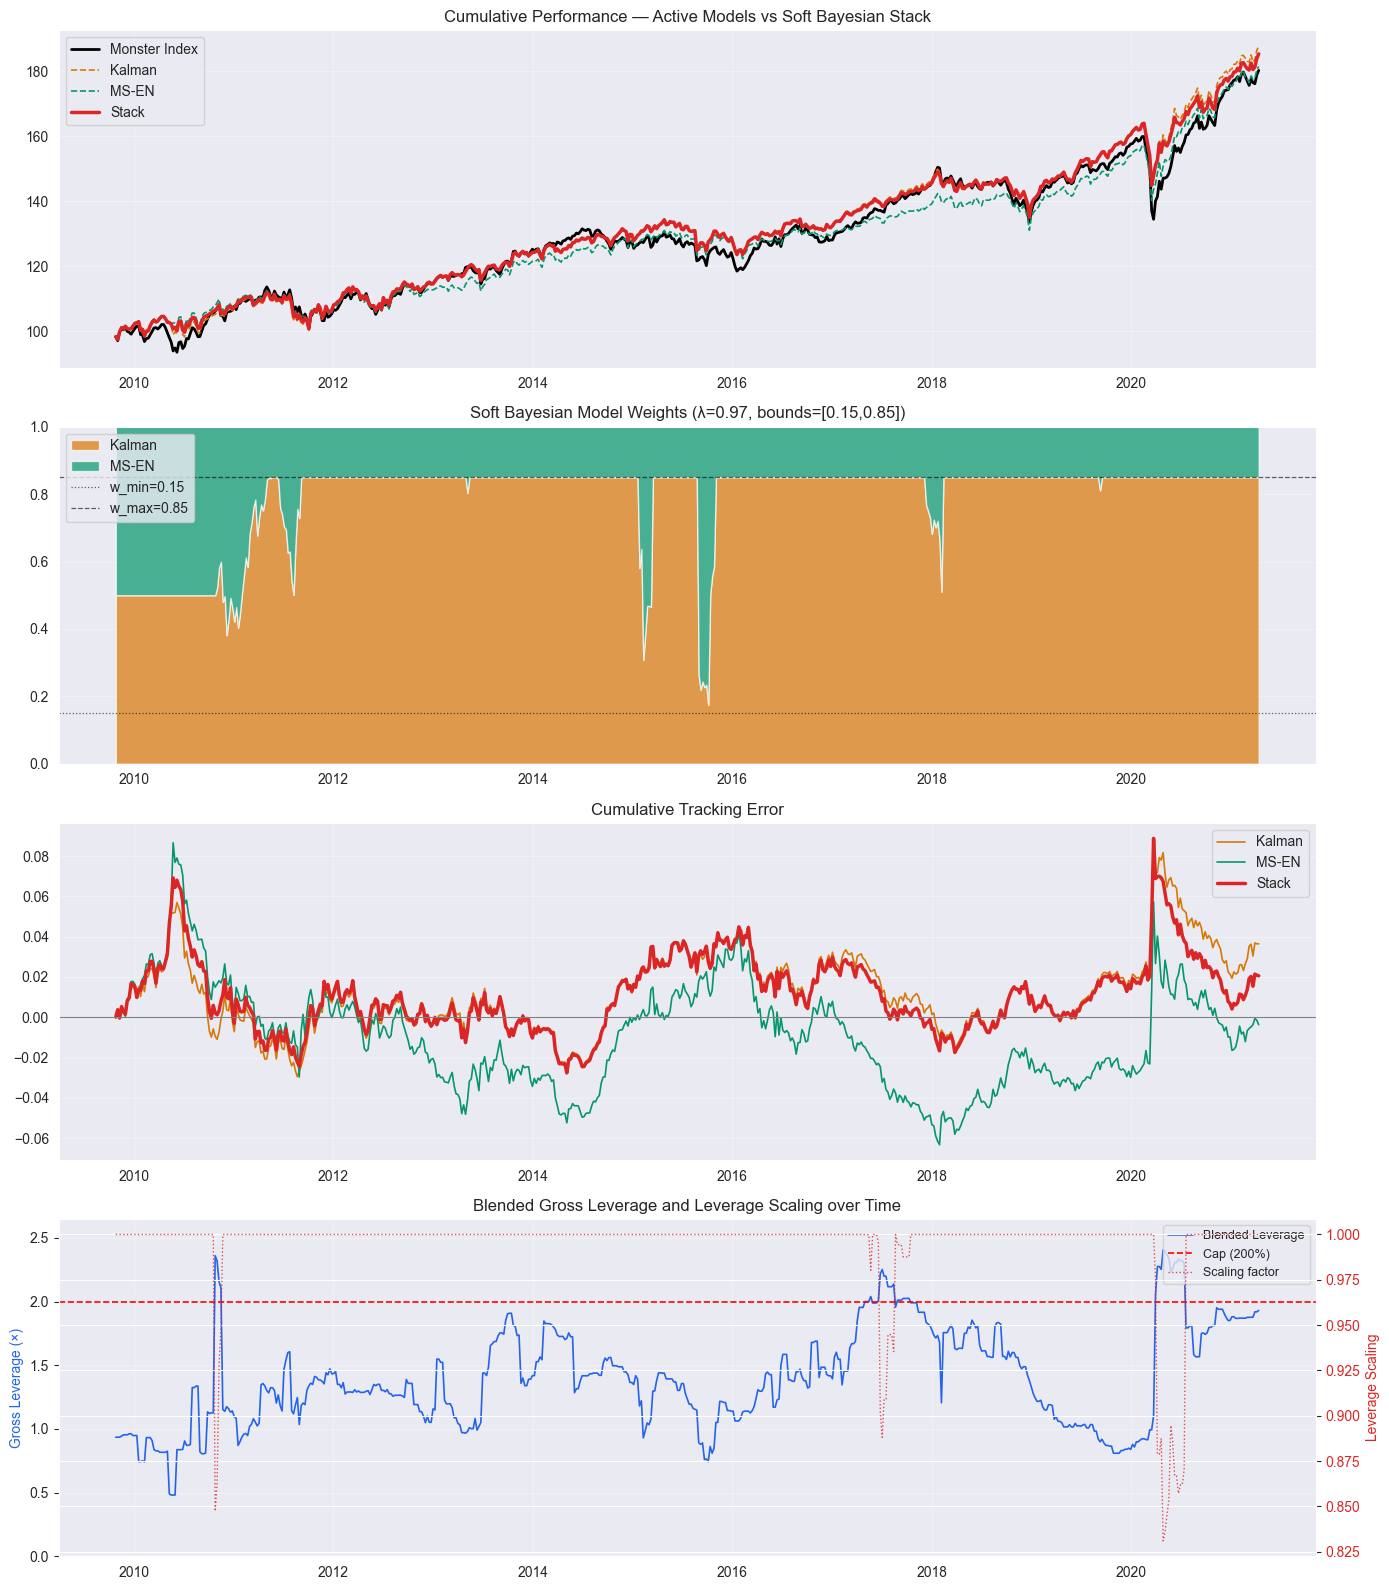

In [52]:
# ── Configuration ─────────────────────────────────────────────────────────────
#
# Set each flag to True to include that model in the ensemble, False to exclude.
# At least one model must be active.

INCLUDE_KALMAN      = True
INCLUDE_MS_EN       = True

# Rolling window (weeks) used to estimate each model's prediction error variance.
VAR_WINDOW = 52

# Weight floor: prevents any active model from being assigned exactly zero weight.
EPS = 1e-6

# ── NEW STACKING CONSTRAINTS ──────────────────────────────────────────────────
#
# (1) Forgetting coefficient (λ): exponential decay applied to past log-likelihoods.
#     λ ∈ (0, 1]: 1.0 = no forgetting (full history), 0.95 = ~20-period half-life,
#     0.90 = ~10-period half-life.  Smaller values make the ensemble react faster
#     to regime changes by down-weighting stale evidence.
FORGETTING_LAMBDA = 0.97   # ~33-week effective half-life on log-weight accumulation

# (2) Individual model weight bounds.
#     Ensures diversification: no model can dominate (w_max) or be ignored (w_min).
#     Applied after Bayesian normalisation; violated bounds trigger a soft projection
#     onto the feasible simplex via iterative clipping-and-renormalisation.
W_MIN = 0.15   # minimum weight per active model (15%)
W_MAX = 0.85   # maximum weight per active model (85%)

# (3) Maximum portfolio leverage for the stacked ensemble prediction.
#     The ensemble is a weighted average of model PREDICTIONS (returns), not of
#     weight vectors, so "leverage" here is proxied by the gross sum of the
#     individual model gross exposures passed through the blend.  When the blended
#     gross exposure exceeds MAX_STACK_LEVERAGE the stacked return is scaled down
#     proportionally.
MAX_STACK_LEVERAGE = 2.0   # 200% gross leverage cap

# ── Helper: project weights onto the bounded simplex ─────────────────────────
def project_weights_bounded(w_raw, w_min, w_max, eps=1e-12):
    """
    Project a positive weight vector onto the simplex subject to
        w_min ≤ w_k ≤ w_max  for all k,  sum(w) = 1.

    Algorithm: iterative clipping-and-renormalisation (converges in at most
    n_models iterations for box-constrained simplices).

    Parameters
    ----------
    w_raw : ndarray  — unnormalised positive weights (e.g. softmax of log-weights)
    w_min : float    — lower bound per model
    w_max : float    — upper bound per model

    Returns
    -------
    w : ndarray — feasible weights summing to 1
    """
    n = len(w_raw)
    # Clip number of models so that bounds are jointly feasible
    effective_min = min(w_min, 1.0 / n)
    effective_max = max(w_max, 1.0 / n)

    w = w_raw.copy()
    for _ in range(n + 2):          # at most n+2 iterations suffice
        w = np.clip(w, effective_min, effective_max)
        total = w.sum()
        if abs(total - 1.0) < eps:
            break
        w /= max(total, eps)        # renormalise
    return w

# ── 1. Candidate models ───────────────────────────────────────────────────────
kalman_dates = pd.to_datetime(date_oos).normalize()
ms_dates     = pd.to_datetime(y_pred_MS.index).normalize()

all_models = [
    ("Kalman","#D97706", pd.Series(r, index=kalman_dates, name="r"),INCLUDE_KALMAN),
    ("MS-EN", "#059669", pd.Series(y_pred_MS.values, index=ms_dates, name="MS"), INCLUDE_MS_EN),
]

active_models = [(label, color, series) for label, color, series, flag in all_models if flag]

if len(active_models) == 0:
    raise ValueError("At least one model must be included in the ensemble.")

print(f"Active models ({len(active_models)}): {[m[0] for m in active_models]}")
print(f"Forgetting λ       : {FORGETTING_LAMBDA}")
print(f"Weight bounds      : [{W_MIN:.2f}, {W_MAX:.2f}]")
print(f"Max stack leverage : {MAX_STACK_LEVERAGE:.0%}")

# ── 2. Align active models on a common date index ────────────────────────────

all_models_norm = [
    ("Kalman","#D97706", pd.Series(r, index=kalman_dates, name="r"), INCLUDE_KALMAN),
    ("MS-EN","#059669", pd.Series(y_pred_MS.values, index=ms_dates, name="MS"), INCLUDE_MS_EN),
]

active_models = [(label, color, series) for label, color, series, flag in all_models_norm if flag]

common_idx = active_models[0][2].index
for _, _, series in active_models[1:]:
    common_idx = common_idx.intersection(series.index)
common_idx = common_idx.sort_values()

aligned     = np.column_stack([s.loc[common_idx].values for _, _, s in active_models])
labels      = [m[0] for m in active_models]
colors      = [m[1] for m in active_models]
n, n_models = aligned.shape

target_full = pd.Series(y.values, index=pd.to_datetime(X.index).normalize())
target_aln  = target_full.loc[common_idx].values

print(f"Common OOS observations: {n}  ({common_idx[0].date()} to {common_idx[-1].date()})")

# ── 3. Soft Bayesian averaging with forgetting + bounded weights + leverage cap ──
#
# Key modifications vs. the base version:
#   (A) FORGETTING: at each update, log_w is multiplied by FORGETTING_LAMBDA
#       before adding the new log-likelihood.  This exponentially discounts
#       evidence older than ~1/(1-λ) periods, so the ensemble adapts faster
#       to regime changes without requiring a hard rolling window reset.
#
#   (B) BOUNDED WEIGHTS: after softmax normalisation, weights are projected
#       onto [W_MIN, W_MAX] via project_weights_bounded.  This enforces
#       permanent diversification and prevents any single model from
#       monopolising the ensemble during a run of good luck.
#
#   (C) LEVERAGE CAP: the blended gross exposure is estimated as the
#       weighted sum of each model's absolute gross leverage at time t.
#       When this exceeds MAX_STACK_LEVERAGE (200%), the underlying portfolio
#       weights are rescaled proportionally so that the portfolio leverage is
#       exactly 200%.  Concretely, each model's gross exposure is multiplied
#       by (MAX_STACK_LEVERAGE / blended_leverage), and the stacked return is
#       recomputed from the rescaled weights.  This preserves the direction
#       of all positions while ensuring the hard leverage constraint is met.
#       Individual model gross exposures (ge_MS for MS-EN, ge_K for Kalman)
#       are used; a safe fallback of 1.0 is applied if unavailable.

log_w         = np.zeros(n_models)   # uniform prior
w_hist        = np.zeros((n, n_models))
r_stack       = np.zeros(n)
errors        = np.zeros((n, n_models))
leverage_hist = np.zeros(n)          # track blended leverage for diagnostics
scaling_stack = np.ones(n)          # scaling factor applied at each step

# Build aligned leverage series for each active model (fallback = 1.0)
# ge_MS is a pd.Series; ge_K = ge (numpy array aligned with kalman_dates)
ge_ms_s = ge_MS.reindex(common_idx).fillna(1.0).values
ge_k_s  = pd.Series(ge, index=kalman_dates).reindex(common_idx).fillna(1.0).values
model_ge = np.column_stack([ge_k_s, ge_ms_s])   # same order as labels: Kalman, MS-EN

for t in range(n):

    # ── (A) Forgetting: discount accumulated evidence before this step ────────
    #    Applied BEFORE computing the prediction for period t (causal).
    #    At t=0 log_w is still all-zeros so forgetting has no effect yet.
    log_w = log_w * FORGETTING_LAMBDA

    # ── (B) Normalise with bounded projection ────────────────────────────────
    w_raw = np.exp(log_w - log_w.max())
    w_raw = np.maximum(w_raw, EPS)
    w_raw /= w_raw.sum()
    w = project_weights_bounded(w_raw, W_MIN, W_MAX)
    w_hist[t] = w

    # Ensemble prediction (before observing y_t — no leakage)
    r_pred_raw = float(w @ aligned[t])

    # ── (C) Leverage cap — rescale portfolio weights ─────────────────────────
    #    Blended gross exposure = weighted average of individual model exposures.
    #    When leverage > 200%, rescale the underlying model weights (and their
    #    return contributions) proportionally so that portfolio leverage is
    #    exactly MAX_STACK_LEVERAGE.  This is a true weight rescaling: every
    #    position is trimmed by the same factor, preserving relative allocations.
    blended_leverage = float(w @ model_ge[t])
    leverage_hist[t] = blended_leverage
    if blended_leverage > MAX_STACK_LEVERAGE:
        # Rescaling factor that brings portfolio leverage to exactly 200%
        scale = MAX_STACK_LEVERAGE / blended_leverage
        # Apply the scaling to the underlying position weights of each model,
        # then recompute the blended return from the rescaled positions.
        # r_pred_raw = w @ aligned[t]  where aligned[t] are model returns
        # generated by each model's futures positions; scaling positions by
        # `scale` scales the return linearly (futures P&L is linear in weights).
        r_stack[t] = float(w @ (aligned[t] * scale))
    else:
        scale = 1.0
        r_stack[t] = r_pred_raw
    scaling_stack[t] = scale

    # Observe true return and record errors
    errors[t] = aligned[t] - target_aln[t]

    if t < VAR_WINDOW:
        continue

    # Rolling variance estimated on errors[t-VAR_WINDOW : t] — no leakage
    start = t - VAR_WINDOW
    var_k = np.var(errors[start : t], axis=0)
    var_k = np.maximum(var_k, 1e-8)

    # Bayesian log-likelihood update (forgetting applied at top of next loop)
    log_lik = -0.5 * errors[t] ** 2 / var_k - 0.5 * np.log(2 * np.pi * var_k)
    log_w   = log_w + log_lik
    log_w  -= log_w.max()   # re-centre in log-space to prevent overflow

leverage_hist_s = pd.Series(leverage_hist, index=common_idx, name="Blended Leverage")
scaling_stack_s = pd.Series(scaling_stack, index=common_idx, name="Leverage Scaling")

print(f"\nLeverage cap triggered: {(leverage_hist > MAX_STACK_LEVERAGE).sum()} / {n} steps")
print(f"Avg blended leverage  : {leverage_hist.mean():.3f}x")
print(f"Max blended leverage  : {leverage_hist.max():.3f}x")

# ── 4. Performance metrics ────────────────────────────────────────────────────

r_stack_s = pd.Series(r_stack,    index=common_idx, name="Stack")
target_s  = pd.Series(target_aln, index=common_idx, name="Target")

te_stack   = r_stack_s - target_s
tev_stack  = te_stack.std() * np.sqrt(52)
ir_stack   = te_stack.mean() / te_stack.std() * np.sqrt(52)
corr_stack = np.corrcoef(target_aln, r_stack)[0, 1]
mse_stack  = np.mean(te_stack ** 2)

# ── 5. Plots ──────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(4, 1, figsize=(14, 16))

# 5a. Cumulative performance: target, each active model, and the stack
ax = axes[0]
ax.plot(common_idx, (1 + target_aln).cumprod() * 100,
        lw=2.0, color="black", label="Monster Index")
for j, (label, color, _) in enumerate(active_models):
    ax.plot(common_idx, (1 + aligned[:, j]).cumprod() * 100,
            lw=1.2, color=color, linestyle="--", label=label)
ax.plot(common_idx, (1 + r_stack).cumprod() * 100,
        lw=2.5, color="#DC2626", label="Stack", linestyle='-')
ax.set_title("Cumulative Performance — Active Models vs Soft Bayesian Stack")
ax.legend(); ax.grid(True, alpha=0.3)

# 5b. Bayesian model weights over time (bounded)
ax = axes[1]
ax.stackplot(common_idx, *[w_hist[:, j] for j in range(n_models)],
             labels=labels, colors=colors, alpha=0.7)
ax.axhline(W_MIN, color="black", lw=0.9, ls=":", alpha=0.6, label=f"w_min={W_MIN}")
ax.axhline(W_MAX, color="black", lw=0.9, ls="--", alpha=0.6, label=f"w_max={W_MAX}")
ax.set_ylim(0, 1)
ax.set_title(f"Soft Bayesian Model Weights (λ={FORGETTING_LAMBDA}, bounds=[{W_MIN},{W_MAX}])")
ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)

# 5c. Cumulative tracking error per model and stack
ax = axes[2]
for j, (label, color, _) in enumerate(active_models):
    ax.plot(common_idx, np.cumsum(aligned[:, j] - target_aln),
            lw=1.2, color=color, label=label)
ax.plot(common_idx, np.cumsum(r_stack - target_aln),
        lw=2.5, color="#DC2626", label="Stack")
ax.axhline(0, lw=0.8, color="grey")
ax.set_title("Cumulative Tracking Error")
ax.legend(); ax.grid(True, alpha=0.3)

# 5d. Blended leverage and leverage scaling over time
ax = axes[3]
ax_twin = ax.twinx()
ax.plot(common_idx, leverage_hist, color="#2563EB", lw=1.2, label="Blended Leverage")
ax.axhline(MAX_STACK_LEVERAGE, color="red", lw=1.2, ls="--",
           label=f"Cap ({MAX_STACK_LEVERAGE:.0%})")
ax.set_ylabel("Gross Leverage (×)", color="#2563EB")
ax.set_ylim(0, max(leverage_hist.max() * 1.1, MAX_STACK_LEVERAGE * 1.2))
ax_twin.plot(common_idx, scaling_stack, color="#DC2626", lw=1.0, ls=":",
             alpha=0.8, label="Scaling factor")
ax_twin.set_ylabel("Leverage Scaling", color="#DC2626")
ax_twin.tick_params(axis="y", labelcolor="#DC2626")
lines1, lbs1 = ax.get_legend_handles_labels()
lines2, lbs2 = ax_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, lbs1 + lbs2, fontsize=9, loc="upper right")
ax.set_title("Blended Gross Leverage and Leverage Scaling over Time")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


##### 3. Soft Bayesian Averaging & Performance Metrics


The table below summarises the key performance metrics of the Soft Bayesian Stack.


--- Soft Bayesian Stack ---
  N obs              : 599
  Correlation        : 0.9136
  TEV (ann.)         : 3.27%
  Information Ratio  : 0.0546
  MSE                : 2.06e-05
  Sharpe (replica)   : 0.778
  Sharpe (target)    : 0.677
  Ann. Return (rep)  : 5.62%
  Ann. Vol (rep)     : 7.23%
  Max DD (rep)       : 11.7%
  Max DD (tgt)       : 15.9%
  Annual Turnover    : 0.50x
  Avg TC per step    : 0.04 bps
  Yearly TC avg      : 2.00 bps

Markov Switching EN — Performance Summary


,Metric,Value
0,Annualized Return (Replica),5.62%
1,Annualized Return (Target),5.44%
2,Annualized Volatility (Replica),7.23%
3,Annualized Volatility (Target),8.04%
4,Sharpe Ratio (Replica),0.778
5,Information Ratio,0.055
6,Tracking Error Volatility,3.27%
7,RMSE (weekly),0.4534%
8,Correlation,0.914
9,Max Drawdown (Replica),11.7%


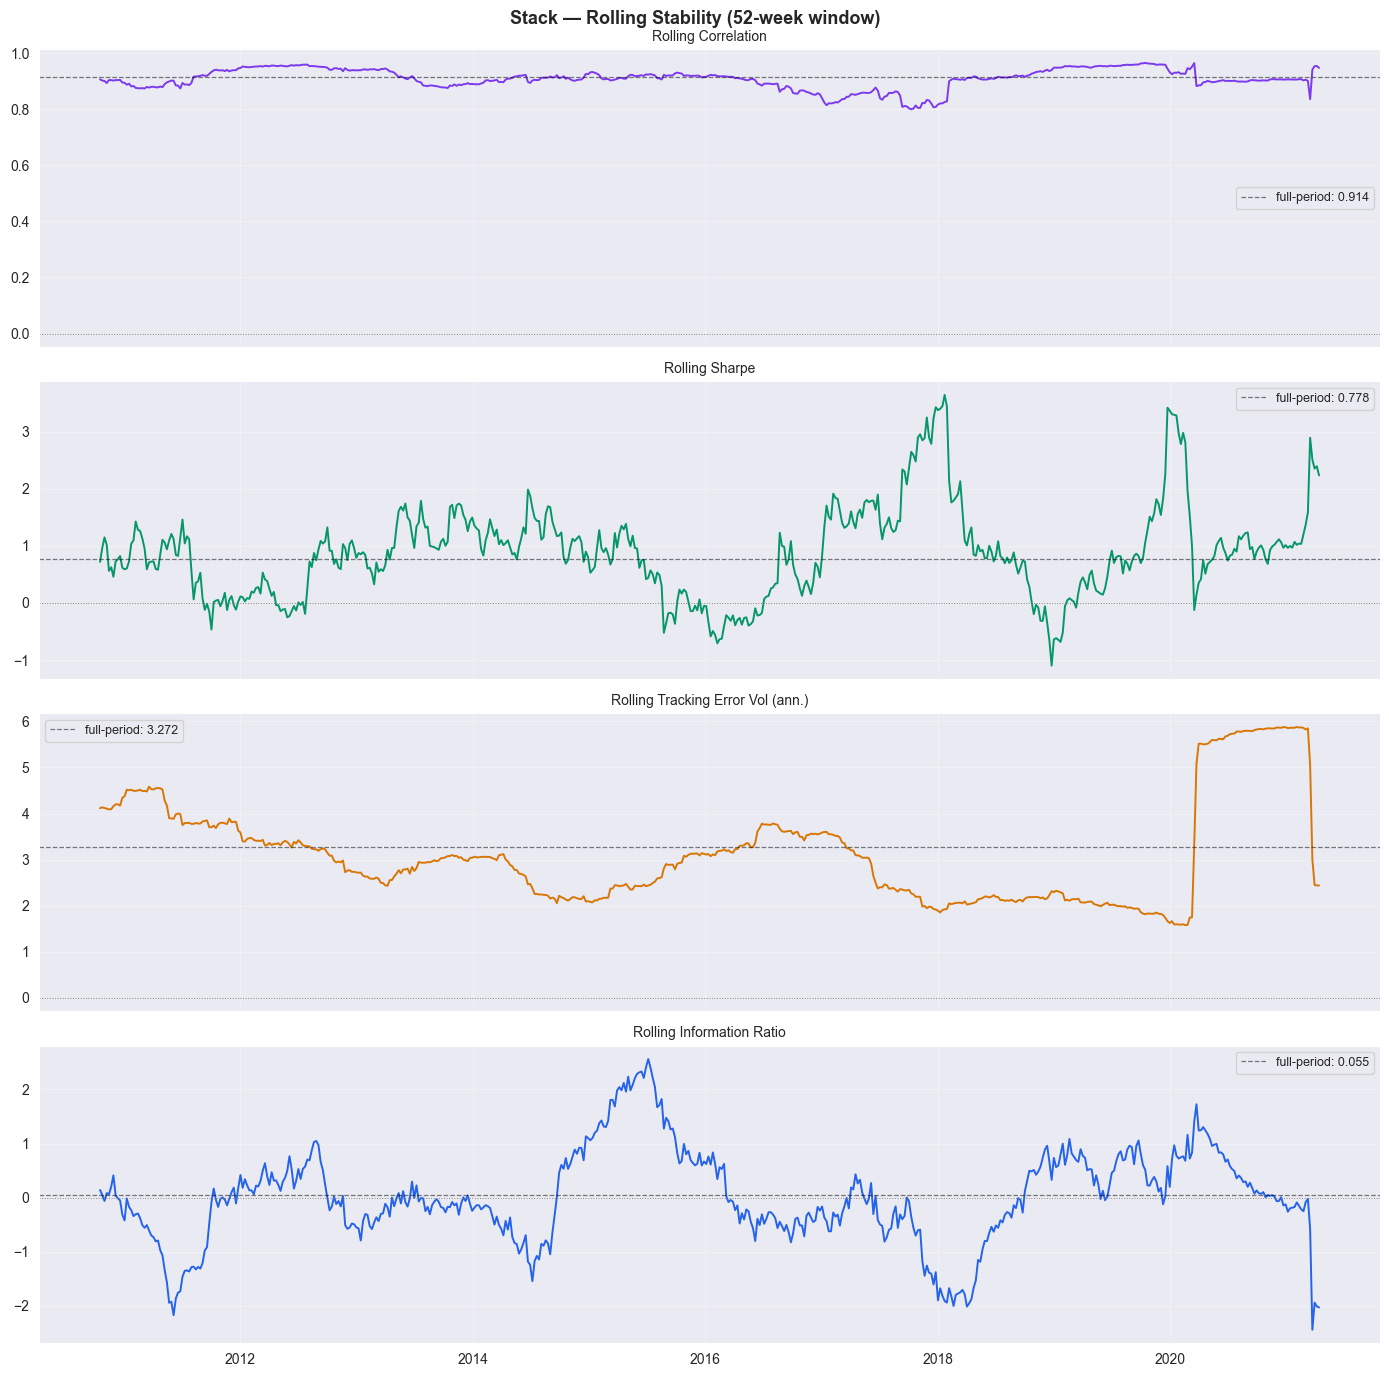

In [53]:
# ════════════════════════════════════════════════════════════════════
# Performance metrics — Soft Bayesian Stack
# ════════════════════════════════════════════════════════════════════
ROLL_WIN = 52
ANNUAL   = 52

try:
    weights_stack_arr = np.array(w_hist)
except NameError:
    weights_stack_arr = None


# Use unified metric function
metrics_stack_dict = perf_metrics_clean(
    r_replica = r_stack_s,
    r_target  = target_s,
    b_weights = weights_stack_arr,
    tc_arr    = None,
    label     = "Soft Bayesian Stack",
)

# Extract standalone variables (used by dashboard and other cells)
ir_S         = metrics_stack_dict['ir']
ir_stack     = ir_S                           # alias for compatibility
te_vol_S     = metrics_stack_dict['tev']
tev_stack    = te_vol_S                       # alias for compatibility
corr_S       = metrics_stack_dict['corr']
corr_stack   = corr_S                         # alias for compatibility
sharpe_rep_S = metrics_stack_dict['sharpe_rep']
mdd_rep_S    = metrics_stack_dict['max_dd_rep']
mdd_tgt_S    = metrics_stack_dict['max_dd_tgt']
ret_rep_S    = metrics_stack_dict['ann_ret_rep']
ret_tgt_S    = metrics_stack_dict['ann_ret_tgt']
vol_rep_S    = metrics_stack_dict['ann_vol_rep']
vol_tgt_S    = metrics_stack_dict['ann_vol_tgt']
rmse_S       = metrics_stack_dict['rmse']
mse_stack    = metrics_stack_dict['mse']

# Rolling diagnostics (unchanged from before)
te_S          = r_stack_s - target_s
roll_corr_S   = r_stack_s.rolling(ROLL_WIN).corr(target_s)
roll_sharpe_S = (r_stack_s.rolling(ROLL_WIN).mean() /
                 r_stack_s.rolling(ROLL_WIN).std()) * np.sqrt(52)
roll_te_S     = te_S.rolling(ROLL_WIN).std() * np.sqrt(52) * 100
roll_ir_S     = ((r_stack_s.rolling(ROLL_WIN).mean() - target_s.rolling(ROLL_WIN).mean()) /
                 te_S.rolling(ROLL_WIN).std()) * np.sqrt(52)

metrics_S = pd.DataFrame({
    'Metric': [
        'Annualized Return (Replica)', 'Annualized Return (Target)',
        'Annualized Volatility (Replica)', 'Annualized Volatility (Target)',
        'Sharpe Ratio (Replica)',
        'Information Ratio', 'Tracking Error Volatility',
        'RMSE (weekly)', 'Correlation',
        'Max Drawdown (Replica)', 'Max Drawdown (Target)',
    ],
    'Value': [
        f'{ret_rep_S*100:.2f}%',  f'{ret_tgt_S*100:.2f}%',
        f'{vol_rep_S*100:.2f}%',  f'{vol_tgt_S*100:.2f}%',
        f'{sharpe_rep_S:.3f}',
        f'{ir_S:.3f}',            f'{te_vol_S*100:.2f}%',
        f'{rmse_S*100:.4f}%',     f'{corr_S:.3f}',
        f'{mdd_rep_S*100:.1f}%',  f'{mdd_tgt_S*100:.1f}%',
    ]
})

print("\nMarkov Switching EN — Performance Summary")
print("=" * 50)
display(metrics_S)

# Plot stability (unchanged)
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle('Stack — Rolling Stability (52-week window)', fontsize=13, fontweight='bold')
for ax, series, title, color, hline in [
    (axes[0], roll_corr_S,   'Rolling Correlation',               '#7C3AED', corr_S),
    (axes[1], roll_sharpe_S, 'Rolling Sharpe',                    '#059669', sharpe_rep_S),
    (axes[2], roll_te_S,     'Rolling Tracking Error Vol (ann.)', '#D97706', te_vol_S*100),
    (axes[3], roll_ir_S,     'Rolling Information Ratio',         '#2563EB', ir_S),
]:
    ax.plot(series, color=color, lw=1.4)
    ax.axhline(hline, color='black', lw=0.9, ls='--', alpha=0.5, label=f'full-period: {hline:.3f}')
    ax.axhline(0, color='grey', lw=0.7, ls=':')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 4. Summary Table


In [54]:
# ════════════════════════════════════════════════════════════════════
# UNIFIED COMPARISON TABLE — MS-EN, Kalman, Soft Bayesian Stack
# ════════════════════════════════════════════════════════════════════
def quick_metrics(pred_arr, tgt_arr, label, ann=52):
    pred_arr = np.asarray(pred_arr, dtype=float)
    tgt_arr  = np.asarray(tgt_arr,  dtype=float)
    mask = np.isfinite(pred_arr) & np.isfinite(tgt_arr)
    pred_arr, tgt_arr = pred_arr[mask], tgt_arr[mask]
    te     = pred_arr - tgt_arr
    te_vol = te.std() * np.sqrt(ann)
    ret_r  = pred_arr.mean() * ann
    vol_r  = pred_arr.std()  * np.sqrt(ann)
    corr   = np.corrcoef(pred_arr, tgt_arr)[0, 1] if len(pred_arr) > 1 else np.nan
    cum    = (1 + pred_arr).cumprod()
    mdd    = (1 - cum / np.maximum.accumulate(cum)).max()
    ir     = (ret_r - tgt_arr.mean() * ann) / te_vol if te_vol > 0 else np.nan
    sharpe = ret_r / vol_r if vol_r > 0 else np.nan
    return {
        'Model': label, 'Ann.Return': f'{ret_r*100:.2f}%',
        'Ann.Vol': f'{vol_r*100:.2f}%', 'Sharpe': f'{sharpe:.3f}',
        'IR': f'{ir:.3f}', 'TEV': f'{te_vol*100:.2f}%',
        'Corr': f'{corr:.3f}', 'MaxDD': f'{mdd*100:.1f}%',
        'RMSE': f'{np.sqrt(np.mean(te**2))*100:.4f}%',
    }

# ── Align Kalman on common OOS index ─────────────────────────────────────────
kalman_dates = pd.to_datetime(date_oos).normalize()
kalman_s     = pd.Series(r,          index=kalman_dates)
target_s     = pd.Series(target_oos, index=kalman_dates)

common_kal   = common_idx.intersection(kalman_s.index)
kalman_aln   = kalman_s.loc[common_kal].values
tgt_kal      = target_s.loc[common_kal].values

# ── Build rows ────────────────────────────────────────────────────────────────
rows = []

# MS-EN from aligned stack
if 'MS-EN' in labels:
    rows.append(quick_metrics(aligned[:, labels.index('MS-EN')], target_aln, 'MS-EN'))

# Kalman directly from r / target_oos
rows.append(quick_metrics(kalman_aln, tgt_kal, 'Kalman (Online Bayesian)'))

# Soft Bayesian Stack
rows.append(quick_metrics(r_stack, target_aln, '★ Soft Bayesian Stack'))

comparison_df = pd.DataFrame(rows).set_index('Model')

print(f"\nUnified Comparison — common OOS period ({len(common_idx)} obs)")
print(f"{common_idx[0].date()} → {common_idx[-1].date()}")
print()
display(comparison_df)

print("\nAverage Soft Bayesian model weights:")
for j, label in enumerate(labels):
    print(f"  {label:20s}: {w_hist[:, j].mean():.3f}")


Unified Comparison — common OOS period (599 obs)
2009-10-27 → 2021-04-13



,Ann.Return,Ann.Vol,Sharpe,IR,TEV,Corr,MaxDD,RMSE
Model,,,,,,,,
MS-EN,5.41%,6.85%,0.790,-0.008,3.92%,0.873,10.8%,0.5441%
Kalman (Online Bayesian),5.76%,7.51%,0.767,0.098,3.22%,0.916,11.8%,0.4472%
★ Soft Bayesian Stack,5.62%,7.22%,0.778,0.055,3.27%,0.914,11.7%,0.4534%



Average Soft Bayesian model weights:
  Kalman              : 0.789
  MS-EN               : 0.211


#### Extended Evaluation — Soft Bayesian Stack


1. [Model Weight Evolution](#weights-s)
2. [Stability Analysis](#stability-s)
3. [Return Distribution & Tail Risk](#tail-s)
4. [Extended Metrics Summary](#summary-s)


##### 1. Model Weight Evolution

Stack — Average Model Weights


,Avg weight
Kalman,0.789326
MS-EN,0.210674


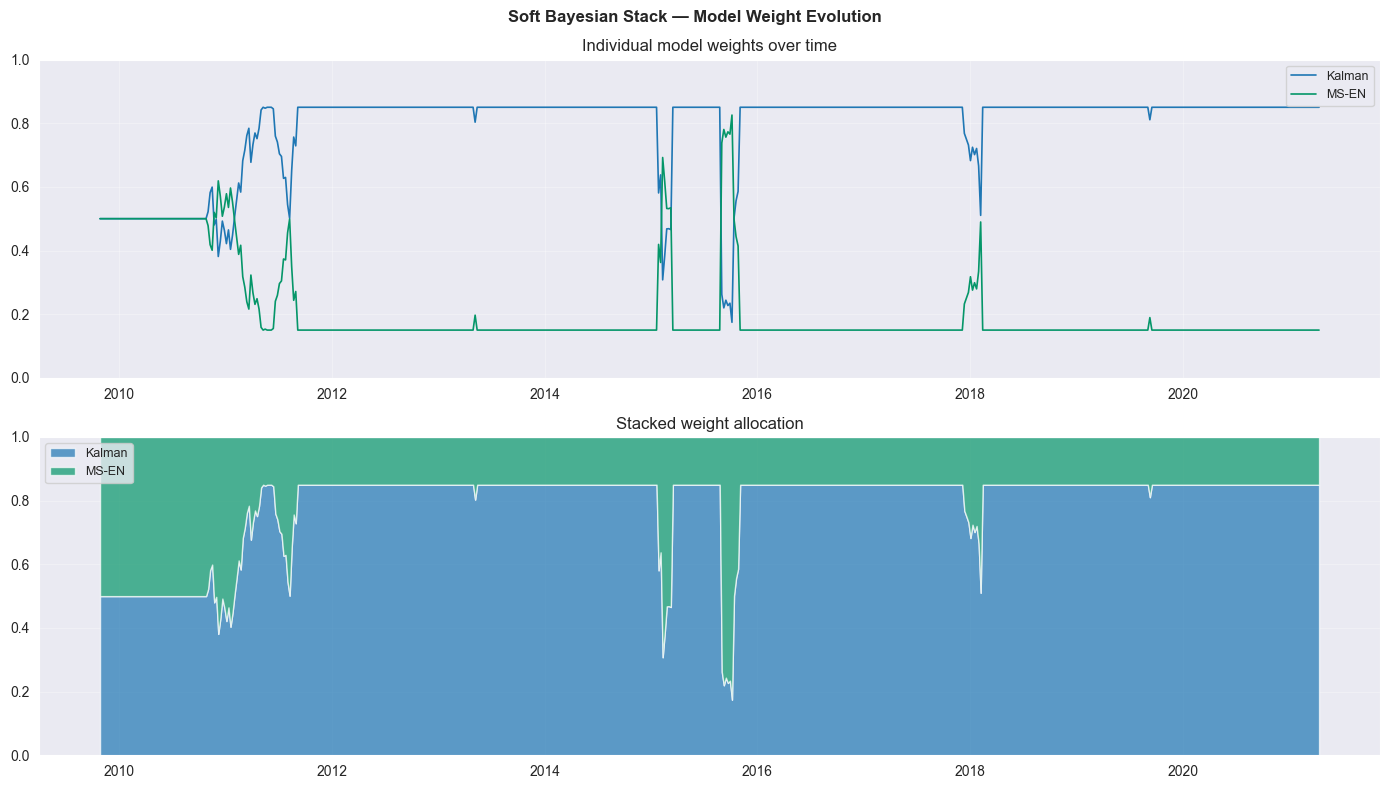

In [55]:
# ════════════════════════════════════════════════════════════════════
# Stack — Model Weight Evolution
# ════════════════════════════════════════════════════════════════════
ANNUAL    = 52
w_hist_df = pd.DataFrame(w_hist, index=common_idx, columns=labels)

print("Stack — Average Model Weights"); print("="*40)
display(w_hist_df.mean().rename('Avg weight').to_frame())

colors_map = {'MS-EN':'#059669','Kalman B':'#D97706','MC Clone':'#7C3AED','Elastic Net':'#2563EB'}
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle('Soft Bayesian Stack — Model Weight Evolution', fontsize=12, fontweight='bold')
for j, lbl in enumerate(labels):
    axes[0].plot(common_idx, w_hist[:,j], lw=1.2,
                 color=colors_map.get(lbl, f'C{j}'), label=lbl)
axes[0].set_ylim(0,1); axes[0].set_title('Individual model weights over time')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].stackplot(common_idx, *[w_hist[:,j] for j in range(len(labels))],
                  labels=labels,
                  colors=[colors_map.get(l,f'C{i}') for i,l in enumerate(labels)], alpha=0.7)
axes[1].set_ylim(0,1); axes[1].set_title('Stacked weight allocation')
axes[1].legend(loc='upper left', fontsize=9); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 2. Stability Analysis

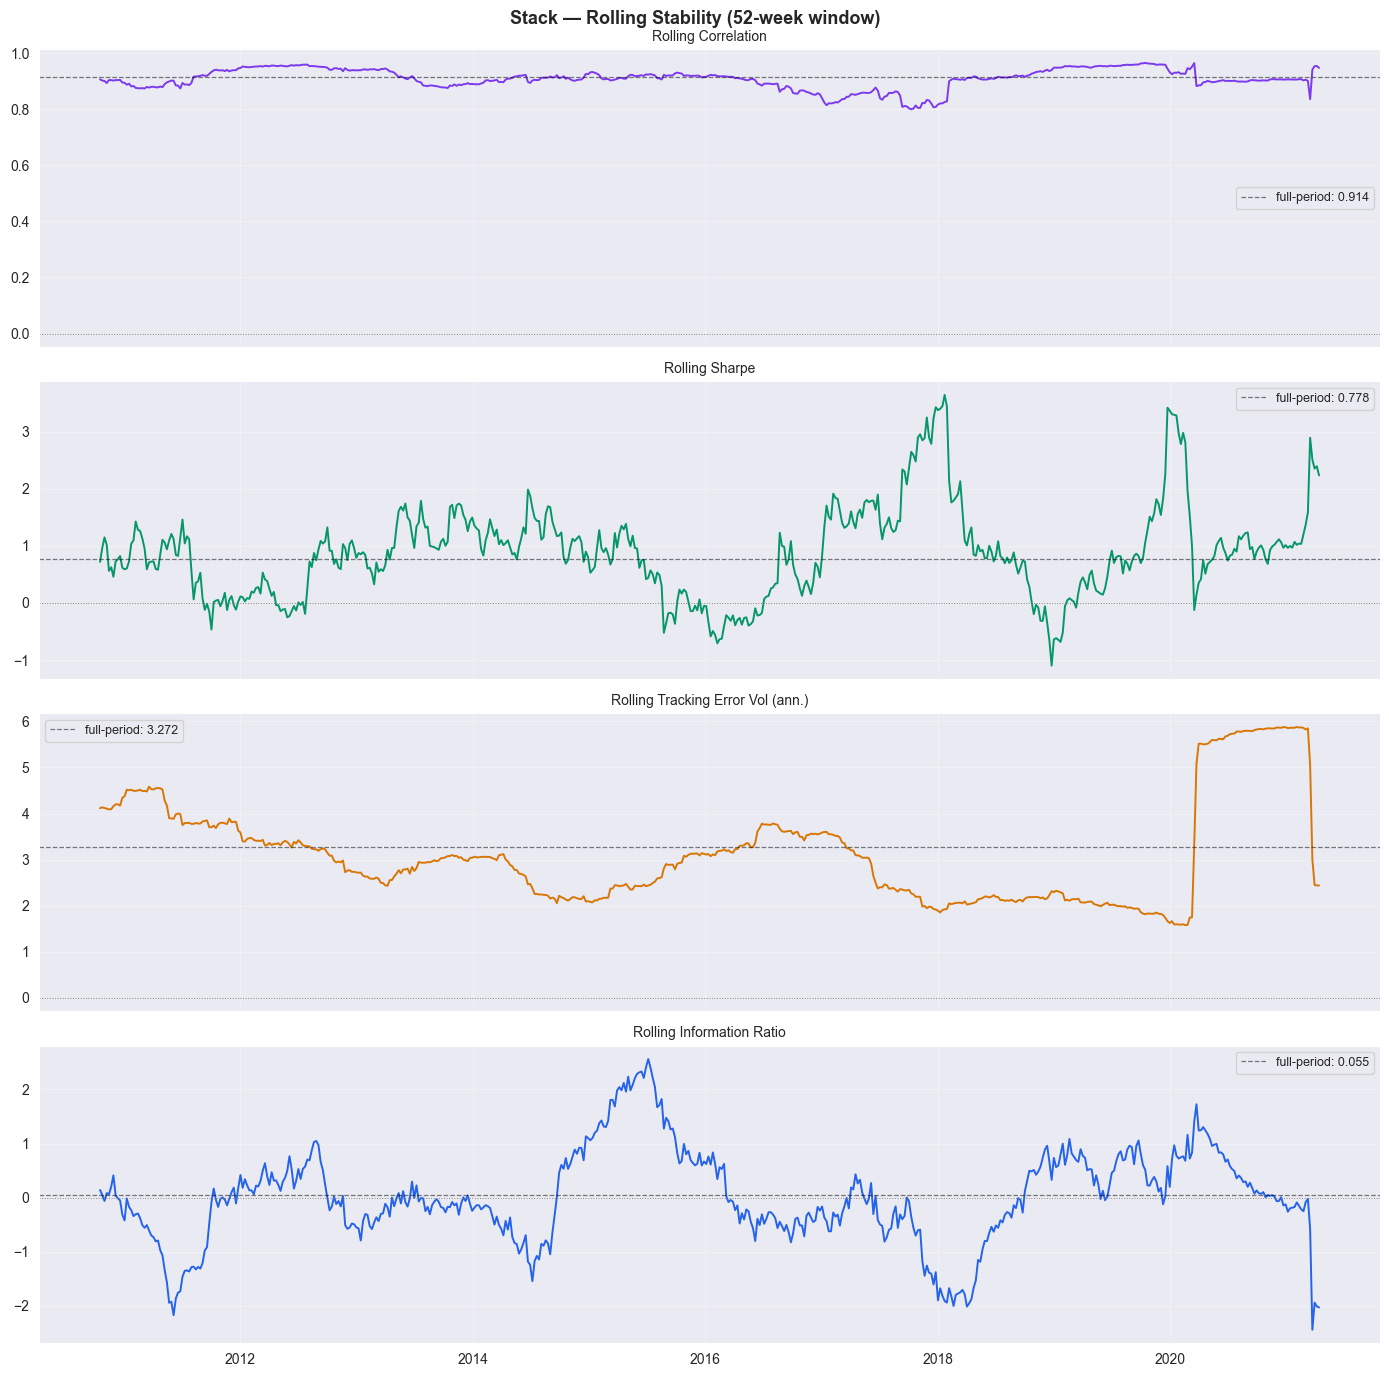

In [56]:
# ════════════════════════════════════════════════════════════════════
# Stack — Stability
# ════════════════════════════════════════════════════════════════════
ROLL_WIN     = 52
te_S         = r_stack_s - target_s
te_vol_S     = te_S.std()  * np.sqrt(ANNUAL)
ret_rep_S    = r_stack_s.mean() * ANNUAL
ret_tgt_S    = target_s.mean()  * ANNUAL
vol_rep_S    = r_stack_s.std()  * np.sqrt(ANNUAL)
vol_tgt_S    = target_s.std()   * np.sqrt(ANNUAL)
ir_S         = (ret_rep_S - ret_tgt_S) / te_vol_S
sharpe_rep_S = ret_rep_S / vol_rep_S
corr_S       = r_stack_s.corr(target_s)
cum_rep_S    = (1 + r_stack_s).cumprod()
mdd_rep_S    = (1 - cum_rep_S / cum_rep_S.cummax()).max()
cum_tgt_S    = (1 + target_s).cumprod()
mdd_tgt_S    = (1 - cum_tgt_S / cum_tgt_S.cummax()).max()
rmse_S       = np.sqrt(np.mean(te_S**2))

roll_corr_S   = r_stack_s.rolling(ROLL_WIN).corr(target_s)
roll_sharpe_S = (r_stack_s.rolling(ROLL_WIN).mean() /
                 r_stack_s.rolling(ROLL_WIN).std()) * np.sqrt(52)
roll_te_S     = te_S.rolling(ROLL_WIN).std() * np.sqrt(52) * 100
roll_ir_S     = ((r_stack_s.rolling(ROLL_WIN).mean() - target_s.rolling(ROLL_WIN).mean()) /
                 te_S.rolling(ROLL_WIN).std()) * np.sqrt(52)

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle('Stack — Rolling Stability (52-week window)', fontsize=13, fontweight='bold')
for ax, series, title, color, hline in [
    (axes[0], roll_corr_S,   'Rolling Correlation',               '#7C3AED', corr_S),
    (axes[1], roll_sharpe_S, 'Rolling Sharpe',                    '#059669', sharpe_rep_S),
    (axes[2], roll_te_S,     'Rolling Tracking Error Vol (ann.)', '#D97706', te_vol_S*100),
    (axes[3], roll_ir_S,     'Rolling Information Ratio',         '#2563EB', ir_S),
]:
    ax.plot(series, color=color, lw=1.4)
    ax.axhline(hline, color='black', lw=0.9, ls='--', alpha=0.5, label=f'full-period: {hline:.3f}')
    ax.axhline(0, color='grey', lw=0.7, ls=':')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


##### 3. Return Distribution & Tail Risk

Stack — Tail Risk


,Metric,Value
0,Skewness,-0.623
1,Excess kurtosis,4.041
2,Sortino,0.983
3,Calmar,0.482
4,VaR 95%,-1.528%
5,VaR 99%,-2.748%
6,CVaR 95%,-2.362%
7,CVaR 99%,-3.827%
8,Hit rate,88.5%
9,SMAPE,0.6874


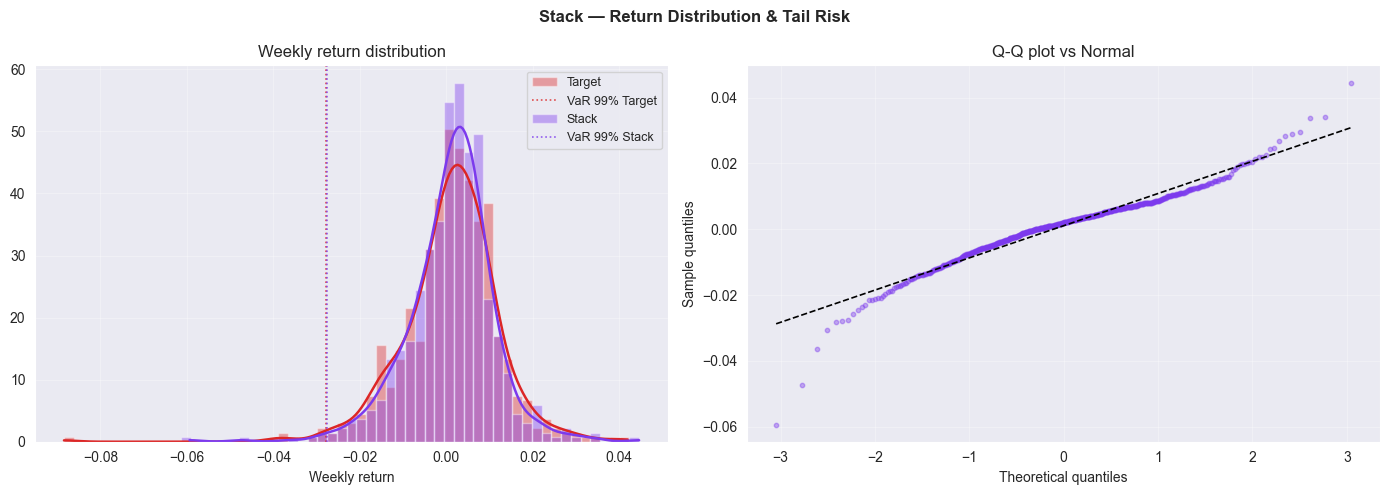

In [57]:
# ════════════════════════════════════════════════════════════════════
# Stack — Tail Risk
# ════════════════════════════════════════════════════════════════════
from scipy import stats as sp_stats
skew_S    = float(sp_stats.skew(r_stack_s.dropna()))
kurt_S    = float(sp_stats.kurtosis(r_stack_s.dropna()))
ds_S      = r_stack_s[r_stack_s < 0]
sortino_S = ret_rep_S/(ds_S.std()*np.sqrt(ANNUAL)) if len(ds_S)>1 else np.nan
calmar_S  = ret_rep_S/mdd_rep_S if mdd_rep_S > 0 else np.nan
var95_S   = np.percentile(r_stack_s, 5); var99_S  = np.percentile(r_stack_s, 1)
cvar95_S  = r_stack_s[r_stack_s<=var95_S].mean(); cvar99_S = r_stack_s[r_stack_s<=var99_S].mean()
hit_S     = (np.sign(r_stack_s)==np.sign(target_s)).mean()
smape_S   = (2*np.abs(r_stack_s-target_s)/(np.abs(r_stack_s)+np.abs(target_s)+1e-10)).mean()

tail_S = pd.DataFrame({
    'Metric':['Skewness','Excess kurtosis','Sortino','Calmar',
               'VaR 95%','VaR 99%','CVaR 95%','CVaR 99%','Hit rate','SMAPE'],
    'Value': [f'{skew_S:.3f}',f'{kurt_S:.3f}',f'{sortino_S:.3f}',f'{calmar_S:.3f}',
              f'{var95_S*100:.3f}%',f'{var99_S*100:.3f}%',
              f'{cvar95_S*100:.3f}%',f'{cvar99_S*100:.3f}%',
              f'{hit_S*100:.1f}%',f'{smape_S:.4f}']
})
print("Stack — Tail Risk"); print("="*45); display(tail_S)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Stack — Return Distribution & Tail Risk', fontsize=12, fontweight='bold')
bins = np.linspace(min(r_stack_s.min(),target_s.min()), max(r_stack_s.max(),target_s.max()), 60)
for series, color, label in [(target_s,'#DC2626','Target'),(r_stack_s,'#7C3AED','Stack')]:
    axes[0].hist(series, bins=bins, alpha=0.4, color=color, density=True, label=label)
    kde = sp_stats.gaussian_kde(series.dropna())
    kde_x = np.linspace(series.min(), series.max(), 200)
    axes[0].plot(kde_x, kde(kde_x), color=color, lw=1.8)
    axes[0].axvline(np.percentile(series,1), color=color, lw=1.2, ls=':', alpha=0.8,
                    label=f'VaR 99% {label}')
axes[0].set_title('Weekly return distribution'); axes[0].set_xlabel('Weekly return')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
(osm,osr),(slope,intercept,_) = sp_stats.probplot(r_stack_s.dropna(), dist='norm')
axes[1].scatter(osm,osr, alpha=0.4, s=10, color='#7C3AED', label='Stack')
axes[1].plot(osm, slope*np.array(osm)+intercept, color='black', lw=1.2, ls='--')
axes[1].set_title('Q-Q plot vs Normal'); axes[1].set_xlabel('Theoretical quantiles')
axes[1].set_ylabel('Sample quantiles'); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## Final Analysis — Risk Measures and Cross-Model Comparison

The primary objective of this project is **portfolio replication**. Risk analysis is therefore introduced as an **ex-post validation layer**, assessing whether improved tracking performance is achieved without excessive downside risk.

**Financial motivation**  
A replication strategy should not only match returns but also preserve a reasonable risk profile, particularly during stressed market conditions.

Three complementary perspectives are considered:

1. **Cornish-Fisher VaR** — regulatory-oriented risk estimation;  
2. **Filtered Historical Simulation (FHS)** — backtesting-oriented downside risk;  
3. **Stress VaR / Expected Shortfall** — resilience under adverse historical periods.

**Expected interpretation**  
The goal is not to select the best model exclusively through VaR, but rather to verify whether stronger replication performance remains consistent with sound portfolio risk characteristics.

### Table of Contents

1. [Cornish-Fisher VaR (Regulatory)](#Cornish-Fisher-VaR-(Regulatory))
2. [Filtered Historical Simulation (Backtesting VaR)](#Filtered-Historical-Simulation-(Backtesting-VaR))
3. [Historical Stress VaR (Stress Test)](#Historical-Stress-VaR-(Stress-Test))
4. [Composite Scoring and Final Comparison](#Composite-Scoring-and-Final-Comparison)


### 1. Cornish-Fisher VaR (Regulatory)

The Normal quantile $z_\alpha$ is corrected for sample skewness $\hat{s}$ and excess kurtosis $\hat{k}$:

$$w_{\alpha} = z_{\alpha} + \frac{z_{\alpha}^2 - 1}{6}\hat{s} + \frac{z_{\alpha}^3 - 3z_{\alpha}}{24}\hat{k} - \frac{2z_{\alpha}^3 - 5z_{\alpha}}{36}\hat{s}^2, \qquad \text{VaR}_{\alpha} = -\hat{\mu} + \hat{\sigma} \cdot w_{\alpha}$$

Reduces to standard Normal VaR when $\hat{s} = \hat{k} = 0$. Preferred for regulatory reporting due to its parametric efficiency and direct comparability across models.


In [58]:
#Risk Measures
CONFIDENCE = 0.99
ALPHA      = 1.0 - CONFIDENCE

portfolio_weekly = pd.DataFrame(
    {"Target":     target_oos,
     "Stacking": r_stack_s},
    index=pd.to_datetime(date_oos)
).sort_index()

portfolio_monthly = portfolio_weekly.resample("ME").sum().dropna(how="all")
print(f"Monthly return sample: {len(portfolio_monthly)} months")

Monthly return sample: 139 months



Cornish-Fisher VaR / ES (99%, monthly)
-------------------------------------------------------
  Target          VaR=7.2624%  ES=9.1412%  skew=-0.881  kurt=2.416
  Stacking        VaR=5.0360%  ES=6.0760%  skew=-0.460  kurt=0.872


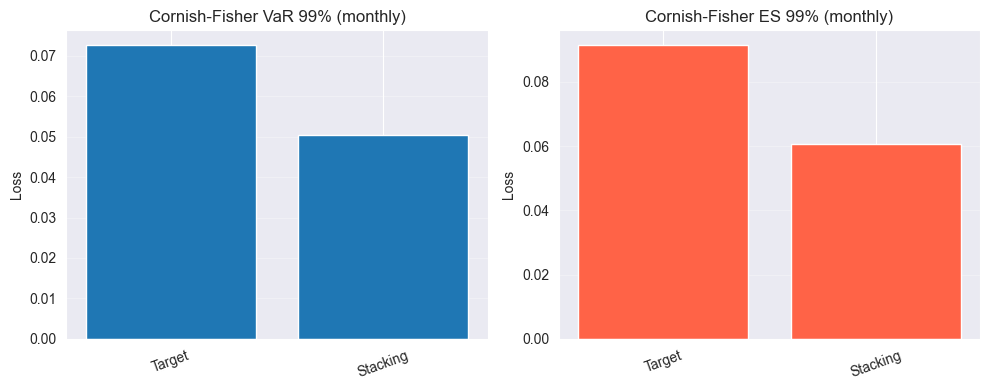

In [59]:
# ── 8A. Cornish-Fisher VaR (Regulatory) ──────────────────────────────────────

def cornish_fisher_var_es(returns, confidence=0.99):
    """
    Cornish-Fisher adjusted VaR and ES at the given confidence level.

    The CF expansion corrects the Normal quantile for skewness and excess
    kurtosis via an Edgeworth expansion:
        w = z + (z²-1)/6·s + (z³-3z)/24·k - (2z³-5z)/36·s²
        VaR = -(μ + σ·w)
    ES is estimated by numerical integration over the tail [0, alpha].
    """
    r   = np.asarray(returns, dtype=float)
    r   = r[np.isfinite(r)]
    mu  = r.mean()
    sig = r.std(ddof=1)
    s   = ((r - mu)**3).mean() / sig**3
    k   = ((r - mu)**4).mean() / sig**4 - 3.0

    alpha = 1.0 - confidence
    z     = norm.ppf(alpha)

    w = (z
         + (z**2 - 1) / 6.0 * s
         + (z**3 - 3*z) / 24.0 * k
         - (2*z**3 - 5*z) / 36.0 * s**2)

    var = -(mu + sig * w)

    tail_probs = np.linspace(0.0005, alpha, 500)
    z_vals     = norm.ppf(tail_probs)
    w_vals     = (z_vals
                  + (z_vals**2 - 1) / 6.0 * s
                  + (z_vals**3 - 3*z_vals) / 24.0 * k
                  - (2*z_vals**3 - 5*z_vals) / 36.0 * s**2)
    q_vals     = mu + sig * w_vals
    es         = -np.mean(q_vals)

    return var, es, s, k


print("\nCornish-Fisher VaR / ES (99%, monthly)")
print("-" * 55)
cf_results = {}
for col in portfolio_monthly.columns:
    v, e, sk, ku = cornish_fisher_var_es(portfolio_monthly[col], CONFIDENCE)
    cf_results[col] = dict(var=v, es=e, skewness=sk, kurtosis=ku)
    print(f"  {col:<15} VaR={v:.4%}  ES={e:.4%}  skew={sk:.3f}  kurt={ku:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
names = list(cf_results.keys())
axes[0].bar(names, [cf_results[n]["var"] for n in names])
axes[0].set_title("Cornish-Fisher VaR 99% (monthly)")
axes[0].set_ylabel("Loss")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].bar(names, [cf_results[n]["es"] for n in names], color="tomato")
axes[1].set_title("Cornish-Fisher ES 99% (monthly)")
axes[1].set_ylabel("Loss")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(True, axis="y", alpha=0.3)
show(fig)


### 2. Filtered Historical Simulation (Backtesting VaR)

FHS standardises past returns by an expanding-window volatility, rescales residuals to current volatility, then takes the empirical tail quantile — adapting to time-varying risk without imposing distributional assumptions.

The **Kupiec unconditional coverage test** ($LR_{UC} \sim \chi^2(1)$) checks whether the realised exception rate matches the nominal $\alpha = 1\%$. A low p-value indicates miscalibration.


Filtered Historical Simulation — sequential VaR backtesting
------------------------------------------------------------
  Target: exceptions 2/115  rate=1.74%  Kupiec p=0.4709
  Stacking: exceptions 3/115  rate=2.61%  Kupiec p=0.1489

Portfolio  Backtest months  Exceptions  Expected  Exception rate  Kupiec LR  Kupiec p-value  Avg FHS VaR  Latest FHS VaR
   Target              115           2      1.15        0.017391     0.5199          0.4709     0.048955        0.056494
 Stacking              115           3      1.15        0.026087     2.0833          0.1489     0.045477        0.050121


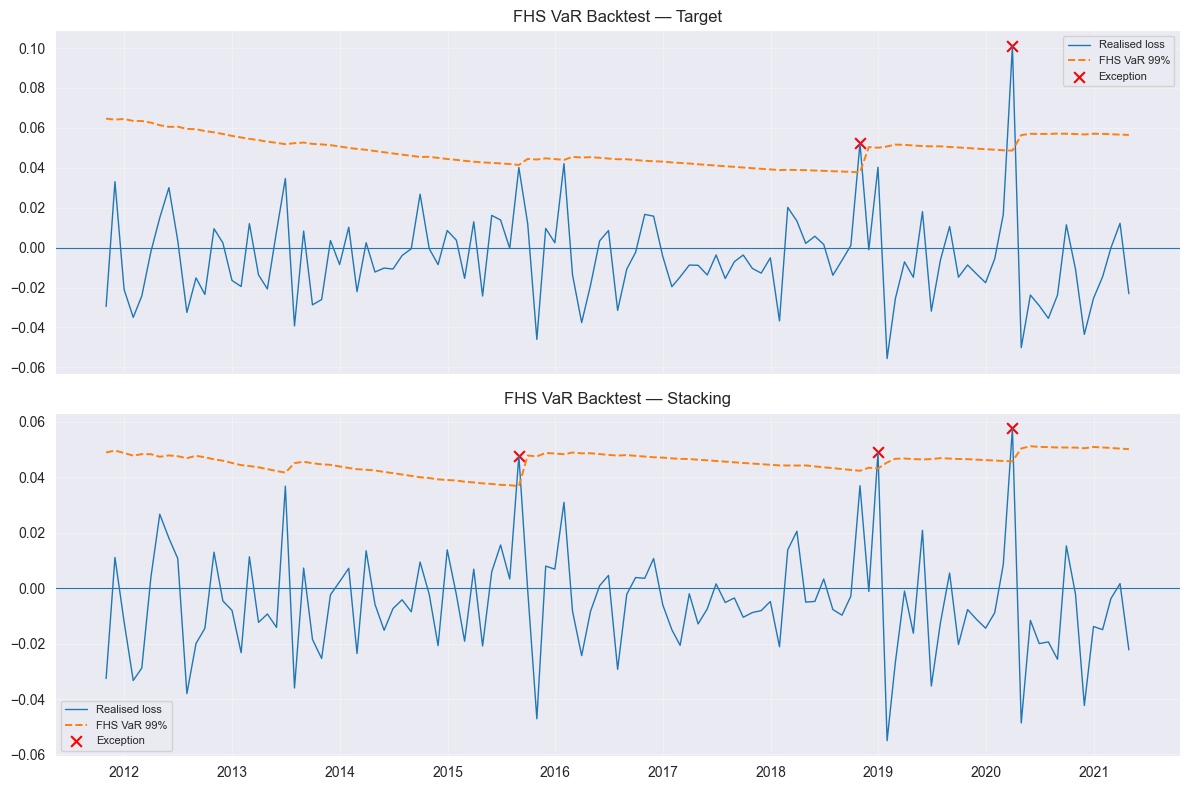

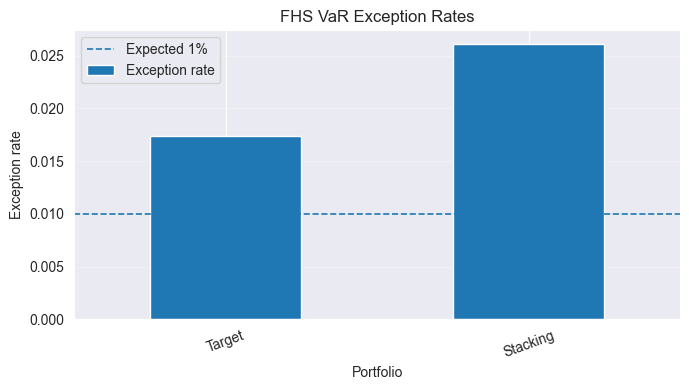

In [60]:
MIN_HIST = 24

def fhs_var_es(past_returns, current_vol, confidence=0.99):
    r = np.asarray(past_returns, dtype=float)
    r = r[np.isfinite(r)]
    if r.size < 5:
        return np.nan, np.nan

    vols = np.array([r[:k].std(ddof=1) if k >= 2 else r.std(ddof=0)
                     for k in range(1, len(r) + 1)])
    vols = np.maximum(vols, 1e-10)

    residuals = r / vols
    scaled    = residuals * current_vol
    losses    = -scaled

    var = np.quantile(losses, confidence)
    es  = losses[losses >= var].mean() if (losses >= var).any() else var
    return var, es


def kupiec_pof(n_exc, n_obs, alpha=0.01):
    if n_obs <= 0:
        return np.nan, np.nan
    x, n  = int(n_exc), int(n_obs)
    p_hat = x / n
    ll_null = (n - x) * np.log(max(1 - alpha, 1e-300)) + x * np.log(max(alpha, 1e-300))
    ll_emp  = 0.0 if x in (0, n) else (
        (n - x) * np.log(1 - p_hat) + x * np.log(p_hat))
    lr = -2.0 * (ll_null - ll_emp)
    return lr, 1.0 - chi2.cdf(lr, df=1)


print("Filtered Historical Simulation — sequential VaR backtesting")
print("-" * 60)

fhs_records = []
fhs_summary = []

for col in portfolio_monthly.columns:
    series = portfolio_monthly[col].dropna()
    n      = len(series)

    for t in range(MIN_HIST, n):
        past          = series.iloc[:t].to_numpy()
        current_vol   = past.std(ddof=1) if len(past) >= 2 else abs(past).mean()
        current_vol   = max(current_vol, 1e-10)
        realised_loss = -series.iloc[t]

        var_t, es_t = fhs_var_es(past, current_vol, CONFIDENCE)
        fhs_records.append({
            "Date": series.index[t],
            "Portfolio": col,
            "Realised loss": realised_loss,
            "FHS VaR 99%": var_t,
            "FHS ES 99%": es_t,
            "Exception": bool(realised_loss > var_t)
        })

    bt    = pd.DataFrame([r for r in fhs_records if r["Portfolio"] == col])
    n_bt  = len(bt)
    n_exc = int(bt["Exception"].sum()) if n_bt else 0
    exc_r = n_exc / n_bt if n_bt else np.nan
    lr, pv = kupiec_pof(n_exc, n_bt, alpha=ALPHA)

    fhs_summary.append({
        "Portfolio": col, "Backtest months": n_bt,
        "Exceptions": n_exc,
        "Expected": round(ALPHA * n_bt, 2),
        "Exception rate": exc_r,
        "Kupiec LR": round(lr, 4) if not np.isnan(lr) else np.nan,
        "Kupiec p-value": round(pv, 4) if not np.isnan(pv) else np.nan,
        "Avg FHS VaR": bt["FHS VaR 99%"].mean() if n_bt else np.nan,
        "Latest FHS VaR": bt["FHS VaR 99%"].iloc[-1] if n_bt else np.nan
    })

    print(f"  {col}: exceptions {n_exc}/{n_bt}  rate={exc_r:.2%}  Kupiec p={pv:.4f}")

fhs_bt_df  = pd.DataFrame(fhs_records)
fhs_sum_df = pd.DataFrame(fhs_summary)
print()
print(fhs_sum_df.to_string(index=False))

fig, axes = plt.subplots(len(portfolio_monthly.columns), 1,
                         figsize=(12, 4 * len(portfolio_monthly.columns)),
                         sharex=True)
if len(portfolio_monthly.columns) == 1:
    axes = [axes]
for ax, col in zip(axes, portfolio_monthly.columns):
    sub = fhs_bt_df[fhs_bt_df["Portfolio"] == col].sort_values("Date")
    ax.plot(sub["Date"], sub["Realised loss"], lw=1.0, label="Realised loss")
    ax.plot(sub["Date"], sub["FHS VaR 99%"],  lw=1.4, linestyle="--", label="FHS VaR 99%")
    exc = sub[sub["Exception"]]
    if len(exc):
        ax.scatter(exc["Date"], exc["Realised loss"], marker="x", s=60,
                   color="red", label="Exception")
    ax.axhline(0, lw=0.8)
    ax.set_title(f"FHS VaR Backtest — {col}")
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
show(fig)

fig, ax = plt.subplots(figsize=(7, 4))
fhs_sum_df.set_index("Portfolio")["Exception rate"].plot(kind="bar", ax=ax)
ax.axhline(ALPHA, lw=1.2, linestyle="--", label=f"Expected {ALPHA:.0%}")
ax.set_title("FHS VaR Exception Rates")
ax.set_ylabel("Exception rate")
ax.legend(); ax.tick_params(axis="x", rotation=20)
ax.grid(True, axis="y", alpha=0.3)
show(fig)


### 3. Historical Stress VaR (Stress Test)

VaR and ES are computed as empirical quantiles of monthly losses within the **January 2008 – June 2009** GFC window. Results represent a conditional lower bound — the loss incurred had the strategy been live during the crisis — not a forecast of future tail losses.


No data in 2008-01-01 – 2009-06-30. OOS runs 2009-10-31 to 2021-04-30.
Falling back to the first 18 months of the OOS sample.
Stress window: 2009-10-31 to 2011-03-31
Months in stress window: 18

Historical Stress VaR / ES — stress window
------------------------------------------------------------
  Target          Stress VaR=6.4594%  Stress ES=7.2130%
  Stacking        Stress VaR=2.8783%  Stress ES=3.0654%


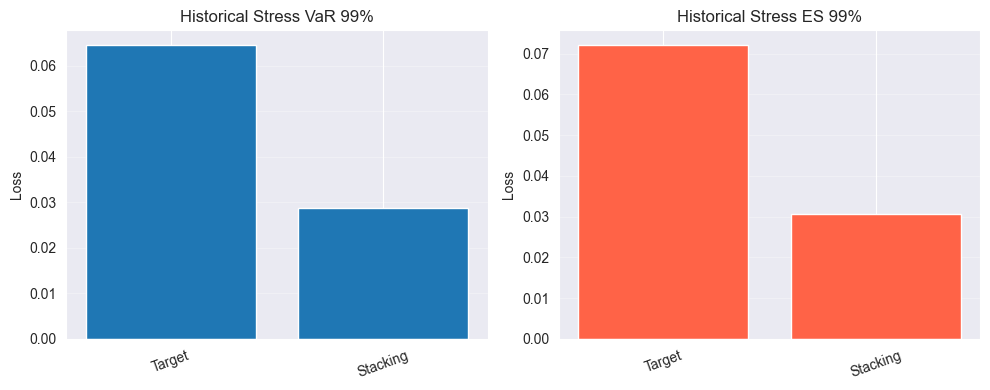

In [61]:
STRESS_START = "2008-01-01"
STRESS_END   = "2009-06-30"

stress_mask   = (
    (portfolio_monthly.index >= pd.Timestamp(STRESS_START)) &
    (portfolio_monthly.index <= pd.Timestamp(STRESS_END))
)
stress_window = portfolio_monthly.loc[stress_mask]

if len(stress_window) == 0:
    first = portfolio_monthly.index.min().date()
    last  = portfolio_monthly.index.max().date()
    print(f"No data in {STRESS_START} – {STRESS_END}. OOS runs {first} to {last}.")
    print("Falling back to the first 18 months of the OOS sample.")
    stress_window = portfolio_monthly.iloc[:18]

print(f"Stress window: {stress_window.index.min().date()} to {stress_window.index.max().date()}")
print(f"Months in stress window: {len(stress_window)}")


def historical_stress_var_es(returns, confidence=0.99):
    r = np.asarray(returns, dtype=float)
    r = r[np.isfinite(r)]
    if r.size == 0:
        return np.nan, np.nan
    losses = -r
    var = np.quantile(losses, confidence)
    es  = losses[losses >= var].mean() if (losses >= var).any() else var
    return var, es


print(f"\nHistorical Stress VaR / ES — stress window")
print("-" * 60)
stress_results = {}
for col in stress_window.columns:
    v, e = historical_stress_var_es(stress_window[col], CONFIDENCE)
    stress_results[col] = dict(var=v, es=e)
    print(f"  {col:<15} Stress VaR={v:.4%}  Stress ES={e:.4%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
names = list(stress_results.keys())
axes[0].bar(names, [stress_results[n]["var"] for n in names])
axes[0].set_title("Historical Stress VaR 99%")
axes[0].set_ylabel("Loss"); axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].bar(names, [stress_results[n]["es"] for n in names], color="tomato")
axes[1].set_title("Historical Stress ES 99%")
axes[1].set_ylabel("Loss"); axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(True, axis="y", alpha=0.3)
show(fig)


### 4. Final Comparison




In [62]:
# ════════════════════════════════════════════════════════════════════
# Cross-model comparison — unified metrics
# ════════════════════════════════════════════════════════════════════
comparison_df = pd.DataFrame([
    {
        'Model':       m['label'],
        'Corr':        f"{m['corr']:.3f}",
        'TEV (%)':     f"{m['tev']*100:.2f}",
        'IR':          f"{m['ir']:+.3f}",
        'Sharpe':      f"{m['sharpe_rep']:.2f}",
        'MaxDD (%)':   f"{m['max_dd_rep']*100:.1f}",
        'Ann.Ret (%)': f"{m['ann_ret_rep']*100:.2f}",
        'Ann.Vol (%)': f"{m['ann_vol_rep']*100:.2f}",
        'AnnTO':       f"{m['annual_turnover']:.2f}" if np.isfinite(m['annual_turnover']) else 'n/a',
        'MSE':         f"{m['mse']:.2e}",
    }
    for m in [metrics_MS_dict, metrics_K_dict, metrics_stack_dict]
]).set_index('Model')

print("\n" + "=" * 80)
print("CROSS-MODEL COMPARISON — Unified metrics")
print("=" * 80)
display(comparison_df)


CROSS-MODEL COMPARISON — Unified metrics


,Corr,TEV (%),IR,Sharpe,MaxDD (%),Ann.Ret (%),Ann.Vol (%),AnnTO,MSE
Model,,,,,,,,,
Markov Switching EN (Dirichlet-NG),0.872,3.94,-0.035,0.78,10.8,5.36,6.85,5.00,2.98e-05
Kalman Filter (regime-aware),0.916,3.23,+0.098,0.77,11.8,5.76,7.52,1.69,2.00e-05
Soft Bayesian Stack,0.914,3.27,+0.055,0.78,11.7,5.62,7.23,0.50,2.06e-05
